# DineScope — Task 4: Location-Based Analysis
## Verification, Evaluation & Demonstration

This notebook verifies the outputs created by the Python implementation in `src/task_4_location_analysis/`. It does not duplicate data cleaning, feature engineering, geospatial processing, statistical analysis or recommendation generation. It loads the saved datasets, reports and figures, then checks the consistency of the generated outputs and presents the results.

## 1. Setup and project paths
Run from the project root or the `notebooks/` folder.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

# Locate the DineScope project root

def find_project_root() -> Path:
    cwd = Path.cwd()

    for p in [cwd, *cwd.parents]:
        if (p / "src").is_dir() and (p / "data").is_dir():
            return p

    raise FileNotFoundError(
        "Could not locate the DineScope project root."
    )


PROJECT_ROOT = find_project_root()

# Define project directories
DATA = PROJECT_ROOT / "data" / "processed" / "task_4_location_analysis"
FEATURES = DATA / "features"
REPORTS = PROJECT_ROOT / "reports" / "task_4"
INTERACTIVE = REPORTS / "interactive_explorer"
FIGURES = PROJECT_ROOT / "outputs" / "figures" / "task_4"
SOURCE = PROJECT_ROOT / "src" / "task_4_location_analysis"

print("=" * 75)
print("DINESCOPE - RESTAURANT INTELLIGENCE & ANALYTICS")
print("TASK 04: LOCATION-BASED ANALYSIS")
print("NOTEBOOK: LOCATION-BASED ANALYSIS VERIFICATION")
print("=" * 75)

print("Project root:", PROJECT_ROOT)
print("Processed data:", DATA)
print("Feature datasets:", FEATURES)
print("Reports:", REPORTS)
print("Figures:", FIGURES)
print("Source programs:", SOURCE)

print("\nProject directories validated successfully.")

DINESCOPE - RESTAURANT INTELLIGENCE & ANALYTICS
TASK 04: LOCATION-BASED ANALYSIS
NOTEBOOK: LOCATION-BASED ANALYSIS VERIFICATION
Project root: c:\Users\kamal\OneDrive\Desktop\DineScope
Processed data: c:\Users\kamal\OneDrive\Desktop\DineScope\data\processed\task_4_location_analysis
Feature datasets: c:\Users\kamal\OneDrive\Desktop\DineScope\data\processed\task_4_location_analysis\features
Reports: c:\Users\kamal\OneDrive\Desktop\DineScope\reports\task_4
Figures: c:\Users\kamal\OneDrive\Desktop\DineScope\outputs\figures\task_4
Source programs: c:\Users\kamal\OneDrive\Desktop\DineScope\src\task_4_location_analysis

Project directories validated successfully.


## 2. Check expected artifacts
Missing files are reported so you can run the corresponding `src/` script.

In [2]:
expected_programs = [
    SOURCE / "01_location_dataset_audit.py",
    SOURCE / "02_location_data_preprocessing.py",
    SOURCE / "03_location_feature_engineering.py",
    SOURCE / "04_location_based_analysis.py",
    SOURCE / "05_geospatial_analysis_and_visualization.py",
    SOURCE / "06_location_statistical_analysis.py",
    SOURCE / "07_location_recommendation_and_decision_support.py",
    SOURCE / "08_interactive_location_explorer.py",
]

expected_artifacts = [
    DATA / "location_analysis_data.csv",
    FEATURES / "restaurant_location_features.csv",
    FEATURES / "city_location_features.csv",
    FEATURES / "locality_location_features.csv",
    FEATURES / "city_cuisine_distribution.csv",
    FEATURES / "locality_cuisine_distribution.csv",
    REPORTS / "location_dataset_audit_report.txt",
    REPORTS / "location_preprocessing_report.txt",
    REPORTS / "location_feature_engineering_report.txt",
    REPORTS / "geospatial_analysis_report.txt",
    REPORTS / "location_statistical_analysis_report.txt",
    REPORTS / "location_recommendation_report.txt",
    REPORTS / "location_city_recommendations.csv",
    REPORTS / "location_locality_recommendations.csv",
    REPORTS / "restaurant_geospatial_clusters.csv",
    REPORTS / "location_statistical_test_results.csv",
    FIGURES / "01_global_restaurant_distribution.png",
    FIGURES / "02_india_restaurant_distribution.png",
    FIGURES / "03_city_geographical_distribution.png",
    FIGURES / "04_geographical_dbscan_clusters.png",
    FIGURES / "05_india_geographical_clusters.png",
    FIGURES / "06_coordinate_overlap_analysis.png",
    FIGURES / "07_city_rating_comparison.png",
    FIGURES / "08_price_rating_comparison.png",
    FIGURES / "09_cuisine_diversity_rating.png",
    FIGURES / "10_restaurant_concentration_rating_coverage.png",
    FIGURES / "11_city_recommendation_ranking.png",
    FIGURES / "12_locality_recommendation_ranking.png",
    FIGURES / "13_recommendation_component_analysis.png",
    FIGURES / "14_city_rating_shrinkage_comparison.png",
]

program_status = pd.DataFrame({
    "Program": [p.name for p in expected_programs],
    "Exists": [p.is_file() for p in expected_programs]
})
artifact_status = pd.DataFrame({
    "Artifact": [p.name for p in expected_artifacts],
    "Exists": [p.is_file() for p in expected_artifacts]
})

print("SOURCE PROGRAMS")
display(program_status)
print("EXPECTED OUTPUT ARTIFACTS")
display(artifact_status)

missing_programs = program_status.loc[~program_status["Exists"], "Program"].tolist()
missing_artifacts = artifact_status.loc[~artifact_status["Exists"], "Artifact"].tolist()

if missing_programs:
    print("Missing source programs:", missing_programs)
if missing_artifacts:
    print("Missing expected artifacts:", missing_artifacts)
if not missing_programs and not missing_artifacts:
    print("All expected Task 4 programs and principal artifacts are available.")

SOURCE PROGRAMS


,Program,Exists
0,01_location_dataset_audit.py,True
1,02_location_data_preprocessing.py,True
2,03_location_feature_engineering.py,True
3,04_location_based_analysis.py,True
4,05_geospatial_analysis_and_visualization.py,True
5,06_location_statistical_analysis.py,True
6,07_location_recommendation_and_decision_suppor...,True
7,08_interactive_location_explorer.py,True


EXPECTED OUTPUT ARTIFACTS


,Artifact,Exists
0,location_analysis_data.csv,True
1,restaurant_location_features.csv,True
2,city_location_features.csv,True
3,locality_location_features.csv,True
4,city_cuisine_distribution.csv,True
5,locality_cuisine_distribution.csv,True
6,location_dataset_audit_report.txt,True
7,location_preprocessing_report.txt,True
8,location_feature_engineering_report.txt,True
9,geospatial_analysis_report.txt,True


All expected Task 4 programs and principal artifacts are available.


## 3. Verify processed location data
The location task preserves all 9,551 restaurant records. Unlike the supervised rating-prediction task, unrated restaurants remain part of the location-analysis dataset. Zero ratings are represented as missing values for rating-based analysis.

In [3]:
main_path = DATA / "location_analysis_data.csv"
main_df = pd.read_csv(main_path) if main_path.exists() else None

if main_df is not None:
    print("Processed dataset shape:", main_df.shape)
    print("Unique restaurant IDs:", main_df["Restaurant ID"].nunique())
    print("Rated restaurants:", main_df["Aggregate rating"].notna().sum())
    print("Unrated restaurants:", main_df["Aggregate rating"].isna().sum())
    print("Unique cities:", main_df["City"].nunique())
    print("Unique locality names:", main_df["Locality"].nunique())
    print("Unique country codes:", main_df["Country Code"].nunique())

    if "Price range" in main_df.columns:
        print("\nPrice range distribution")
        display(
            main_df["Price range"]
            .value_counts(dropna=False)
            .sort_index()
            .rename_axis("Price range")
            .reset_index(name="Restaurant count")
        )
else:
    print("Processed location dataset is unavailable.")

Processed dataset shape: (9551, 27)
Unique restaurant IDs: 9551
Rated restaurants: 7403
Unrated restaurants: 2148
Unique cities: 141
Unique locality names: 1208
Unique country codes: 15

Price range distribution


,Price range,Restaurant count
0,1,4444
1,2,3113
2,3,1408
3,4,586


### 3.1 Dataset audit summary
The audit identified 9,551 restaurants across 15 countries and 141 cities. The dataset contains 7,403 rated and 2,148 unrated restaurants. Coordinate pairs were checked for validity and overlap; shared coordinates are not automatically treated as data errors.

In [4]:
audit_summary_path = REPORTS / "location_dataset_audit_summary.csv"
if audit_summary_path.exists():
    audit_summary = pd.read_csv(audit_summary_path)
    display(audit_summary)
else:
    print("Dataset audit summary is unavailable.")

,Metric,Value
0,Total Restaurants,9551
1,Total Columns,21
2,Duplicate Rows,0
3,Duplicate Restaurant IDs,0
4,Unique Restaurants,9551
5,Unique Countries,15
6,Unique Cities,141
7,Unique Localities,1208
8,Missing Cities,0
9,Missing Localities,0


## 4. Verify preprocessing outputs
The preprocessing stage retains the restaurant records, corrects known city-encoding issues, converts numeric fields, treats zero ratings as unrated, and creates location-related helper fields. Nine missing cuisine entries were represented as `Unknown`.

In [5]:
preprocessing_files = {
    "Preprocessing summary": REPORTS / "location_preprocessing_summary.csv",
    "Preprocessing data quality": REPORTS / "location_preprocessing_data_quality.csv",
    "Preprocessing report": REPORTS / "location_preprocessing_report.txt",
}

for label, path in preprocessing_files.items():
    print(label, ":", "Available" if path.exists() else "Missing")
    if path.suffix.lower() == ".csv" and path.exists():
        display(pd.read_csv(path))
    elif path.suffix.lower() == ".txt" and path.exists():
        print(path.read_text(encoding="utf-8")[:5000])

Preprocessing summary : Available


,Metric,Value
0,Original Records,9551
1,Final Records,9551
2,Rows Removed,0
3,Unique Restaurants,9551
4,Unique Cities,141
5,Unique Localities,1208
6,Missing City Values Before Cleaning,0
7,Missing Locality Values Before Cleaning,0
8,Missing Address Values Before Cleaning,0
9,Valid Coordinates,9551


Preprocessing data quality : Available


,Column,Missing_Values,Data_Type,Unique_Values
0,Source Row Index,0,int64,9551
1,Restaurant ID,0,int64,9551
2,Restaurant Name,0,string,7446
3,Country Code,0,int64,15
4,City,0,string,141
5,Address,0,string,8918
6,Locality,0,string,1208
7,Locality Verbose,0,string,1265
8,Longitude,0,float64,8120
9,Latitude,0,float64,8677


Preprocessing report : Available
DINESCOPE - RESTAURANT INTELLIGENCE & ANALYTICS
TASK 04: LOCATION-BASED ANALYSIS
PROGRAM 02: LOCATION DATA PREPROCESSING

PREPROCESSING SUMMARY

Original Records: 9551
Final Records: 9551
Rows Removed: 0
Unique Restaurants: 9551
Unique Cities: 141
Unique Localities: 1208
Missing City Values Before Cleaning: 0
Missing Locality Values Before Cleaning: 0
Missing Address Values Before Cleaning: 0
Valid Coordinates: 9551
Invalid or Incomplete Coordinates: 0
Rows Sharing Coordinate Pairs: 1075
Unique Coordinate Pairs: 8705
Unrated Restaurants: 2148
Rated Restaurants: 7403
Missing Cuisine Values Before Cleaning: 9
Restaurants Without Known Cuisine: 9
Invalid Price Ranges: 0
Negative Average Costs: 0
Negative Votes: 0

CITY CORRECTIONS
-----------------------------------------------------------------
Bras�_lia: 20 records corrected
S��o Paulo: 20 records corrected
��stanbul: 14 records corrected

PREPROCESSING COMPLETED



## 5. Review location feature engineering
Feature engineering generated restaurant-level, city-level and locality-level features, cuisine distributions, currency-aware cost features, and restaurant concentration summaries. Locality groups are city-locality combinations; repeated locality names across cities are expected.

In [6]:
feature_files = [
    "restaurant_location_features.csv",
    "city_location_features.csv",
    "locality_location_features.csv",
    "city_cuisine_distribution.csv",
    "locality_cuisine_distribution.csv",
    "city_currency_cost_features.csv",
    "locality_currency_cost_features.csv",
    "city_restaurant_density.csv",
    "locality_restaurant_density.csv",
]

feature_rows = []
for filename in feature_files:
    path = FEATURES / filename
    if path.exists():
        frame = pd.read_csv(path)
        feature_rows.append({
            "Dataset": filename,
            "Rows": len(frame),
            "Columns": len(frame.columns),
        })
    else:
        feature_rows.append({
            "Dataset": filename,
            "Rows": None,
            "Columns": None,
        })

display(pd.DataFrame(feature_rows))

feature_summary_path = REPORTS / "location_feature_engineering_summary.csv"
validation_path = REPORTS / "location_feature_validation_report.csv"

if feature_summary_path.exists():
    print("Feature engineering summary")
    display(pd.read_csv(feature_summary_path))

if validation_path.exists():
    print("Feature validation report")
    display(pd.read_csv(validation_path))

,Dataset,Rows,Columns
0,restaurant_location_features.csv,9551,36
1,city_location_features.csv,141,26
2,locality_location_features.csv,1265,22
3,city_cuisine_distribution.csv,1850,4
4,locality_cuisine_distribution.csv,7914,5
5,city_currency_cost_features.csv,141,8
6,locality_currency_cost_features.csv,1265,9
7,city_restaurant_density.csv,141,4
8,locality_restaurant_density.csv,1265,7


Feature engineering summary


,Metric,Value
0,Total Restaurants,9551.00
1,Total Cities,141.00
2,Total Localities,1265.00
3,City-Cuisine Combinations,1850.00
4,Locality-Cuisine Combinations,7914.00
5,City-Currency Groups,141.00
6,Locality-Currency Groups,1265.00
7,Total Restaurant Cuisine Assignments,19705.00
8,Average Rating Across Rated Restaurants,3.44
9,Total City Restaurant Records,9551.00


Feature validation report


,Validation,Status
0,Original restaurant count preserved,PASS
1,City features generated,PASS
2,Locality features generated,PASS
3,City cuisine features generated,PASS
4,Locality cuisine features generated,PASS
5,Currency-aware cost features generated,PASS
6,City restaurant counts reconcile,PASS
7,Locality restaurant counts reconcile,PASS
8,Restaurant IDs remain unique,PASS
9,Rating values remain within valid range,PASS


## 6. Review location-based analysis
The location-based analysis summarizes restaurant distributions, rating patterns, price distributions, cuisine diversity, cost patterns and location-level comparisons. These outputs are descriptive analyses of the supplied dataset.

In [7]:
location_report_files = [
    "location_analysis_summary.csv",
    "location_city_distribution.csv",
    "location_locality_distribution.csv",
    "location_country_summary.csv",
    "location_coordinate_summary.csv",
    "location_cuisine_distribution.csv",
    "location_price_distribution.csv",
    "location_rating_distribution.csv",
    "location_rating_coverage_analysis.csv",
    "location_key_insights.csv",
]

for filename in location_report_files:
    path = REPORTS / filename
    if path.exists():
        print("\n", filename)
        display(pd.read_csv(path).head(15))
    else:
        print("Missing:", filename)


 location_analysis_summary.csv


,Metric,Value
0,Total Restaurants,9551.00
1,Cities Analyzed,141.00
2,Localities Analyzed,1265.00
3,Top 3 City Restaurant Share (%),80.32
4,Top 10 City Restaurant Share (%),84.31
5,Eligible Cities for Rating Comparison,82.00
6,Eligible Localities for Rating Comparison,296.00
7,City-Cuisine Records,1850.00
8,Locality-Cuisine Records,7914.00
9,Cities with Cost Data,141.00



 location_city_distribution.csv


,City,Restaurant_Count,Average_Rating,Average_Price_Range,Average_Cost,Average_Votes,Restaurants_With_Coordinates
0,New Delhi,5473,2.44,1.62,596.09,114.81,5473
1,Gurgaon,1118,2.65,1.86,714.02,118.21,1118
2,Noida,1080,2.04,1.60,539.49,68.04,1080
3,Faridabad,251,1.87,1.45,447.61,25.84,251
4,Ghaziabad,25,2.85,1.80,602.00,94.64,25
5,Bhubaneshwar,21,3.98,1.86,678.57,202.05,21
6,Lucknow,21,4.20,2.57,859.52,434.76,21
7,Guwahati,21,4.19,2.52,821.43,236.38,21
8,Ahmedabad,21,4.16,2.57,857.14,584.10,21
9,Amritsar,21,3.69,1.81,480.95,174.52,21



 location_locality_distribution.csv


,City,Locality,Restaurant_Count,Average_Rating,Average_Price_Range,Average_Cost,Average_Votes
0,New Delhi,Connaught Place,122,3.69,2.60,1175.00,1050.07
1,New Delhi,Rajouri Garden,99,3.59,2.20,855.05,259.52
2,New Delhi,Shahdara,87,1.41,1.14,290.80,7.69
3,New Delhi,Defence Colony,86,3.21,1.93,741.28,181.37
4,New Delhi,Pitampura,85,2.87,1.47,449.41,47.64
5,New Delhi,Mayur Vihar Phase 1,84,2.03,1.30,372.62,22.52
6,New Delhi,Malviya Nagar,84,3.42,1.77,633.33,143.90
7,New Delhi,Rajinder Nagar,81,2.94,1.43,439.75,63.84
8,New Delhi,Safdarjung,80,2.80,1.68,580.00,110.46
9,New Delhi,Satyaniketan,79,3.48,1.62,537.97,208.33


... (10 outputs left out)


 location_rating_coverage_analysis.csv


,Country Code,City,Restaurant_Count,Rated_Restaurant_Count,Rating_Coverage_Percentage
0,1,Bhubaneshwar,21,21,100.0
1,1,Guwahati,21,21,100.0
2,1,Lucknow,21,21,100.0
3,1,Ahmedabad,21,21,100.0
4,1,Amritsar,21,21,100.0
5,1,Aurangabad,20,20,100.0
6,1,Allahabad,20,20,100.0
7,1,Agra,20,20,100.0
8,1,Bangalore,20,20,100.0
9,1,Coimbatore,20,20,100.0



 location_key_insights.csv


,Insight_Category,Finding,Supporting_Value,Unit
0,Restaurant Concentration,New Delhi has the highest restaurant count wit...,57.30,Percentage of dataset
1,Highest Rated City,London has the highest average rating among el...,4.54,Average rating
2,Highest Rated Locality,"Jubilee Hills, Hyderabad has the highest avera...",4.39,Average rating
3,Cuisine Diversity,New Delhi has the highest number of distinct c...,81.00,Distinct cuisine labels
4,Rating Coverage,Bhubaneshwar has the highest rating coverage a...,100.00,Percentage


## 7. Review geospatial analysis and DBSCAN
The geospatial analysis identified 9,054 usable coordinate records and excluded 497 suspicious zero-coordinate records from spatial processing. DBSCAN produced 172 clusters, with 7,463 records assigned to clusters and 1,591 classified as noise. Cluster labels and summaries are saved as analysis outputs; a conventional predictive model file is not required for this task.

In [8]:
geospatial_paths = {
    "Global summary": REPORTS / "geospatial_global_summary.csv",
    "Country summary": REPORTS / "geospatial_country_summary.csv",
    "City coordinate summary": REPORTS / "geospatial_city_coordinate_summary.csv",
    "Cluster summary": REPORTS / "geospatial_cluster_summary.csv",
    "Cluster rating analysis": REPORTS / "geospatial_cluster_rating_analysis.csv",
    "Coordinate overlaps": REPORTS / "geospatial_coordinate_overlaps.csv",
    "Suspicious coordinates": REPORTS / "geospatial_suspicious_coordinates.csv",
}

for label, path in geospatial_paths.items():
    print("\n" + label)
    if path.exists():
        frame = pd.read_csv(path)
        print("Shape:", frame.shape)
        display(frame.head(10))
    else:
        print("Missing:", path.name)

clustered_path = REPORTS / "restaurant_geospatial_clusters.csv"
if clustered_path.exists():
    clustered_df = pd.read_csv(clustered_path)
    cluster_col = next((c for c in clustered_df.columns if "cluster" in c.lower()), None)
    if cluster_col:
        labels = clustered_df[cluster_col]
        print("Usable geospatial records:", len(clustered_df))
        print("Assigned cluster records:", int((labels != -1).sum()))
        print("Noise records:", int((labels == -1).sum()))
        print("Cluster count excluding noise:", int(labels[labels != -1].nunique()))


Global summary
Shape: (4, 2)


,Metric,Value
0,Total valid coordinate records,9054
1,Unique coordinate pairs,8704
2,Unique countries,15
3,Unique cities,141



Country summary
Shape: (15, 8)


,Country Code,Restaurant_Count,Unique_Cities,Average_Latitude,Average_Longitude,Rated_Restaurant_Count,Average_Rating,Unique_Coordinate_Pairs
0,1,8157,43,28.023965,77.278033,6302,3.347080,7809
1,216,434,35,35.616102,-92.967923,431,4.032251,434
2,215,80,4,53.354745,-1.865950,79,4.139241,78
3,214,60,3,24.995730,55.026086,60,4.233333,60
4,189,60,6,-28.605570,24.905097,60,4.210000,60
5,30,60,3,-20.780126,-45.932703,55,4.105455,60
6,148,40,2,-38.156311,174.770018,40,4.262500,40
7,208,34,2,40.369036,31.256299,34,4.300000,34
8,14,24,23,-33.764464,144.601833,24,3.658333,24
9,162,22,9,14.518302,121.036126,22,4.468182,22



City coordinate summary
Shape: (141, 7)


,Country Code,City,Restaurant_Count,Latitude_Center,Longitude_Center,Rated_Restaurant_Count,Average_Rating
0,1,New Delhi,5240,28.616484,77.189972,3975,3.298314
1,1,Gurgaon,1070,28.466911,77.071548,874,3.332380
2,1,Noida,987,28.566832,77.281967,677,3.158198
3,1,Faridabad,229,28.433279,77.311695,147,3.102721
4,1,Ghaziabad,25,28.637475,77.362470,23,3.100000
5,1,Ahmedabad,21,23.036910,72.531324,21,4.161905
6,1,Jaipur,20,26.895981,75.794475,20,4.130000
7,1,Mumbai,20,19.114387,72.848456,20,4.085000
8,1,Kolkata,20,22.541206,88.372488,20,4.255000
9,1,Indore,20,22.736775,75.888197,20,3.970000


... (5 outputs left out)

,Latitude,Longitude,Restaurant_Count,City_Count,Restaurant_IDs,Cities
0,28.574309,77.353663,16,1,"18371434, 18383477, 18396179, 18361221, 183834...",Noida
1,28.551456,77.251426,9,1,"304906, 304915, 304913, 304923, 309738, 182771...",New Delhi
2,28.574300,77.353574,9,1,"18383509, 18349905, 18383479, 18383460, 183379...",Noida
3,28.597103,77.364833,8,1,"18371420, 312187, 523, 2480, 828, 308578, 3087...",Noida
4,28.625445,77.218187,7,1,"301523, 2729, 2728, 2730, 2727, 2731, 2725",New Delhi
5,28.550347,77.121795,6,1,"18384135, 18337772, 18336491, 18306524, 183344...",New Delhi
6,28.569040,77.185331,6,1,"4357, 3379, 3264, 4368, 4356, 3378",New Delhi
7,28.592153,77.162222,5,1,"18433910, 18435287, 18433897, 18435289, 18433864",New Delhi
8,28.556503,77.164438,5,1,"4499, 4235, 4500, 4234, 4501",New Delhi
9,28.495208,77.088688,5,1,"308020, 306132, 306131, 306946, 308022",Gurgaon



Suspicious coordinates
Shape: (497, 37)


,Source Row Index,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,...,Known Cuisine Count,Has Known Cuisine,Rated Restaurant,High Rated Restaurant,Low Rated Restaurant,Premium Price Restaurant,Budget Price Restaurant,Has Valid Coordinates,Has Multiple Cuisine Categories,Coordinate_Quality_Status
0,625,3400341,Rangrezz Restaurant,1,Agra,"E-20, Shopping Arcade, Sadar Bazaar, Agra Cant...",Agra Cantt,"Agra Cantt, Agra",0.0,0.0,...,2,True,True,False,False,False,False,True,True,Suspicious - Zero Coordinates
1,629,3400325,MoMo Cafe,1,Agra,"Courtyard by Marriott Agra, Phase 2, Fatehabad...","Courtyard by Marriott Agra, Tajganj","Courtyard by Marriott Agra, Tajganj, Agra",0.0,0.0,...,2,True,True,True,False,True,False,True,True,Suspicious - Zero Coordinates
2,632,3400348,G Thal,1,Agra,"3/20, KPS Tower, Near Tulsi Talkies, Bypass Ro...",Khandari,"Khandari, Agra",0.0,0.0,...,3,True,True,False,False,True,False,True,True,Suspicious - Zero Coordinates
3,638,3400350,Bon Barbecue,1,Agra,"Parador Hotel, 3A-3B, Phase 1, Fatehabad Road,...",Tajganj,"Tajganj, Agra",0.0,0.0,...,3,True,True,False,False,True,False,True,True,Suspicious - Zero Coordinates
4,639,3400391,Chapter 1 Cafe,1,Agra,"1374 K/1375 K, 2nd floor, Dinesh Nagar, Fatehb...",Tajganj,"Tajganj, Agra",0.0,0.0,...,5,True,True,False,False,False,True,True,True,Suspicious - Zero Coordinates
5,642,3400326,Tea'se Me - Rooftop Tea Boutique,1,Agra,"Near Purani Mandi Crossing,Fatehabad Road, Taj...",Tajganj,"Tajganj, Agra",0.0,0.0,...,4,True,True,True,False,True,False,True,True,Suspicious - Zero Coordinates
6,668,2400193,Dewsis,1,Allahabad,"2, MG Marg, Opposite Hanuman Mandir, Civil Lin...",Civil Lines,"Civil Lines, Allahabad",0.0,0.0,...,2,True,True,False,False,True,False,True,True,Suspicious - Zero Coordinates
7,670,17960073,Hotel Ravisha Continental,1,Allahabad,"57 A, Purshottamdas Tandon Marg, Civil Lines, ...",Civil Lines,"Civil Lines, Allahabad",0.0,0.0,...,3,True,True,False,False,True,False,True,True,Suspicious - Zero Coordinates
8,673,2400403,Pind Balluchi,1,Allahabad,"5-A, Sardar Patel Marg, Civil Lines, Allahabad",Civil Lines,"Civil Lines, Allahabad",0.0,0.0,...,2,True,True,False,False,True,False,True,True,Suspicious - Zero Coordinates
9,674,2400349,Pizza Hut,1,Allahabad,"31/31, Sardar Patel Marg, Civil Lines, Allahabad",Civil Lines,"Civil Lines, Allahabad",0.0,0.0,...,2,True,True,False,False,True,False,True,True,Suspicious - Zero Coordinates


Usable geospatial records: 9054
Assigned cluster records: 7463
Noise records: 1591
Cluster count excluding noise: 172


## 8. Review statistical analysis
The statistical program evaluates rating differences across cities, localities and price ranges, and selected relationships using non-parametric tests and rank correlation. Statistical significance does not establish causality.

In [9]:
statistical_paths = [
    "location_statistical_analysis_summary.csv",
    "location_statistical_city_ratings.csv",
    "location_statistical_locality_ratings.csv",
    "location_statistical_price_ratings.csv",
    "location_statistical_cuisine_rating.csv",
    "location_statistical_rating_coverage.csv",
    "location_statistical_votes_rating.csv",
    "location_statistical_test_results.csv",
    "location_statistical_insights.csv",
]

for filename in statistical_paths:
    path = REPORTS / filename
    print("\n", filename)
    if path.exists():
        frame = pd.read_csv(path)
        print("Shape:", frame.shape)
        display(frame.head(20))
    else:
        print("Missing:", filename)


 location_statistical_analysis_summary.csv
Shape: (15, 2)


,Metric,Value
0,Total Restaurants,9551
1,Rated Restaurants,7403
2,Eligible Cities,82
3,Eligible Localities,176
4,Eligible Price Groups,4
5,City Groups in Kruskal-Wallis Test,10
6,Locality Groups in Kruskal-Wallis Test,30
7,Price Groups in Kruskal-Wallis Test,4
8,Budget Restaurant Sample Size,2744
9,Premium Restaurant Sample Size,575



 location_statistical_city_ratings.csv
Shape: (82, 8)


,Country Code,City,Rated_Restaurant_Count,Average_Rating,Median_Rating,Rating_Standard_Deviation,Minimum_Rating,Maximum_Rating
0,1,New Delhi,4048,3.297381,3.30,0.459298,1.9,4.9
1,1,Gurgaon,890,3.330674,3.30,0.490027,2.0,4.9
2,1,Noida,696,3.159626,3.10,0.468175,2.0,4.5
3,1,Faridabad,151,3.103311,3.00,0.364128,2.1,4.5
4,1,Ghaziabad,23,3.100000,3.20,0.458258,1.8,3.9
5,1,Ahmedabad,21,4.161905,4.20,0.285440,3.6,4.6
6,1,Bhubaneshwar,21,3.980952,4.00,0.289170,3.5,4.6
7,1,Lucknow,21,4.195238,4.20,0.323228,3.5,4.9
8,1,Guwahati,21,4.190476,4.10,0.312897,3.6,4.9
9,1,Amritsar,21,3.685714,3.60,0.255511,3.4,4.1



 location_statistical_locality_ratings.csv
Shape: (176, 7)


,Country Code,City,Locality,Rated_Restaurant_Count,Average_Rating,Median_Rating,Rating_Standard_Deviation
0,1,New Delhi,Connaught Place,119,3.779832,3.80,0.369741
1,1,New Delhi,Rajouri Garden,98,3.628571,3.70,0.506657
2,1,New Delhi,Malviya Nagar,84,3.417857,3.50,0.474446
3,1,New Delhi,Defence Colony,79,3.494937,3.60,0.450042
4,1,New Delhi,Satyaniketan,78,3.526923,3.60,0.497441
5,1,New Delhi,Rajinder Nagar,78,3.056410,3.00,0.429312
6,1,New Delhi,Pitampura,77,3.168831,3.20,0.382602
7,1,Noida,Sector 18,75,3.370667,3.50,0.476126
8,1,New Delhi,Karol Bagh,72,3.241667,3.30,0.431098
9,1,New Delhi,Kalkaji,70,3.117143,3.15,0.371043


... (8 outputs left out)


 location_statistical_test_results.csv
Shape: (7, 7)


,Analysis,Test,Statistic,P_Value,Status,Significant_At_0_05,Interpretation
0,City Rating Comparison,Kruskal-Wallis,286.621817,1.790020e-56,Completed,True,Statistically significant at 0.05
1,Locality Rating Comparison,Kruskal-Wallis,501.492440,1.420460e-87,Completed,True,Statistically significant at 0.05
2,Price Range Rating Comparison,Kruskal-Wallis,1326.066564,3.249781e-287,Completed,True,Statistically significant at 0.05
3,Budget vs Premium Rating,Mann-Whitney U,262135.000000,7.858932e-141,Completed,True,Statistically significant at 0.05
4,Cuisine Diversity vs Rating,Spearman Correlation,0.085257,4.463178e-01,Completed,False,Not statistically significant at 0.05
5,Restaurant Count vs Rating Coverage,Spearman Correlation,-0.357132,1.378900e-05,Completed,True,Statistically significant at 0.05
6,Votes vs Rating,Spearman Correlation,0.682106,0.000000e+00,Completed,True,Statistically significant at 0.05



 location_statistical_insights.csv
Shape: (4, 3)


,Category,Finding,Value
0,City Rating,London has the highest average rating among ci...,4.535
1,Locality Rating,"Macon, Macon has the highest average rating am...",4.310
2,Price Range,Price range 4 has the highest average rating a...,3.891
3,Statistical Tests,6 of 7 completed tests have p-values below 0.05.,6.000


### 8.1 Statistical test interpretation

The completed analysis reported seven statistical tests. Six were significant at the 0.05 level; the cuisine-diversity versus rating Spearman association was not statistically significant in the reported run. A very small p-value should not be reported as exactly zero, and statistical significance should be interpreted alongside sample size and practical effect.

## 9. Review location recommendation and decision support
The recommendation program uses a weighted scoring framework and a shrinkage-adjusted rating. It is a rule-based decision-support system, not a trained machine-learning prediction model.

In [10]:
recommendation_files = [
    "location_city_recommendations.csv",
    "location_locality_recommendations.csv",
    "location_city_recommendation_comparison.csv",
    "location_locality_recommendation_comparison.csv",
    "location_city_recommendation_tiers.csv",
    "location_locality_recommendation_tiers.csv",
    "location_high_quality_cities.csv",
    "location_high_quality_localities.csv",
    "location_high_coverage_cities.csv",
    "location_high_coverage_localities.csv",
    "location_top_city_restaurant_shortlist.csv",
    "location_decision_insights.csv",
    "location_recommendation_configuration.csv",
    "location_recommendation_summary.csv",
]

for filename in recommendation_files:
    path = REPORTS / filename
    print("\n", filename)
    if path.exists():
        frame = pd.read_csv(path)
        print("Shape:", frame.shape)
        display(frame.head(15))
    else:
        print("Missing:", filename)


 location_city_recommendations.csv
Shape: (82, 37)


,Country Code,City,City Key,Restaurant_Count,Rated_Restaurant_Count,High_Rated_Restaurant_Count,Low_Rated_Restaurant_Count,Average_Rating,Median_Rating,Rating_Standard_Deviation,...,Adjusted_Average_Rating,Rating_Score,Cuisine_Diversity_Score,Rating_Coverage_Score,Log_Restaurant_Count,Restaurant_Availability_Score,Recommendation_Score,Recommendation_Tier,Recommendation_Rank,Location_Type
0,216,Orlando,216_orlando,20,20,19,0,4.475000,4.40,0.286310,...,3.854015,98.780488,90.853659,57.317073,3.044522,47.560976,78.658537,Recommended,1,City
1,216,Tampa Bay,216_tampa bay,20,20,18,0,4.410000,4.45,0.317722,...,3.828015,95.731707,85.365854,57.317073,3.044522,47.560976,76.341463,Recommended,2,City
2,214,Abu Dhabi,214_abu dhabi,20,20,19,0,4.300000,4.30,0.319539,...,3.784015,89.024390,92.682927,57.317073,3.044522,47.560976,75.121951,Recommended,3,City
3,1,Ahmedabad,1_ahmedabad,21,21,16,0,4.161905,4.20,0.285440,...,3.737269,70.731707,68.902439,57.317073,3.091042,91.463415,71.829268,Recommended,4,City
4,1,Chennai,1_chennai,20,20,18,0,4.315000,4.30,0.299605,...,3.790015,91.463415,68.902439,57.317073,3.044522,47.560976,71.341463,Recommended,5,City
5,215,London,215_london,20,20,19,0,4.535000,4.55,0.288873,...,3.878015,100.000000,51.219512,57.317073,3.044522,47.560976,71.219512,Recommended,6,City
6,214,Dubai,214_dubai,20,20,17,0,4.370000,4.40,0.419398,...,3.812015,92.682927,59.146341,57.317073,3.044522,47.560976,69.878049,Recommended,7,City
7,216,Des Moines,216_des moines,20,20,18,0,4.235000,4.20,0.371731,...,3.758015,79.268293,85.365854,57.317073,3.044522,47.560976,69.756098,Recommended,8,City
8,189,Pretoria,189_pretoria,20,20,15,0,4.190000,4.15,0.343205,...,3.740015,71.951220,96.341463,57.317073,3.044522,47.560976,69.024390,Recommended,9,City
9,1,Lucknow,1_lucknow,21,21,17,0,4.195238,4.20,0.323228,...,3.750995,76.829268,42.073171,57.317073,3.091042,91.463415,68.902439,Recommended,10,City



 location_locality_recommendations.csv
Shape: (176, 33)


,Country Code,City,Locality,Location Key,Restaurant_Count,Rated_Restaurant_Count,High_Rated_Restaurant_Count,Low_Rated_Restaurant_Count,Average_Rating,Median_Rating,...,Adjusted_Average_Rating,Rating_Score,Cuisine_Diversity_Score,Rating_Coverage_Score,Log_Restaurant_Count,Restaurant_Availability_Score,Recommendation_Score,Recommendation_Tier,Recommendation_Rank,Location_Type
0,1,New Delhi,Connaught Place,1_new delhi_connaught place,122,119,32,0,3.779832,3.8,...,3.711414,97.727273,100.000000,61.363636,4.812184,100.000000,91.363636,Highly Recommended,1,Locality
1,1,New Delhi,Greater Kailash (GK) 1,1_new delhi_greater kailash (gk) 1,66,66,17,0,3.696970,3.7,...,3.616674,90.909091,96.022727,81.818182,4.204693,87.784091,89.488636,Highly Recommended,2,Locality
2,1,New Delhi,Rajouri Garden,1_new delhi_rajouri garden,99,98,24,1,3.628571,3.7,...,3.584381,89.204545,98.295455,63.068182,4.605170,99.431818,87.840909,Highly Recommended,3,Locality
3,1,Gurgaon,"Cyber Hub, DLF Cyber City","1_gurgaon_cyber hub, dlf cyber city",41,41,15,1,3.860976,3.9,...,3.683109,96.590909,98.295455,81.818182,3.737670,63.636364,87.386364,Highly Recommended,4,Locality
4,1,New Delhi,Greater Kailash (GK) 2,1_new delhi_greater kailash (gk) 2,66,66,9,1,3.553030,3.5,...,3.517716,82.386364,98.295455,81.818182,4.204693,87.784091,86.534091,Highly Recommended,5,Locality
5,1,Gurgaon,Sector 29,1_gurgaon_sector 29,38,38,16,0,3.892105,3.9,...,3.692658,97.159091,96.022727,81.818182,3.663562,59.943182,86.420455,Highly Recommended,6,Locality
6,1,New Delhi,Malviya Nagar,1_new delhi_malviya nagar,84,84,9,5,3.417857,3.5,...,3.423691,69.318182,98.295455,81.818182,4.442651,96.875000,83.125000,Highly Recommended,7,Locality
7,1,New Delhi,Khan Market,1_new delhi_khan market,44,43,14,0,3.802326,3.8,...,3.653435,93.750000,96.022727,61.931818,3.806662,68.181818,82.727273,Highly Recommended,8,Locality
8,1,Noida,"DLF Mall of India, Sector 18, Noida","1_noida_dlf mall of india, sector 18, noida",31,31,10,0,3.841935,3.9,...,3.644274,93.181818,94.602273,81.818182,3.465736,48.863636,82.329545,Highly Recommended,9,Locality
9,1,New Delhi,Satyaniketan,1_new delhi_satyaniketan,79,78,15,2,3.526923,3.6,...,3.502785,80.681818,89.204545,62.500000,4.382027,94.886364,81.590909,Highly Recommended,10,Locality



 location_city_recommendation_comparison.csv
Shape: (82, 14)


,Country Code,City,Restaurant_Count,Rated_Restaurant_Count,Average_Rating,Adjusted_Average_Rating,Calculated_Rating_Coverage,Cuisine_Diversity_Score,Rating_Score,Rating_Coverage_Score,Restaurant_Availability_Score,Recommendation_Score,Recommendation_Rank,Recommendation_Tier
0,216,Orlando,20,20,4.475000,3.854015,100.0,90.853659,98.780488,57.317073,47.560976,78.658537,1,Recommended
1,216,Tampa Bay,20,20,4.410000,3.828015,100.0,85.365854,95.731707,57.317073,47.560976,76.341463,2,Recommended
2,214,Abu Dhabi,20,20,4.300000,3.784015,100.0,92.682927,89.024390,57.317073,47.560976,75.121951,3,Recommended
3,1,Ahmedabad,21,21,4.161905,3.737269,100.0,68.902439,70.731707,57.317073,91.463415,71.829268,4,Recommended
4,1,Chennai,20,20,4.315000,3.790015,100.0,68.902439,91.463415,57.317073,47.560976,71.341463,5,Recommended
5,215,London,20,20,4.535000,3.878015,100.0,51.219512,100.000000,57.317073,47.560976,71.219512,6,Recommended
6,214,Dubai,20,20,4.370000,3.812015,100.0,59.146341,92.682927,57.317073,47.560976,69.878049,7,Recommended
7,216,Des Moines,20,20,4.235000,3.758015,100.0,85.365854,79.268293,57.317073,47.560976,69.756098,8,Recommended
8,189,Pretoria,20,20,4.190000,3.740015,100.0,96.341463,71.951220,57.317073,47.560976,69.024390,9,Recommended
9,1,Lucknow,21,21,4.195238,3.750995,100.0,42.073171,76.829268,57.317073,91.463415,68.902439,10,Recommended


... (18 outputs left out)


 location_recommendation_configuration.csv
Shape: (4, 4)


,Component,Configured_Weight,City_Active_Weight,Locality_Active_Weight
0,Rating_Score,0.4,0.4,0.4
1,Cuisine_Diversity_Score,0.2,0.2,0.2
2,Rating_Coverage_Score,0.2,0.2,0.2
3,Restaurant_Availability_Score,0.2,0.2,0.2



 location_recommendation_summary.csv
Shape: (21, 2)


,Metric,Value
0,Total Cities,141
1,Eligible Cities,82
2,Total Localities,1265
3,Eligible Localities,176
4,Highly Recommended Cities,0
5,Highly Recommended Localities,11
6,Cities with High Rating Coverage,78
7,Localities with High Rating Coverage,112
8,Global Average Rating,3.440024314467108
9,Rating Prior Strength,30


### 9.1 Recommendation methodology and interpretation

The adjusted rating shrinks a group's observed mean toward the global rated-restaurant mean:

\[
\text{Adjusted Rating} =
\frac{n \times \text{Local Mean} + m \times \text{Global Mean}}{n + m}
\]

The reported prior strength is 30. The city recommendation score combines rating score (40%), cuisine-diversity score (20%), rating-coverage score (20%) and restaurant-availability score (20%).

The city ranking is global across the dataset. Orlando's first-place position should not be interpreted as an India-only result. New Delhi's global rank is 55 in the reported output. Country-specific recommendations would require filtering and recomputing the ranking.

In [11]:
city_rec_path = REPORTS / "location_city_recommendations.csv"
locality_rec_path = REPORTS / "location_locality_recommendations.csv"

if city_rec_path.exists():
    city_rec = pd.read_csv(city_rec_path)
    cols = [c for c in [
        "Recommendation_Rank", "City", "Recommendation_Score",
        "Recommendation_Tier", "Restaurant_Count",
        "Average_Rating", "Adjusted_Average_Rating"
    ] if c in city_rec.columns]
    print("Top 10 cities")
    display(city_rec[cols].head(10))
    if "City" in city_rec.columns:
        selected = city_rec[city_rec["City"].astype(str).str.casefold() == "new delhi"]
        print("New Delhi recommendation")
        display(selected[cols])

if locality_rec_path.exists():
    locality_rec = pd.read_csv(locality_rec_path)
    cols = [c for c in [
        "Recommendation_Rank", "City", "Locality",
        "Recommendation_Score", "Recommendation_Tier",
        "Restaurant_Count", "Average_Rating", "Adjusted_Average_Rating"
    ] if c in locality_rec.columns]
    print("Top 10 localities")
    display(locality_rec[cols].head(10))

Top 10 cities


,Recommendation_Rank,City,Recommendation_Score,Recommendation_Tier,Restaurant_Count,Average_Rating,Adjusted_Average_Rating
0,1,Orlando,78.658537,Recommended,20,4.475000,3.854015
1,2,Tampa Bay,76.341463,Recommended,20,4.410000,3.828015
2,3,Abu Dhabi,75.121951,Recommended,20,4.300000,3.784015
3,4,Ahmedabad,71.829268,Recommended,21,4.161905,3.737269
4,5,Chennai,71.341463,Recommended,20,4.315000,3.790015
5,6,London,71.219512,Recommended,20,4.535000,3.878015
6,7,Dubai,69.878049,Recommended,20,4.370000,3.812015
7,8,Des Moines,69.756098,Recommended,20,4.235000,3.758015
8,9,Pretoria,69.024390,Recommended,20,4.190000,3.740015
9,10,Lucknow,68.902439,Recommended,21,4.195238,3.750995


New Delhi recommendation


,Recommendation_Rank,City,Recommendation_Score,Recommendation_Tier,Restaurant_Count,Average_Rating,Adjusted_Average_Rating
54,55,New Delhi,42.682927,Moderately Recommended,5473,3.297381,3.298431


Top 10 localities


,Recommendation_Rank,City,Locality,Recommendation_Score,Recommendation_Tier,Restaurant_Count,Average_Rating,Adjusted_Average_Rating
0,1,New Delhi,Connaught Place,91.363636,Highly Recommended,122,3.779832,3.711414
1,2,New Delhi,Greater Kailash (GK) 1,89.488636,Highly Recommended,66,3.696970,3.616674
2,3,New Delhi,Rajouri Garden,87.840909,Highly Recommended,99,3.628571,3.584381
3,4,Gurgaon,"Cyber Hub, DLF Cyber City",87.386364,Highly Recommended,41,3.860976,3.683109
4,5,New Delhi,Greater Kailash (GK) 2,86.534091,Highly Recommended,66,3.553030,3.517716
5,6,Gurgaon,Sector 29,86.420455,Highly Recommended,38,3.892105,3.692658
6,7,New Delhi,Malviya Nagar,83.125000,Highly Recommended,84,3.417857,3.423691
7,8,New Delhi,Khan Market,82.727273,Highly Recommended,44,3.802326,3.653435
8,9,Noida,"DLF Mall of India, Sector 18, Noida",82.329545,Highly Recommended,31,3.841935,3.644274
9,10,New Delhi,Satyaniketan,81.590909,Highly Recommended,79,3.526923,3.502785


## 10. Review interactive location explorer outputs
Program 08 provides a terminal-based explorer for location overview, city and locality details, advanced restaurant search, recommendation exploration, city comparison, custom shortlists and session reporting. The following files were generated during the recorded test session.

In [12]:
interactive_files = sorted(INTERACTIVE.glob("*")) if INTERACTIVE.exists() else []
interactive_inventory = pd.DataFrame([
    {
        "File": p.name,
        "Size (bytes)": p.stat().st_size,
        "Type": p.suffix.lower()
    }
    for p in interactive_files if p.is_file()
])
display(interactive_inventory)

for filename in [
    "city_comparison_20261124_144044.csv",
    "custom_restaurant_shortlist_20261124_144044.csv",
    "advanced_search_20261124_144044.csv",
]:
    path = INTERACTIVE / filename
    if path.exists():
        print("\n", filename)
        display(pd.read_csv(path).head(10))

,File,Size (bytes),Type
0,advanced_search_20261124_144044.csv,6862,.csv
1,city_comparison_20261124_144044.csv,264,.csv
2,city_explorer_20261124_144044.csv,2026928,.csv
3,custom_restaurant_shortlist_20261124_144044.csv,4555,.csv
4,interactive_explorer_session_20261124_144044.txt,723,.txt
5,locality_explorer_20261124_144044.csv,48356,.csv



 city_comparison_20261124_144044.csv


,City,Restaurant_Count,Rated_Restaurant_Count,Average_Rating,Rating_Coverage_Percentage,Unique_Localities,Unique_Cuisine_Combinations
0,New Delhi,5473,4048,3.297381,73.963092,254,892
1,Gurgaon,1118,890,3.330674,79.606440,113,362



 custom_restaurant_shortlist_20261124_144044.csv


,Shortlist_Rank,Source Row Index,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,...,Known Cuisine Count,Has Known Cuisine,Rated Restaurant,High Rated Restaurant,Low Rated Restaurant,Premium Price Restaurant,Budget Price Restaurant,Has Valid Coordinates,Has Multiple Cuisine Categories,Rated
0,1,6656,18445790,Kopper Kadai,1,New Delhi,"J2/6B, 1st & 2nd Floor, B.K. Dutta Market, Raj...",Rajouri Garden,"Rajouri Garden, New Delhi",77.119547,...,1,True,True,True,False,True,False,True,False,True
1,2,3014,18357940,Zabardast Indian Kitchen,1,New Delhi,"E-13/29, Ground Floor, Middle Circle, Connaugh...",Connaught Place,"Connaught Place, New Delhi",77.222180,...,1,True,True,True,False,True,False,True,False,True
2,3,6655,18420456,Band Baaja Baaraat,1,New Delhi,"A-6 Ground Floor, Vishal Enclave, Rajouri Gard...",Rajouri Garden,"Rajouri Garden, New Delhi",77.119251,...,1,True,True,True,False,True,False,True,False,True
3,4,6426,18420452,Food Scouts,1,New Delhi,"Punjabi Bagh, New Delhi",Punjabi Bagh,"Punjabi Bagh, New Delhi",77.133327,...,3,True,True,True,False,False,False,True,True,True
4,5,6317,305525,Cafe Lota,1,New Delhi,"National Crafts Museum, Gate 2, Bhairon Marg, ...",Pragati Maidan,"Pragati Maidan, New Delhi",77.241909,...,3,True,True,True,False,True,False,True,True,True
5,6,6658,18037817,Qubitos - The Terrace Cafe,1,New Delhi,"C-7, Vishal Enclave, Opposite Metro Pillar 417...",Rajouri Garden,"Rajouri Garden, New Delhi",77.117701,...,6,True,True,True,False,True,False,True,True,True
6,7,4206,18421049,Midnight Hunger Hub,1,New Delhi,"Janakpuri, New Delhi",Janakpuri,"Janakpuri, New Delhi",77.090076,...,4,True,True,True,False,False,False,True,True,True
7,8,6144,799,Gulati,1,New Delhi,"6, Pandara Road Market, New Delhi",Pandara Road Market,"Pandara Road Market, New Delhi",77.229733,...,2,True,True,True,False,True,False,True,True,True
8,9,6709,312476,Lights Camera Action - Air Bar,1,New Delhi,"J-2/6 B, 3rd Floor, BK Dutt Market, Rajouri Ga...",Rajouri Garden,"Rajouri Garden, New Delhi",77.119833,...,2,True,True,True,False,True,False,True,True,True
9,10,3092,18241537,38 Barracks,1,New Delhi,"M-38, Outer Circle, Connaught Place, New Delhi",Connaught Place,"Connaught Place, New Delhi",77.222858,...,4,True,True,True,False,True,False,True,True,True



 advanced_search_20261124_144044.csv


,Source Row Index,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,...,Known Cuisine Count,Has Known Cuisine,Rated Restaurant,High Rated Restaurant,Low Rated Restaurant,Premium Price Restaurant,Budget Price Restaurant,Has Valid Coordinates,Has Multiple Cuisine Categories,Rated
0,3014,18357940,Zabardast Indian Kitchen,1,New Delhi,"E-13/29, Ground Floor, Middle Circle, Connaugh...",Connaught Place,"Connaught Place, New Delhi",77.222180,28.632599,...,1,True,True,True,False,True,False,True,False,True
1,3092,18241537,38 Barracks,1,New Delhi,"M-38, Outer Circle, Connaught Place, New Delhi",Connaught Place,"Connaught Place, New Delhi",77.222858,28.633025,...,4,True,True,True,False,True,False,True,True,True
2,3104,18279449,HotMess,1,New Delhi,"M-11, Middle Circle, Connaught Place, New Delhi",Connaught Place,"Connaught Place, New Delhi",77.222238,28.632655,...,4,True,True,True,False,True,False,True,True,True
3,3114,18454488,The G.T. Road,1,New Delhi,"M 39, Outer Circle, Connaught Place, New Delhi",Connaught Place,"Connaught Place, New Delhi",77.222891,28.633228,...,3,True,True,True,False,True,False,True,True,True
4,3095,301489,Barbeque Nation,1,New Delhi,"2nd Floor, Munshilal Building, Block N, Outer ...",Connaught Place,"Connaught Place, New Delhi",77.220672,28.629966,...,2,True,True,True,False,True,False,True,True,True
5,3107,18246991,Odeon Social,1,New Delhi,"1st Floor, 23, Odeon Building, Radial 5, D Blo...",Connaught Place,"Connaught Place, New Delhi",77.220909,28.634249,...,4,True,True,True,False,True,False,True,True,True
6,3099,307036,Excuse Me Boss,1,New Delhi,"F-14/15, Middle Circle, Connaught Place, New D...",Connaught Place,"Connaught Place, New Delhi",77.220846,28.630954,...,4,True,True,True,False,True,False,True,True,True
7,3096,18219558,Bikkgane Biryani,1,New Delhi,"P-2/90, Opposite PVR Rivoli, Connaught Place, ...",Connaught Place,"Connaught Place, New Delhi",77.216190,28.631671,...,3,True,True,True,False,False,False,True,True,True
8,3120,18222559,{Niche} - Cafe & Bar,1,New Delhi,"2nd & 3rd Floor, M-16, M Block, Outer Circle, ...",Connaught Place,"Connaught Place, New Delhi",77.222507,28.631516,...,4,True,True,True,False,True,False,True,True,True
9,3109,18294220,Piali - The Curry Bistro,1,New Delhi,"K 41, Level 1, Opposite PVR Plaza, Connaught P...",Connaught Place,"Connaught Place, New Delhi",77.219858,28.635250,...,2,True,True,True,False,True,False,True,True,True


## 11. Display saved analysis figures
The following cell displays the figures generated by the geospatial, statistical and recommendation programs.

01_global_restaurant_distribution.png


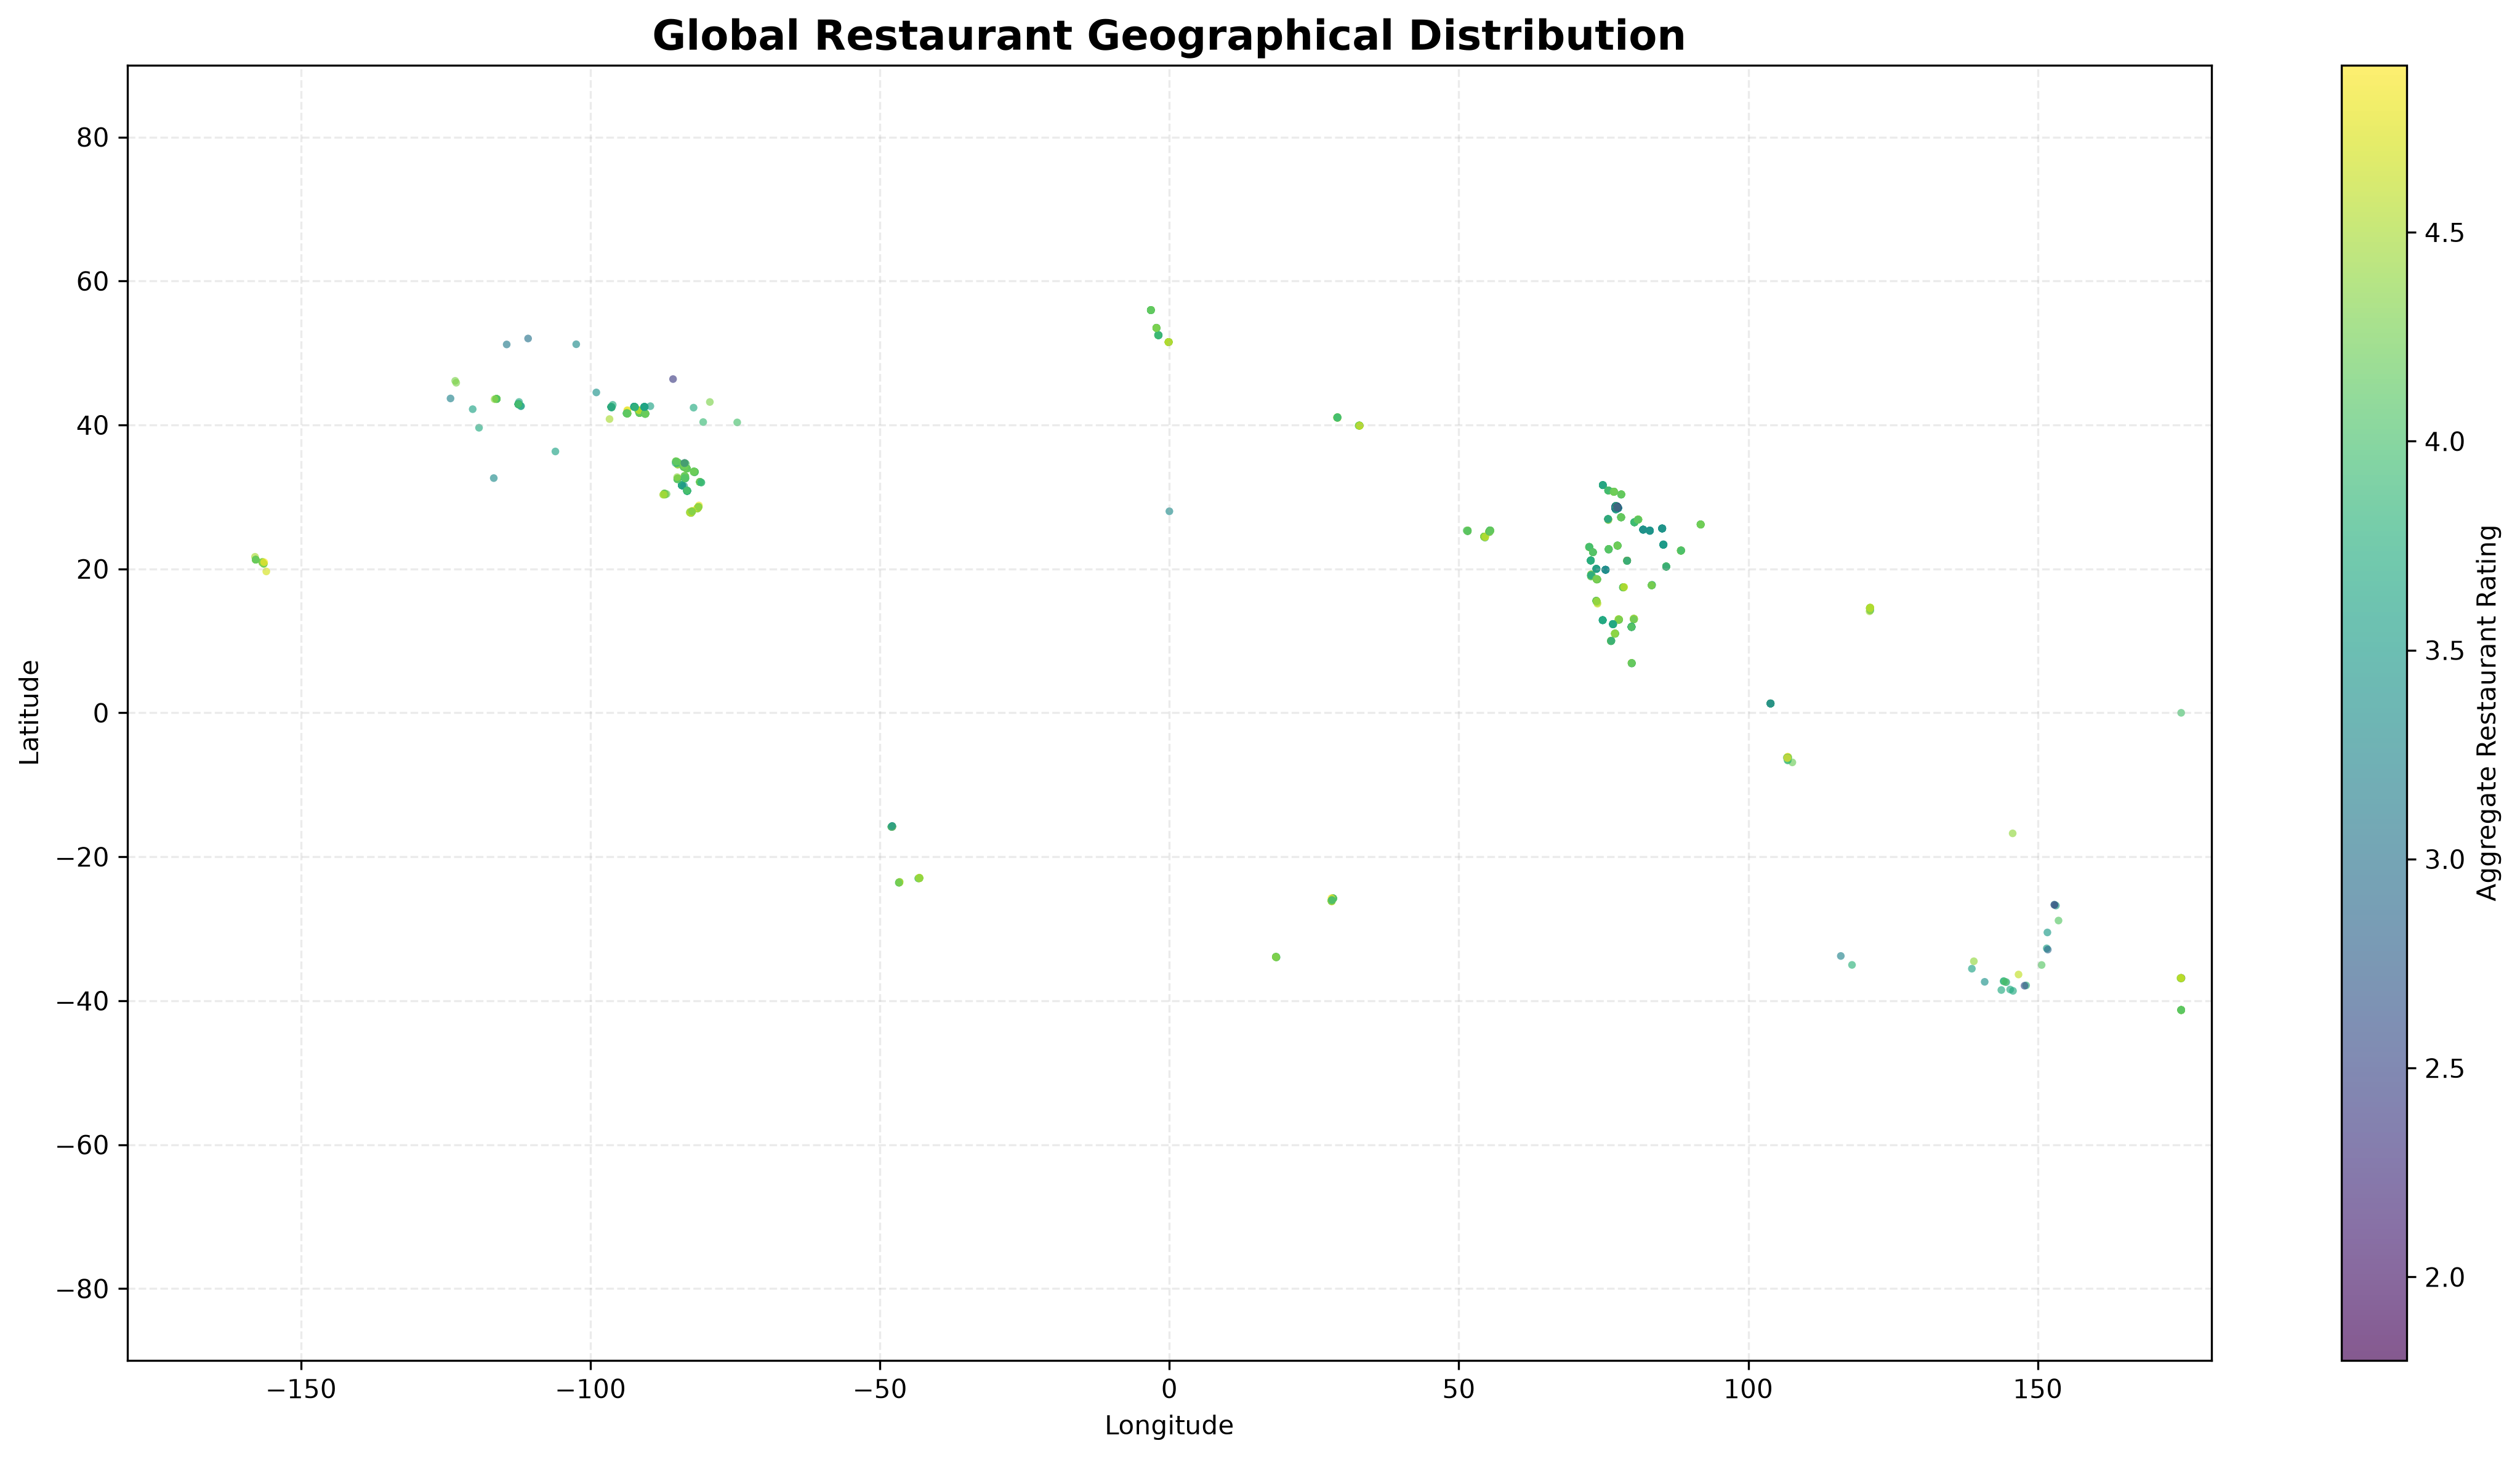

02_india_restaurant_distribution.png


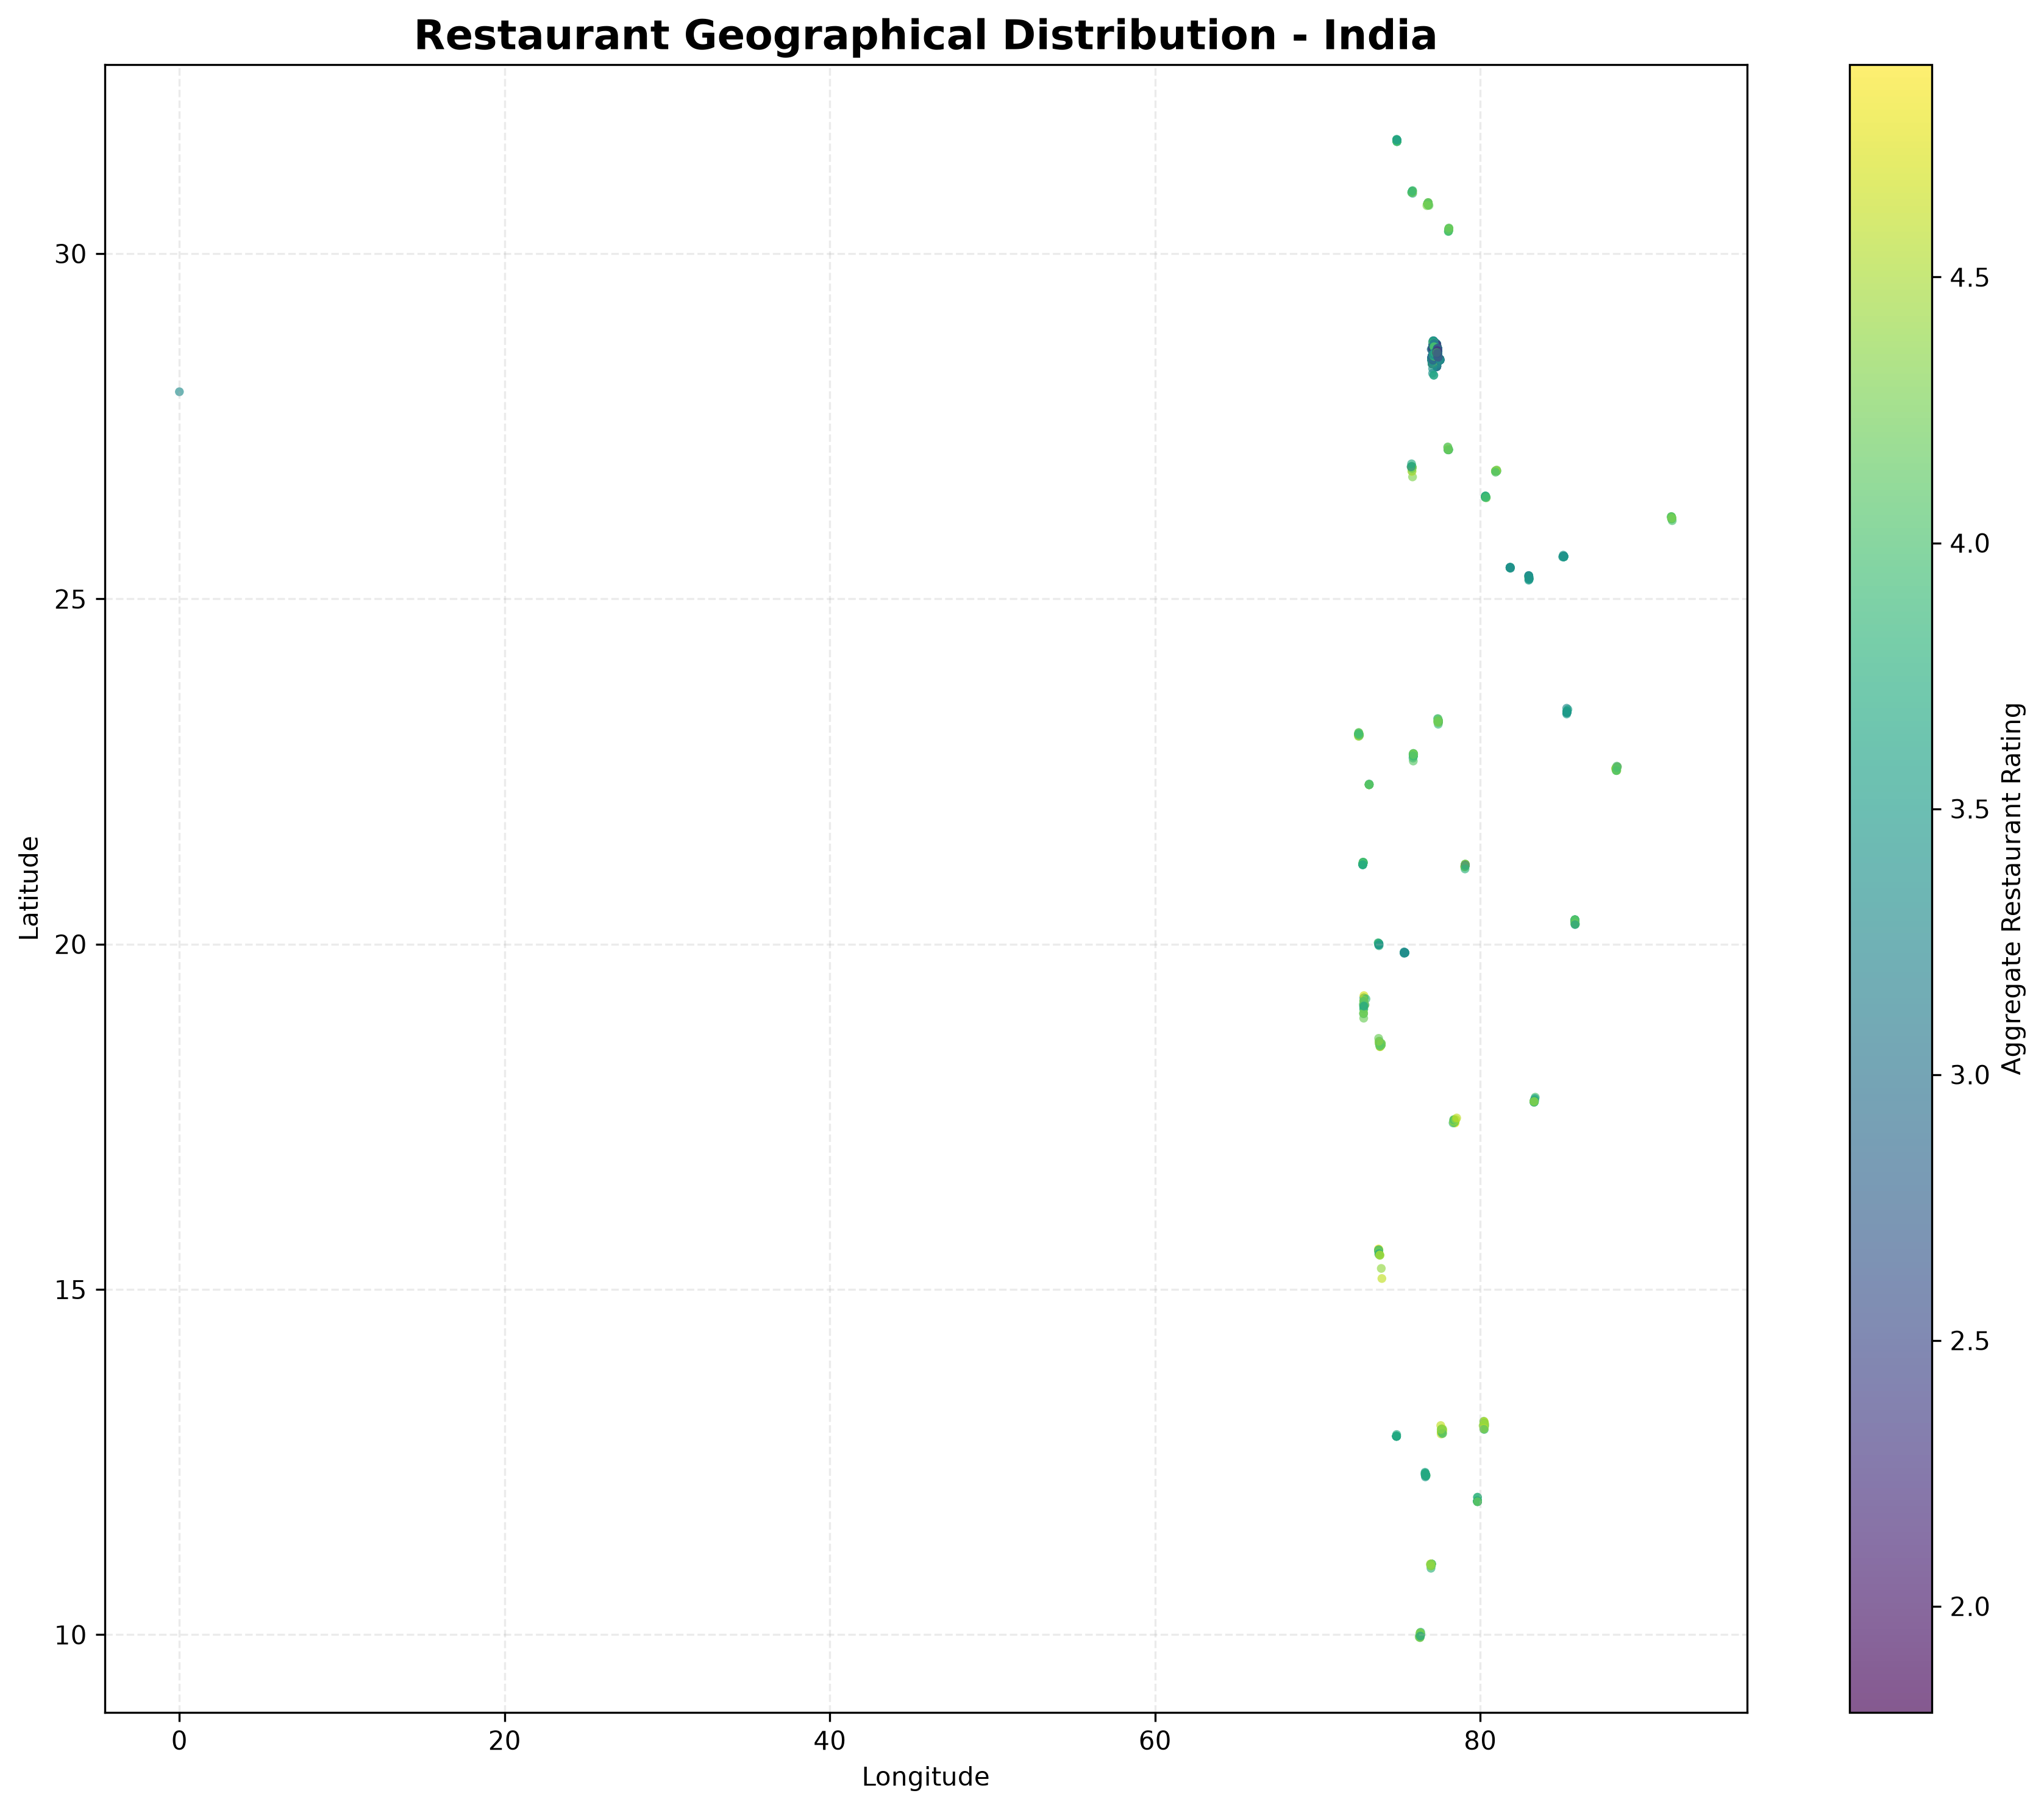

03_city_geographical_distribution.png


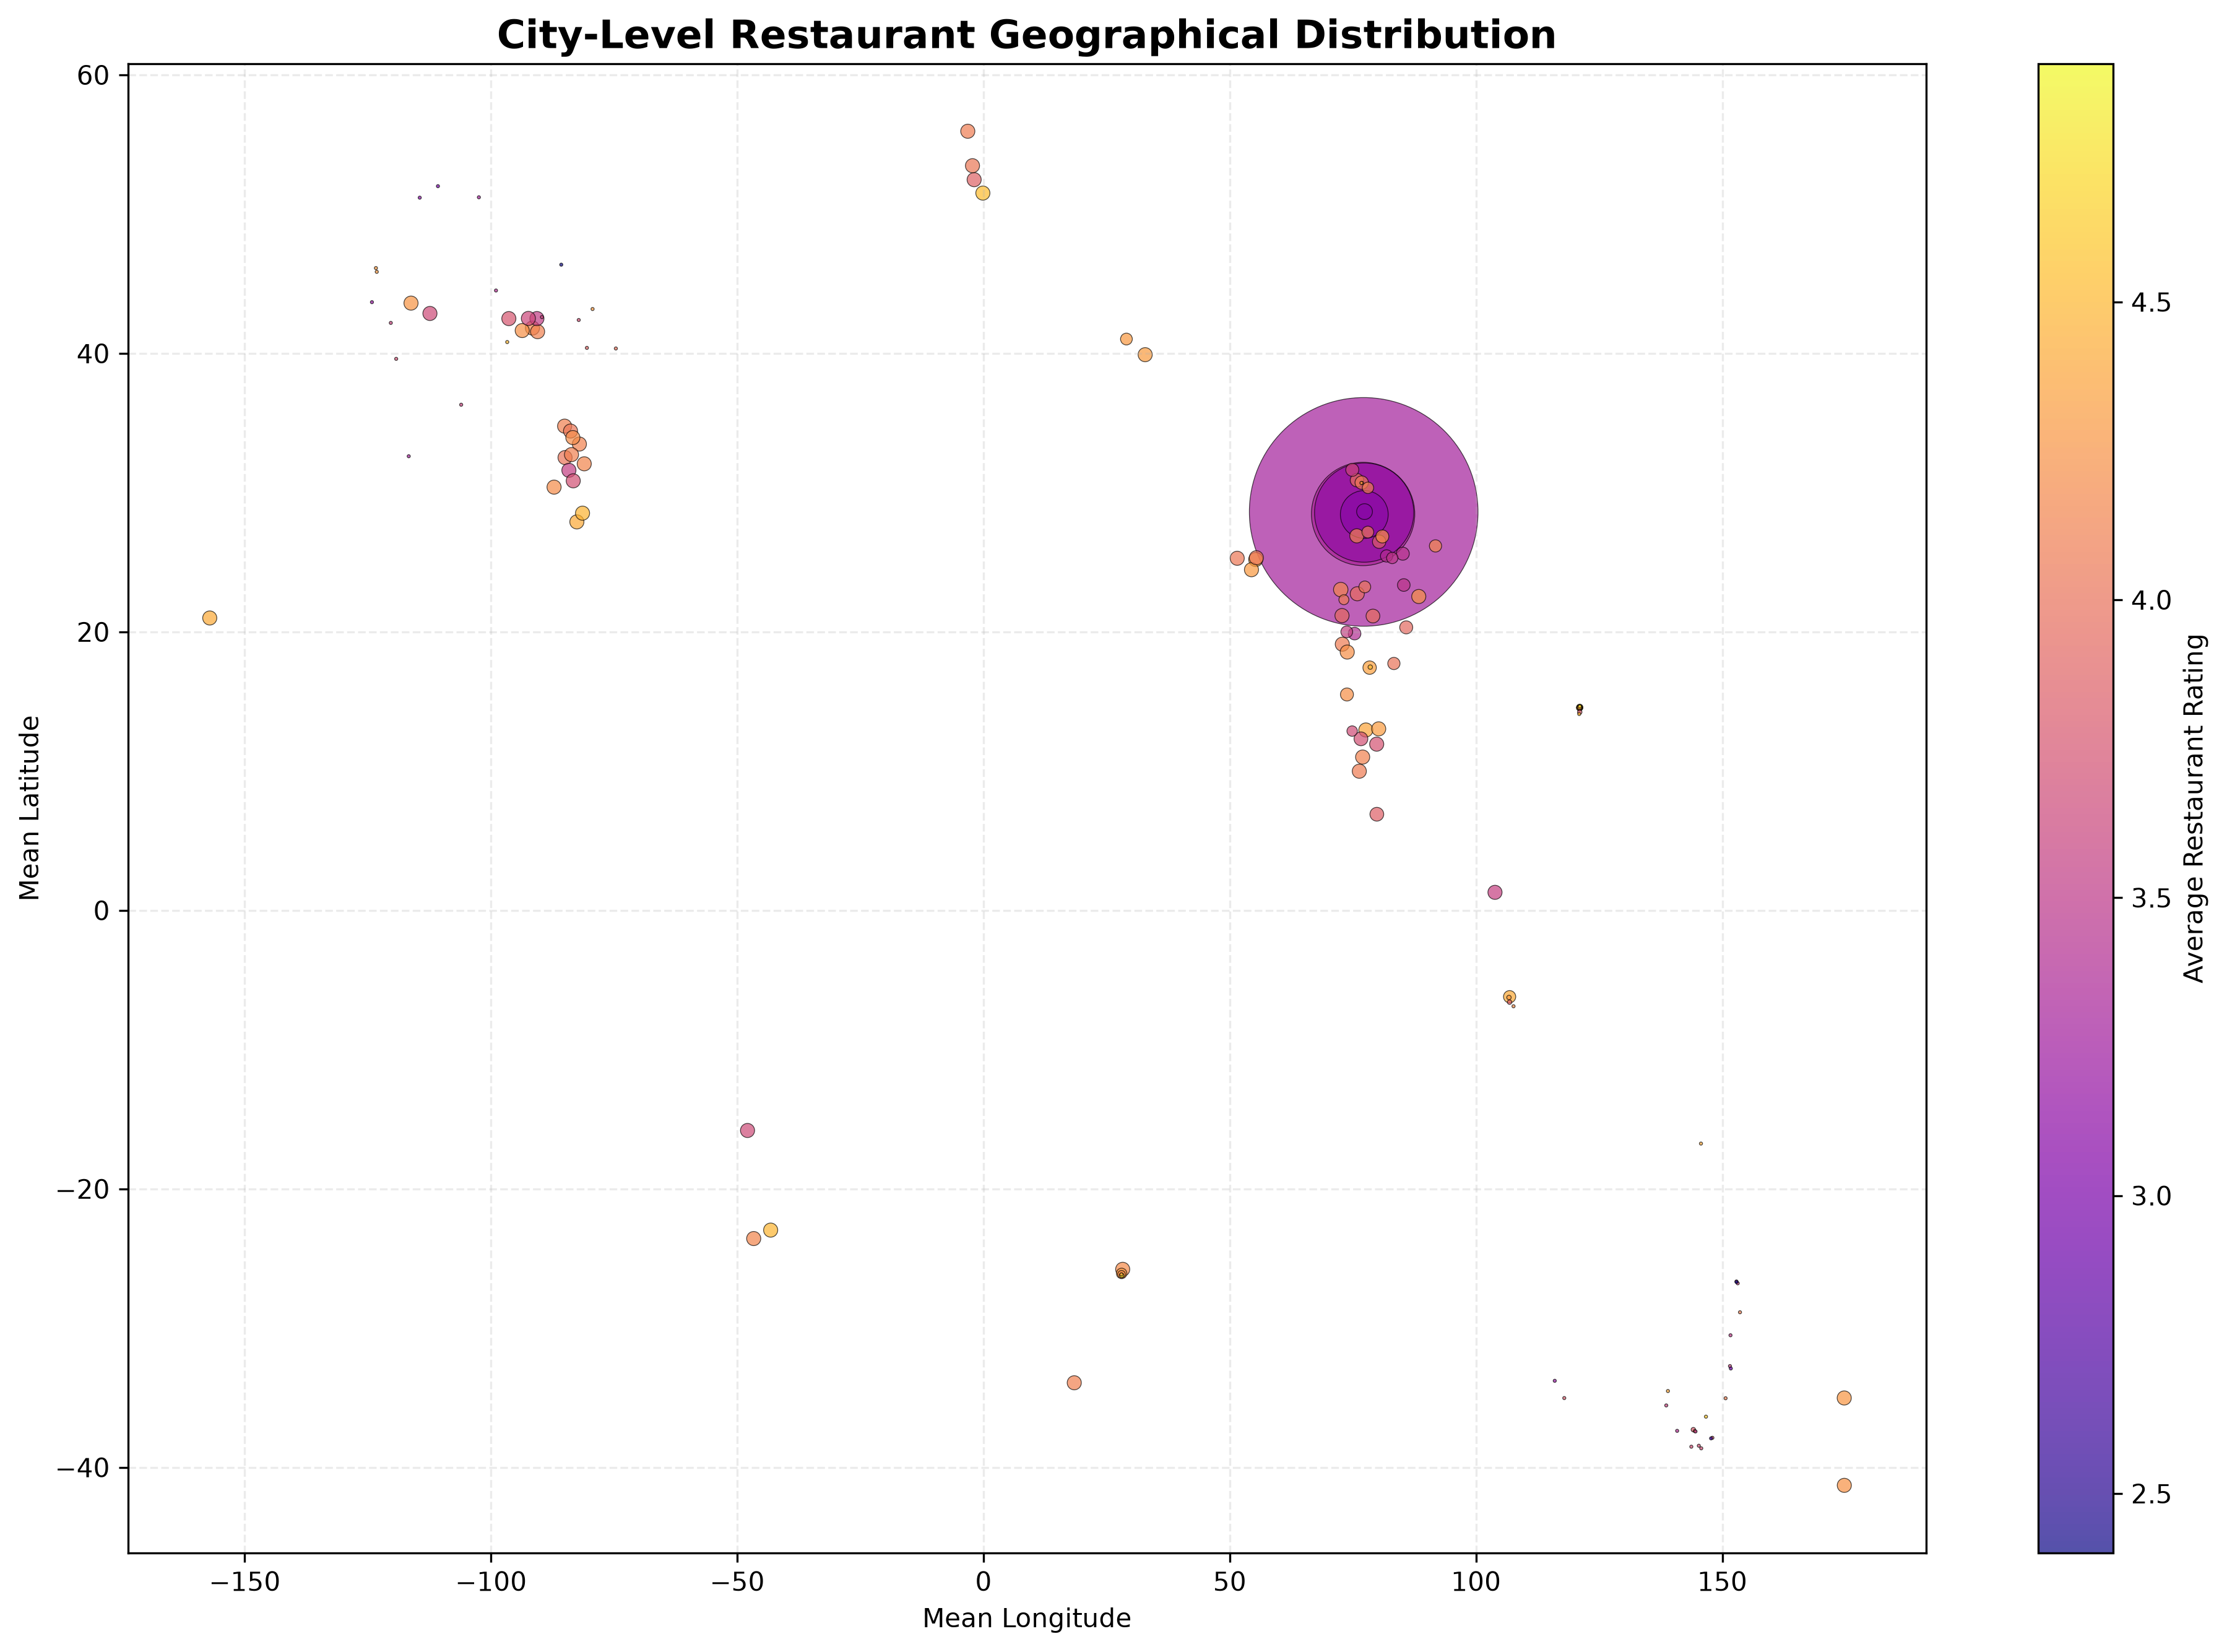

04_geographical_dbscan_clusters.png


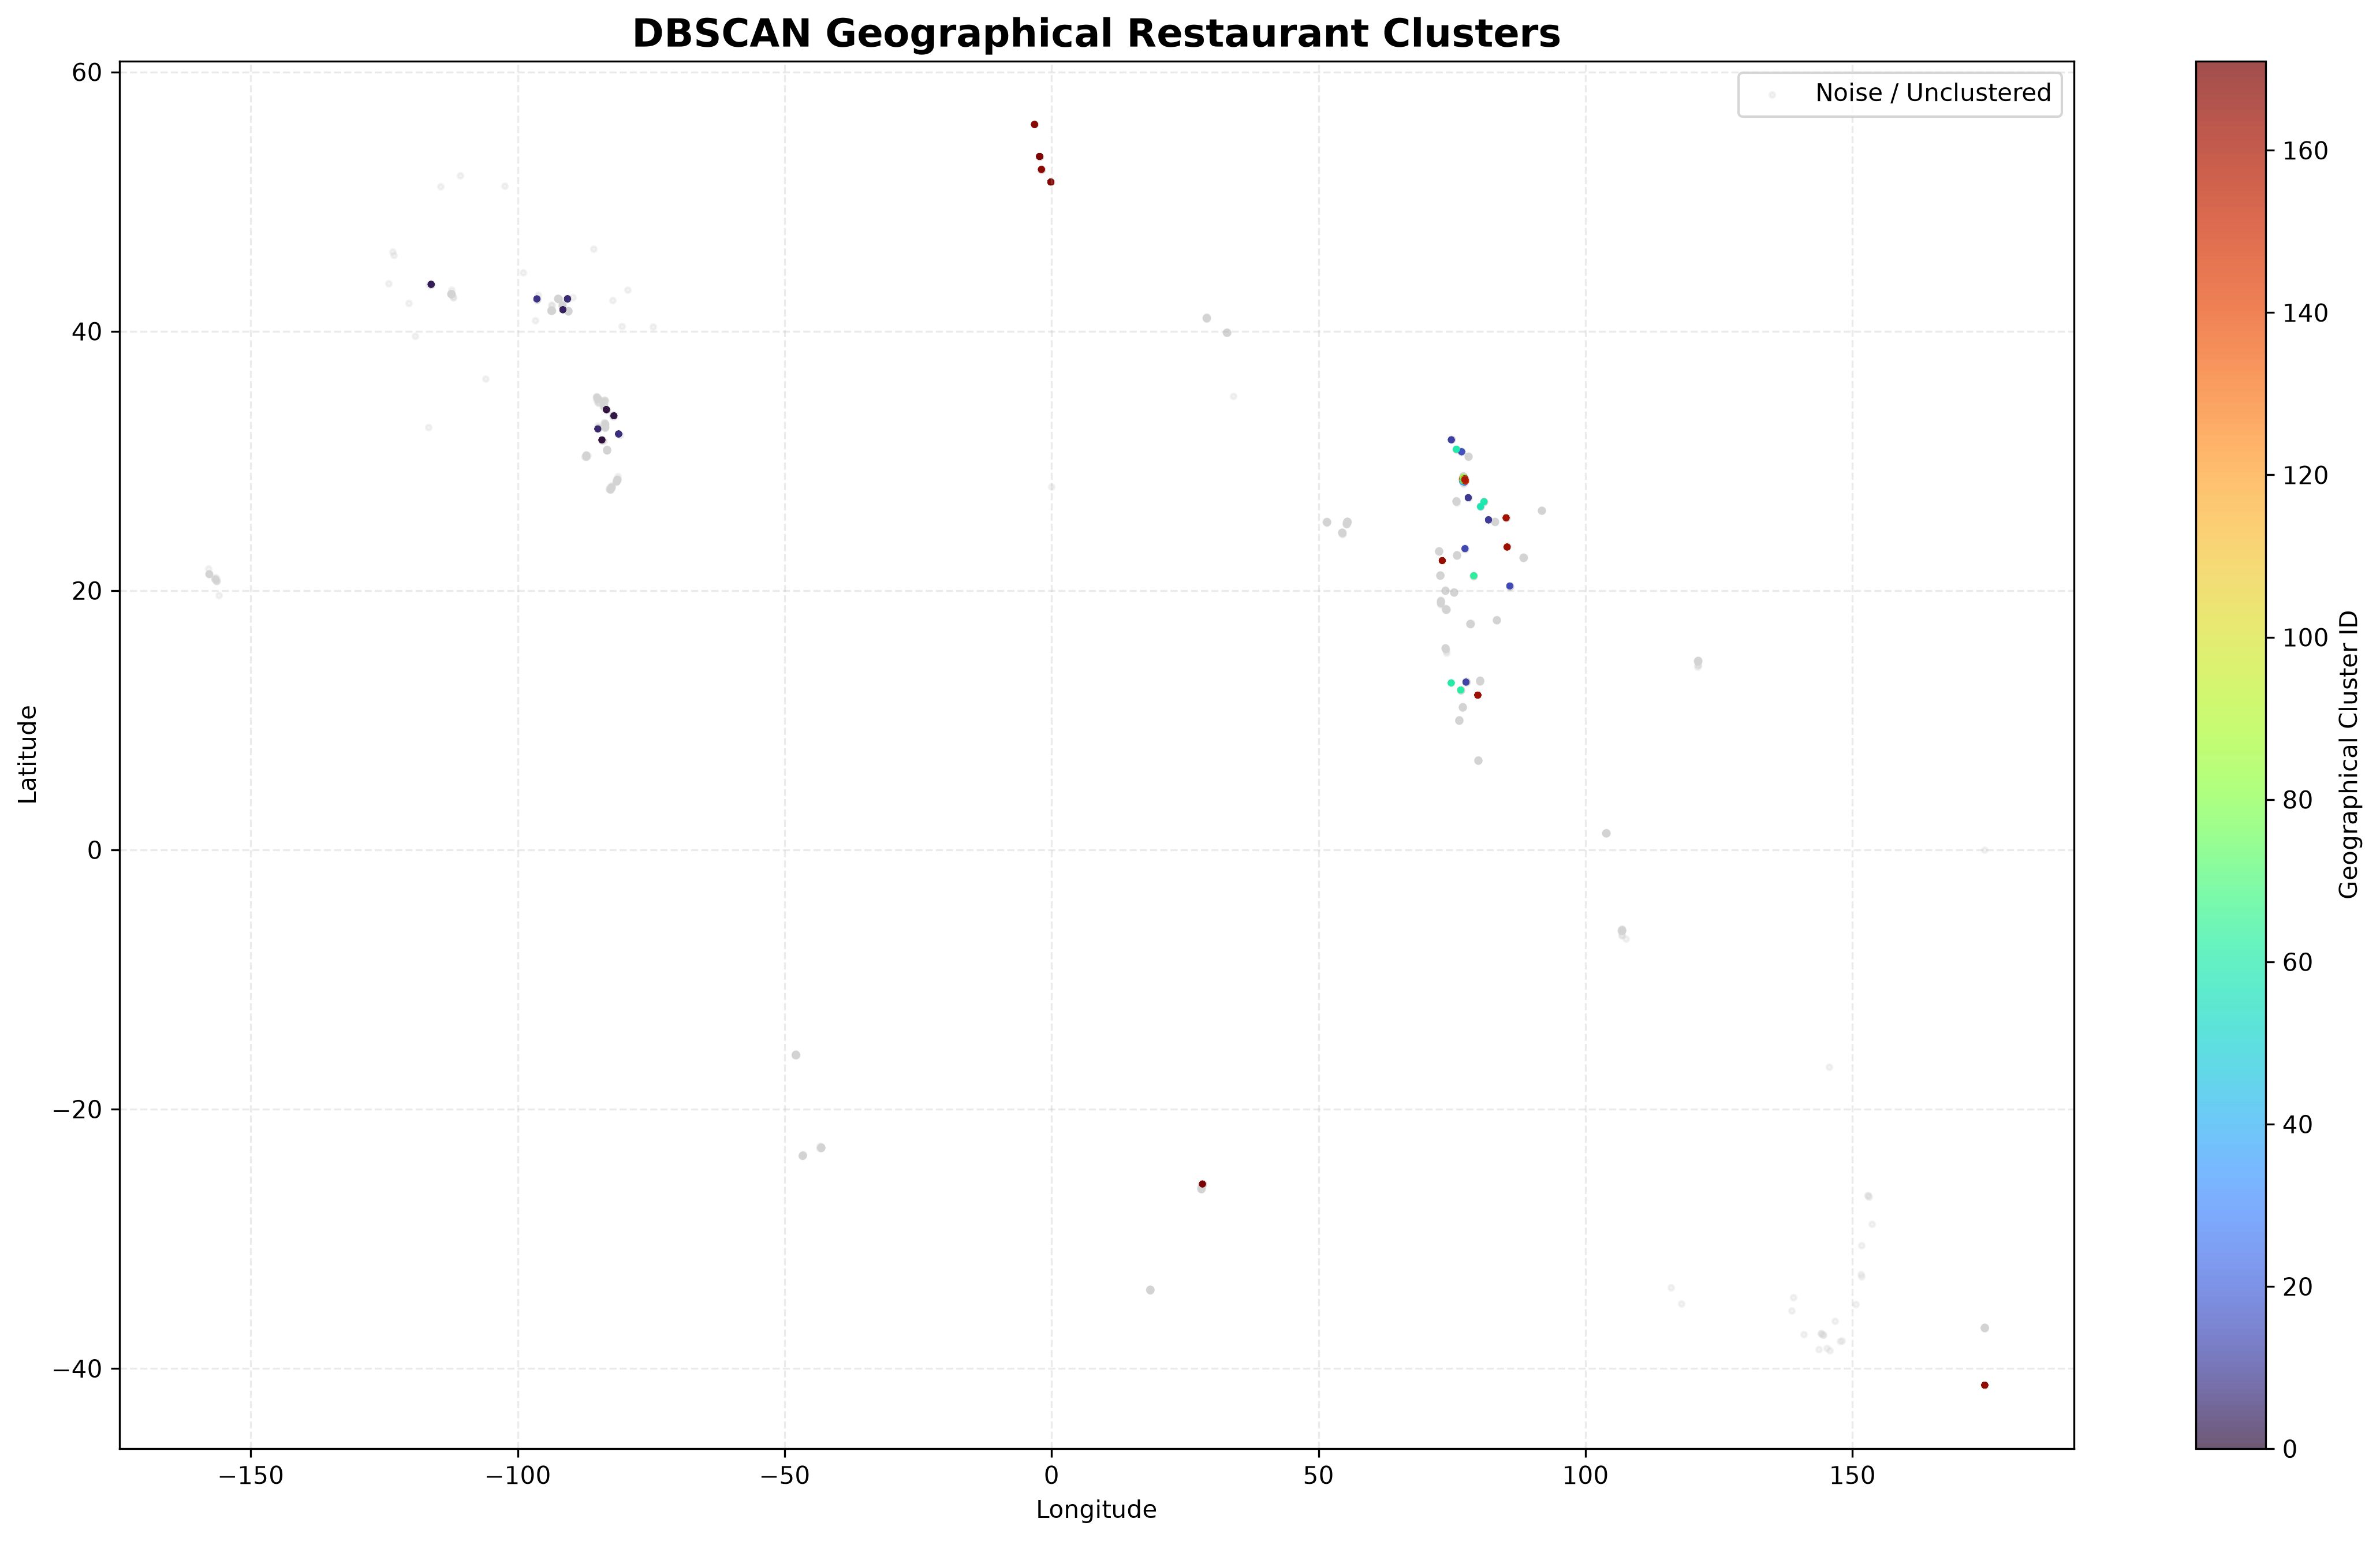

05_india_geographical_clusters.png


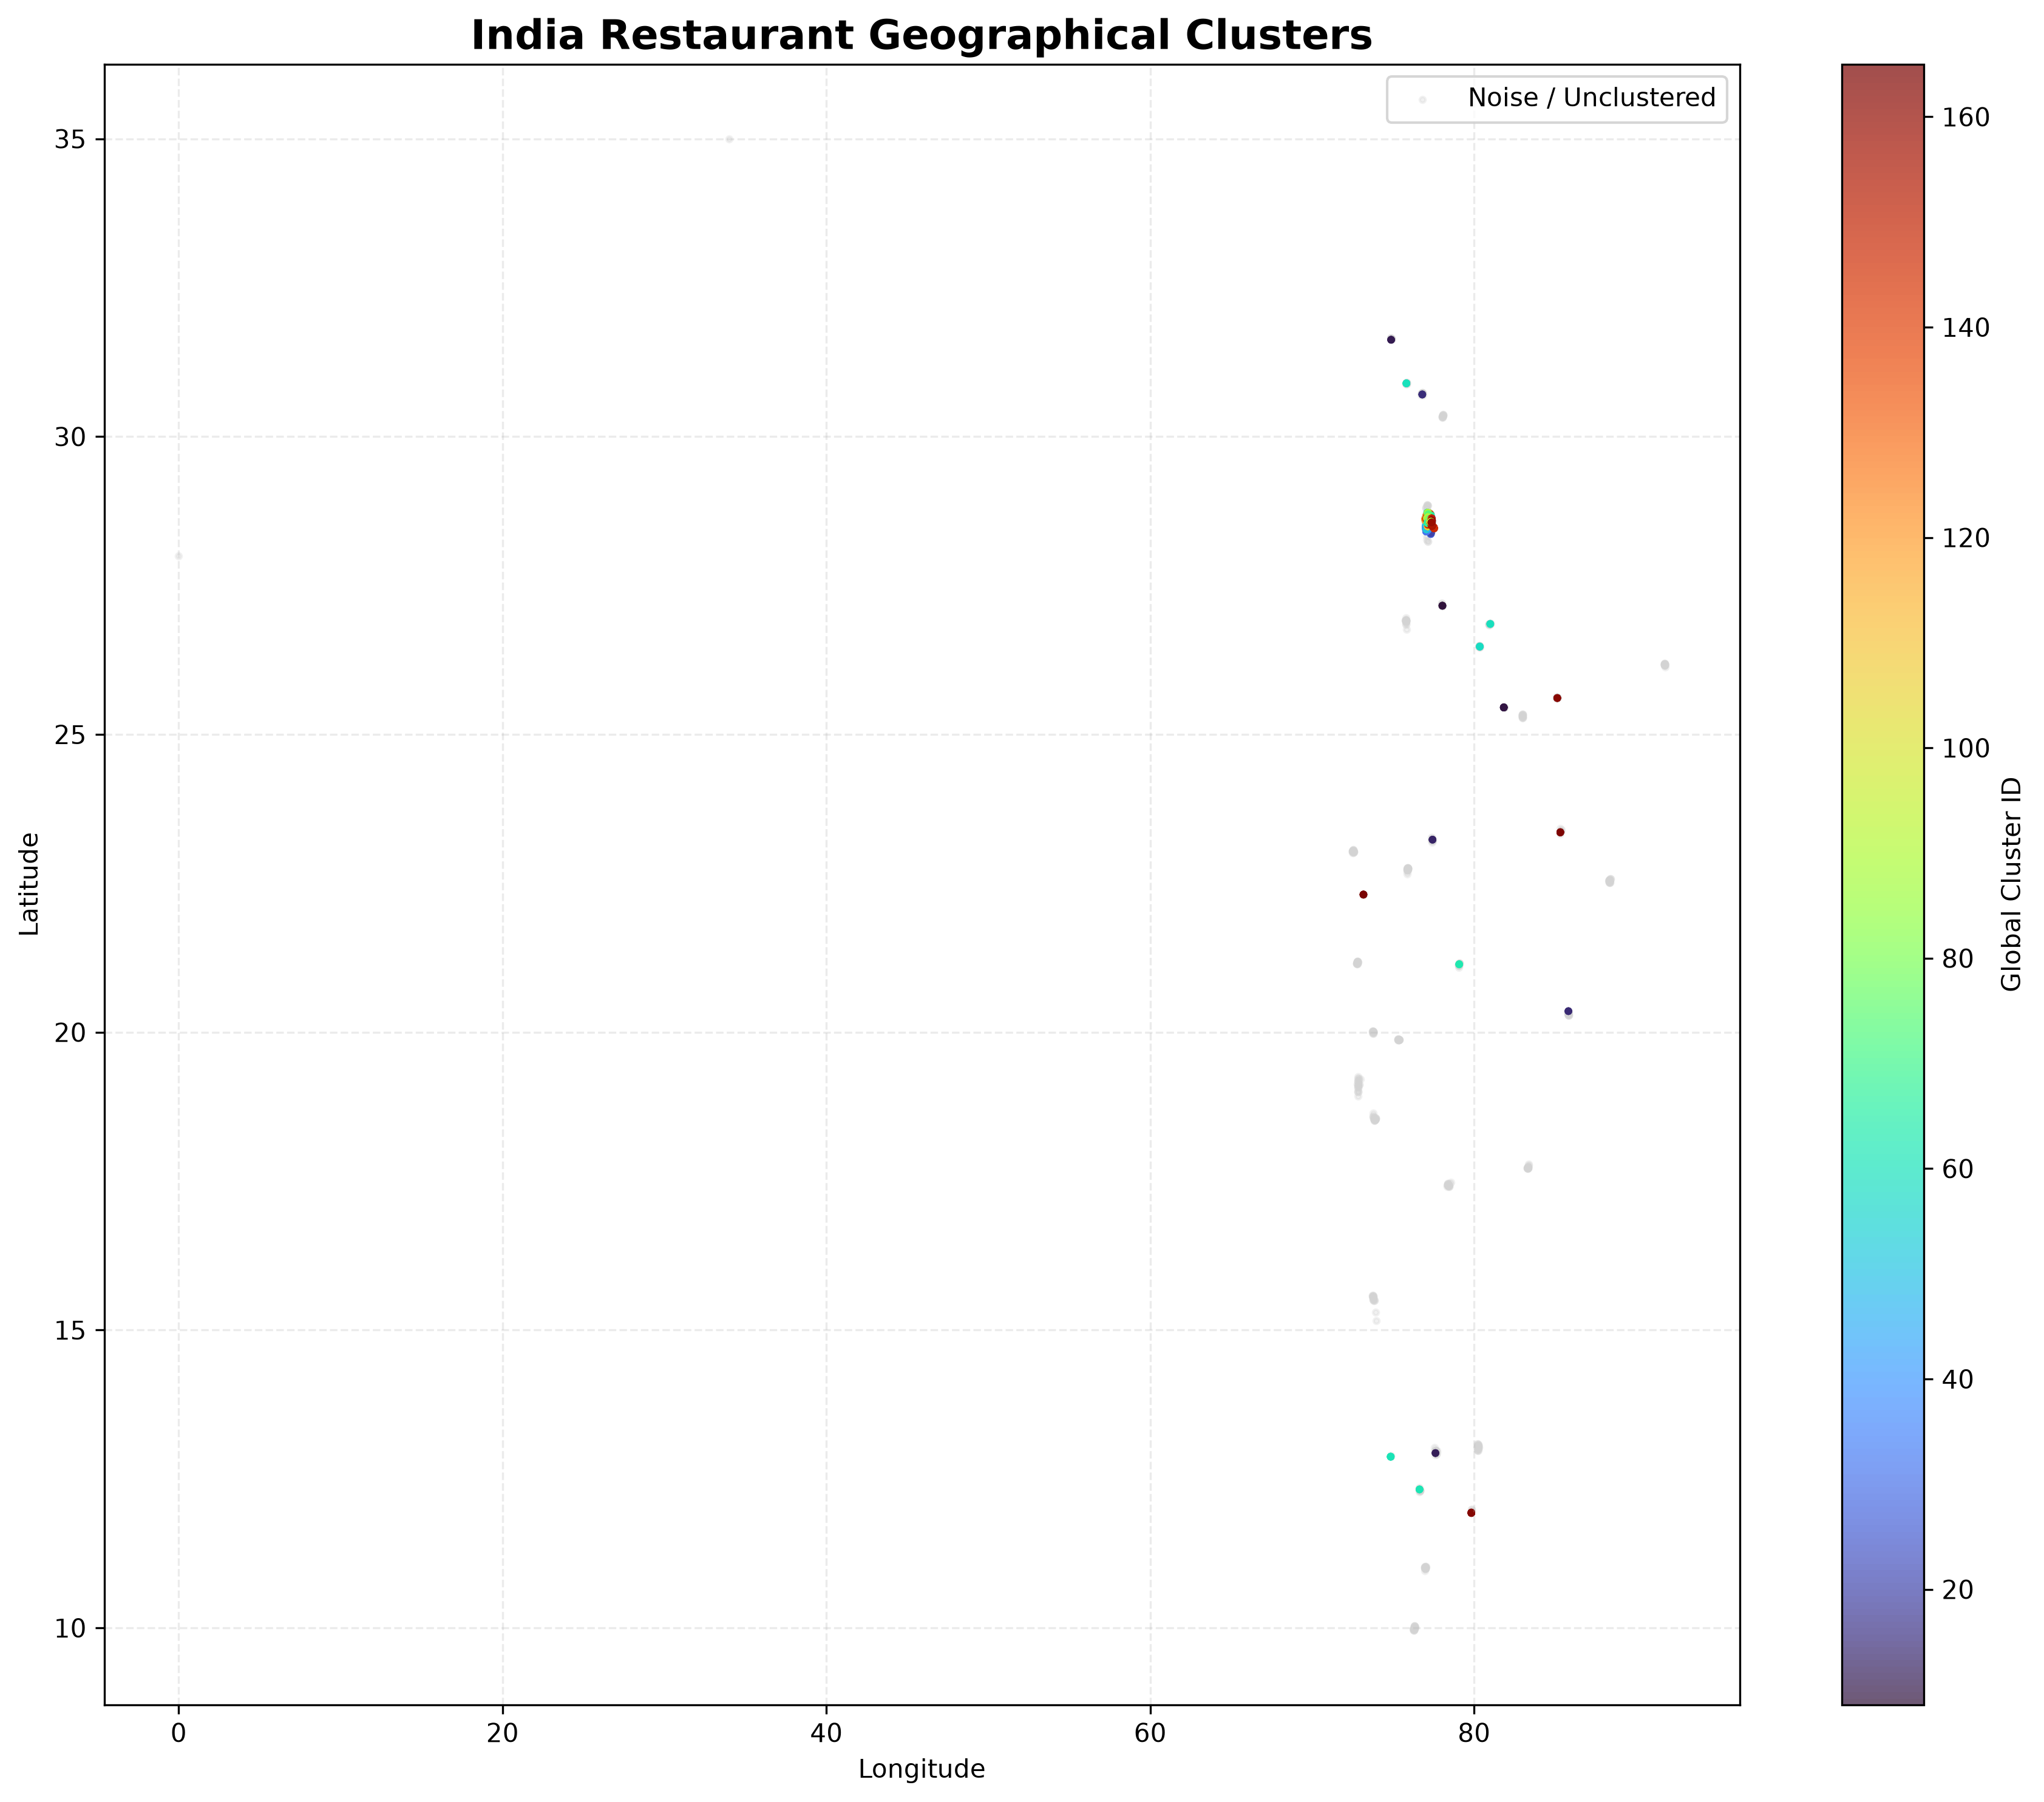

06_coordinate_overlap_analysis.png


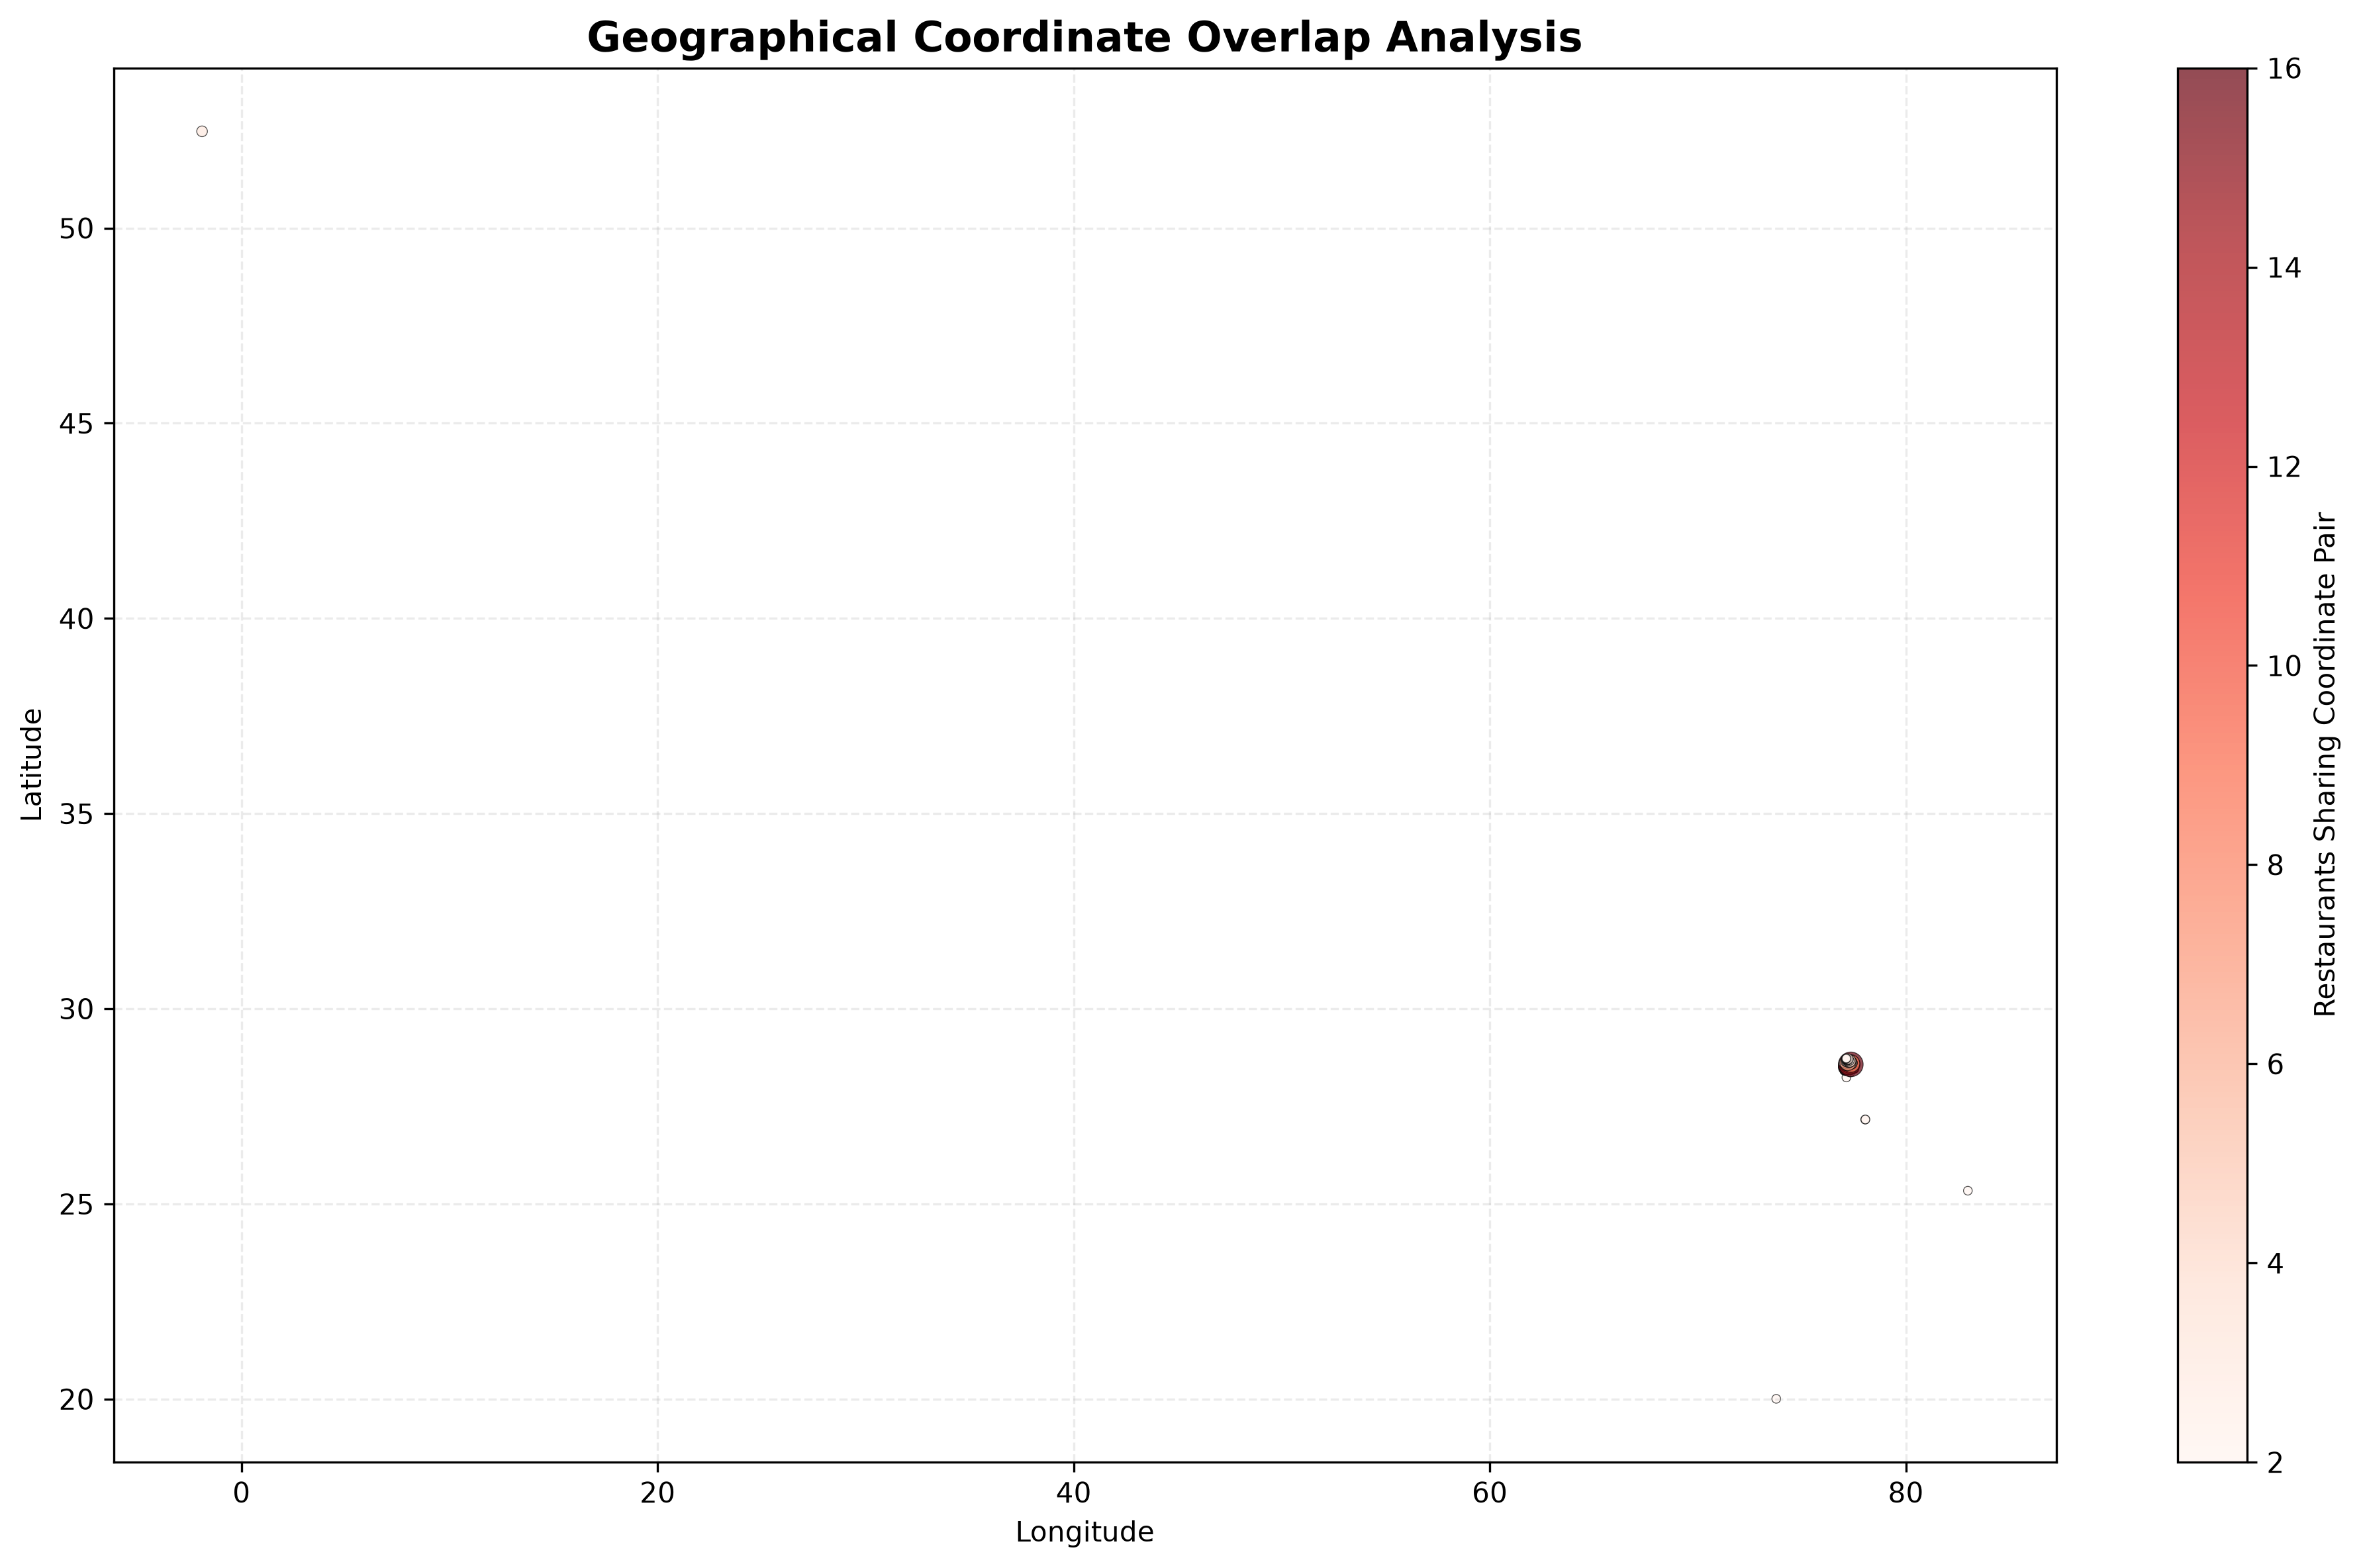

07_city_rating_comparison.png


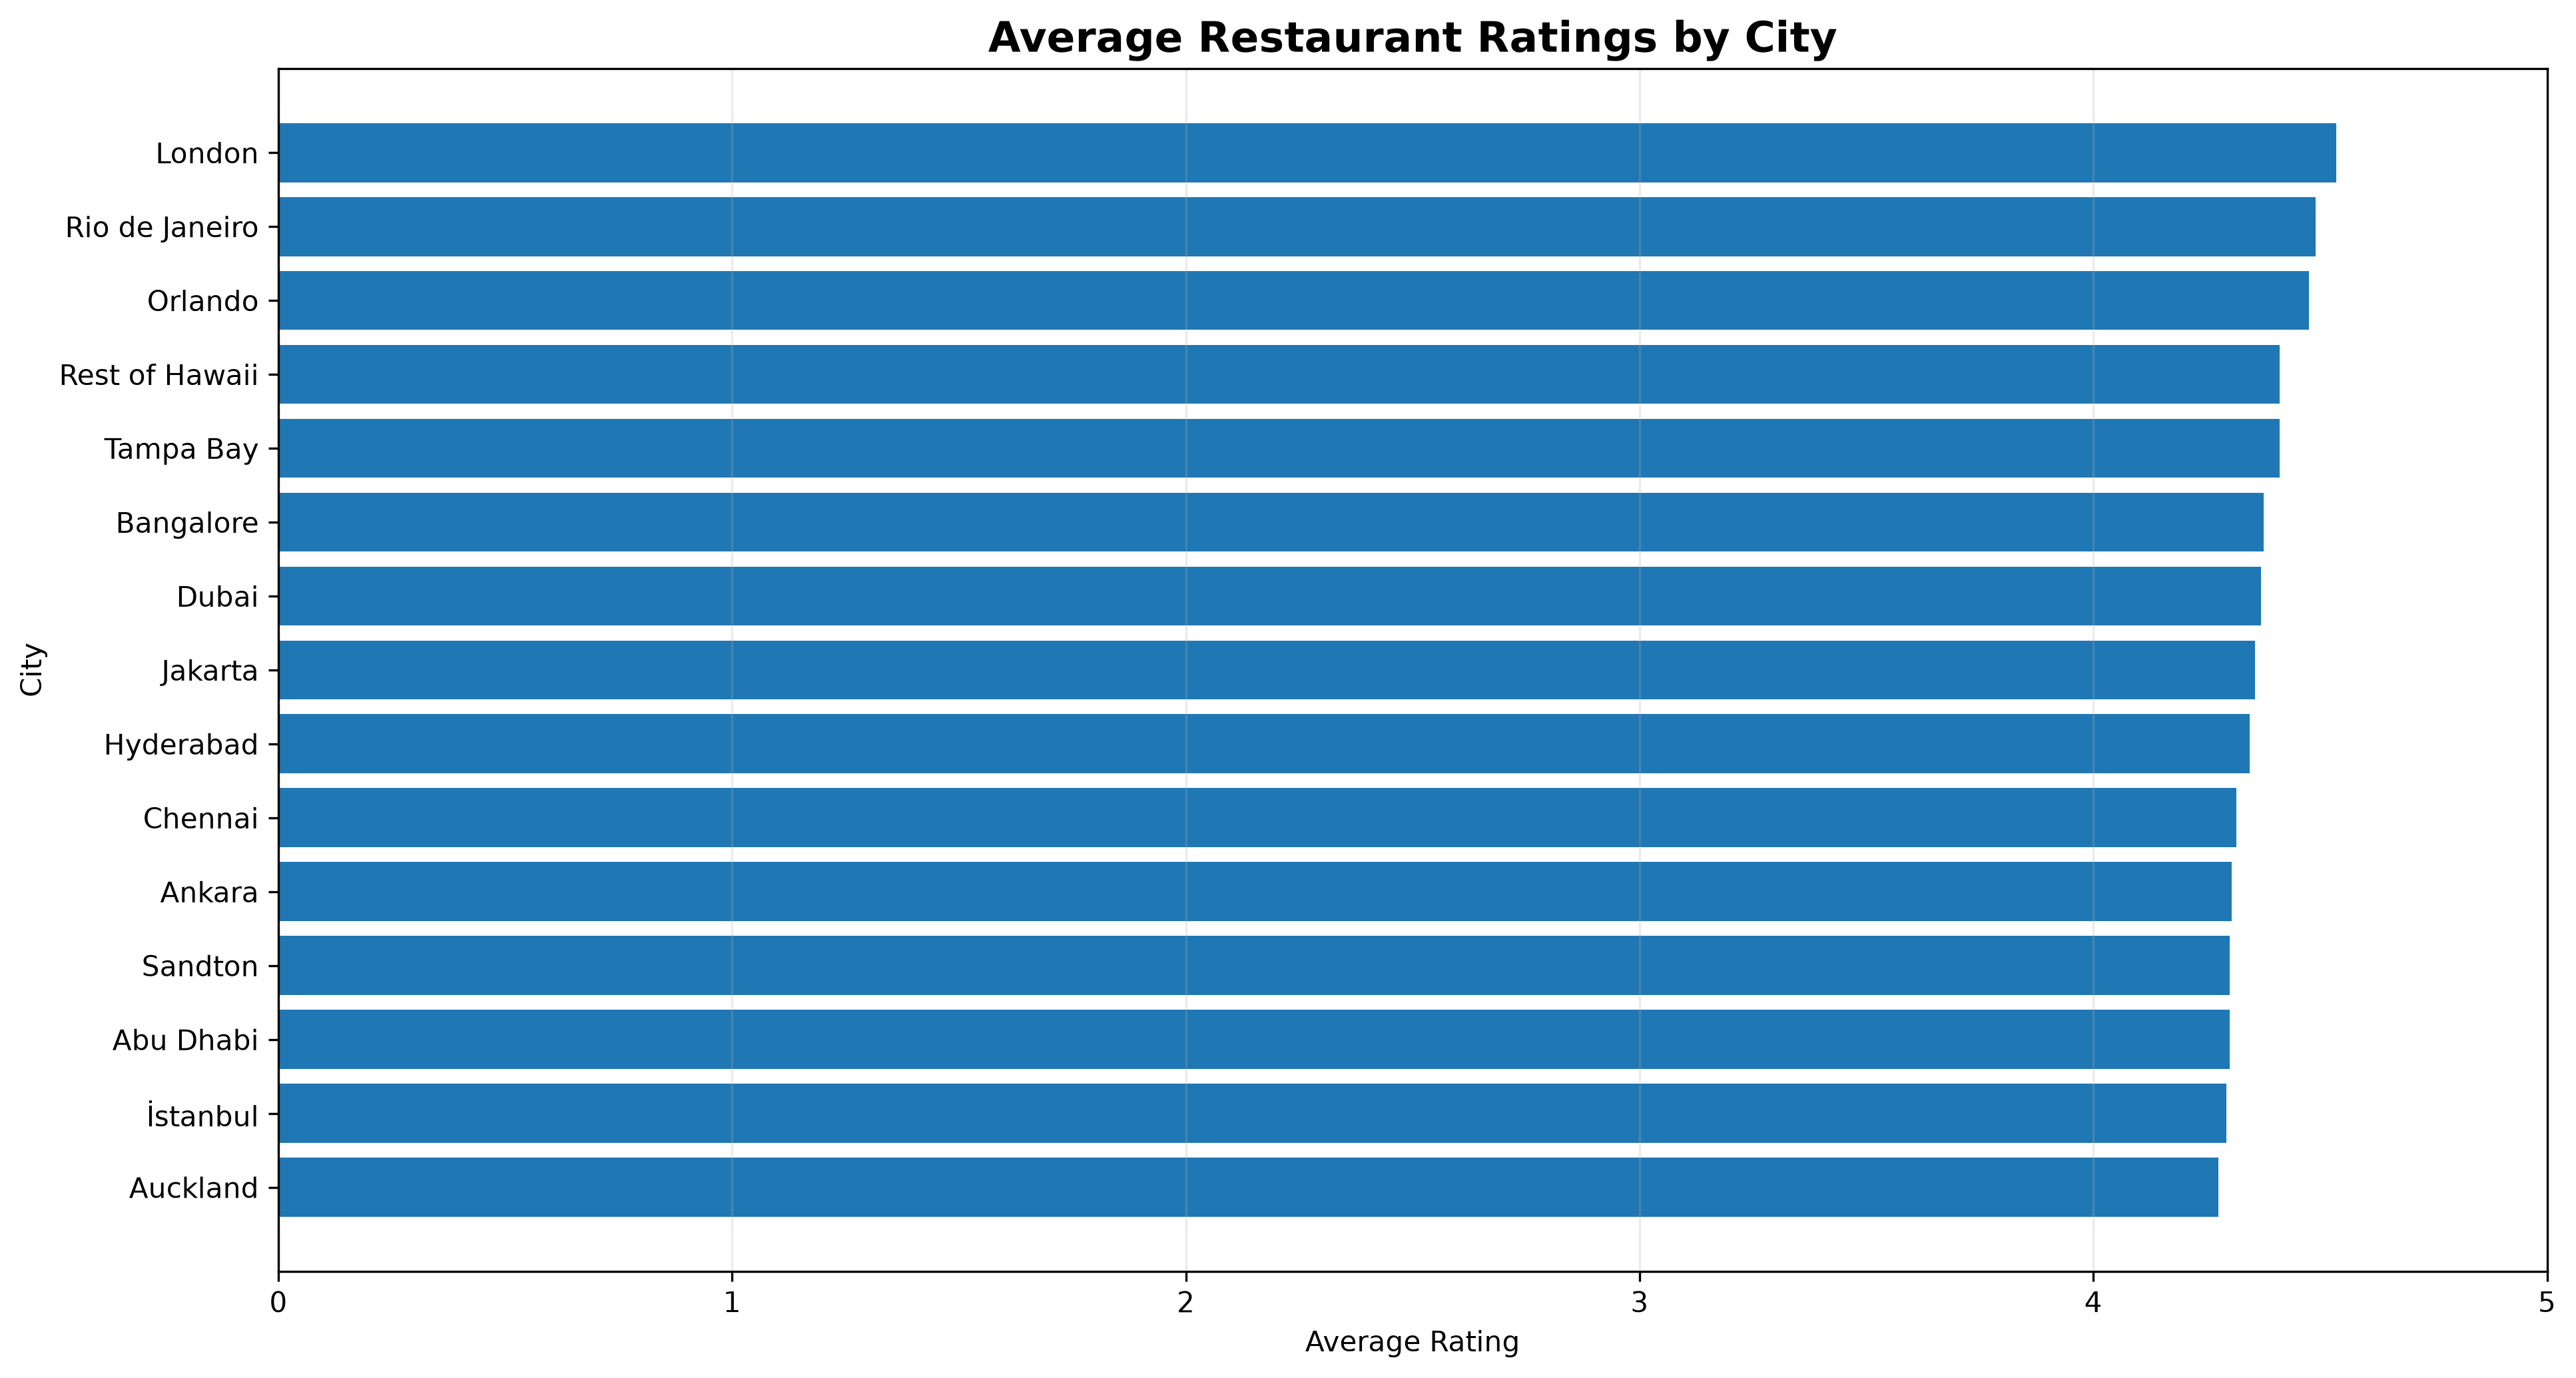

08_price_rating_comparison.png


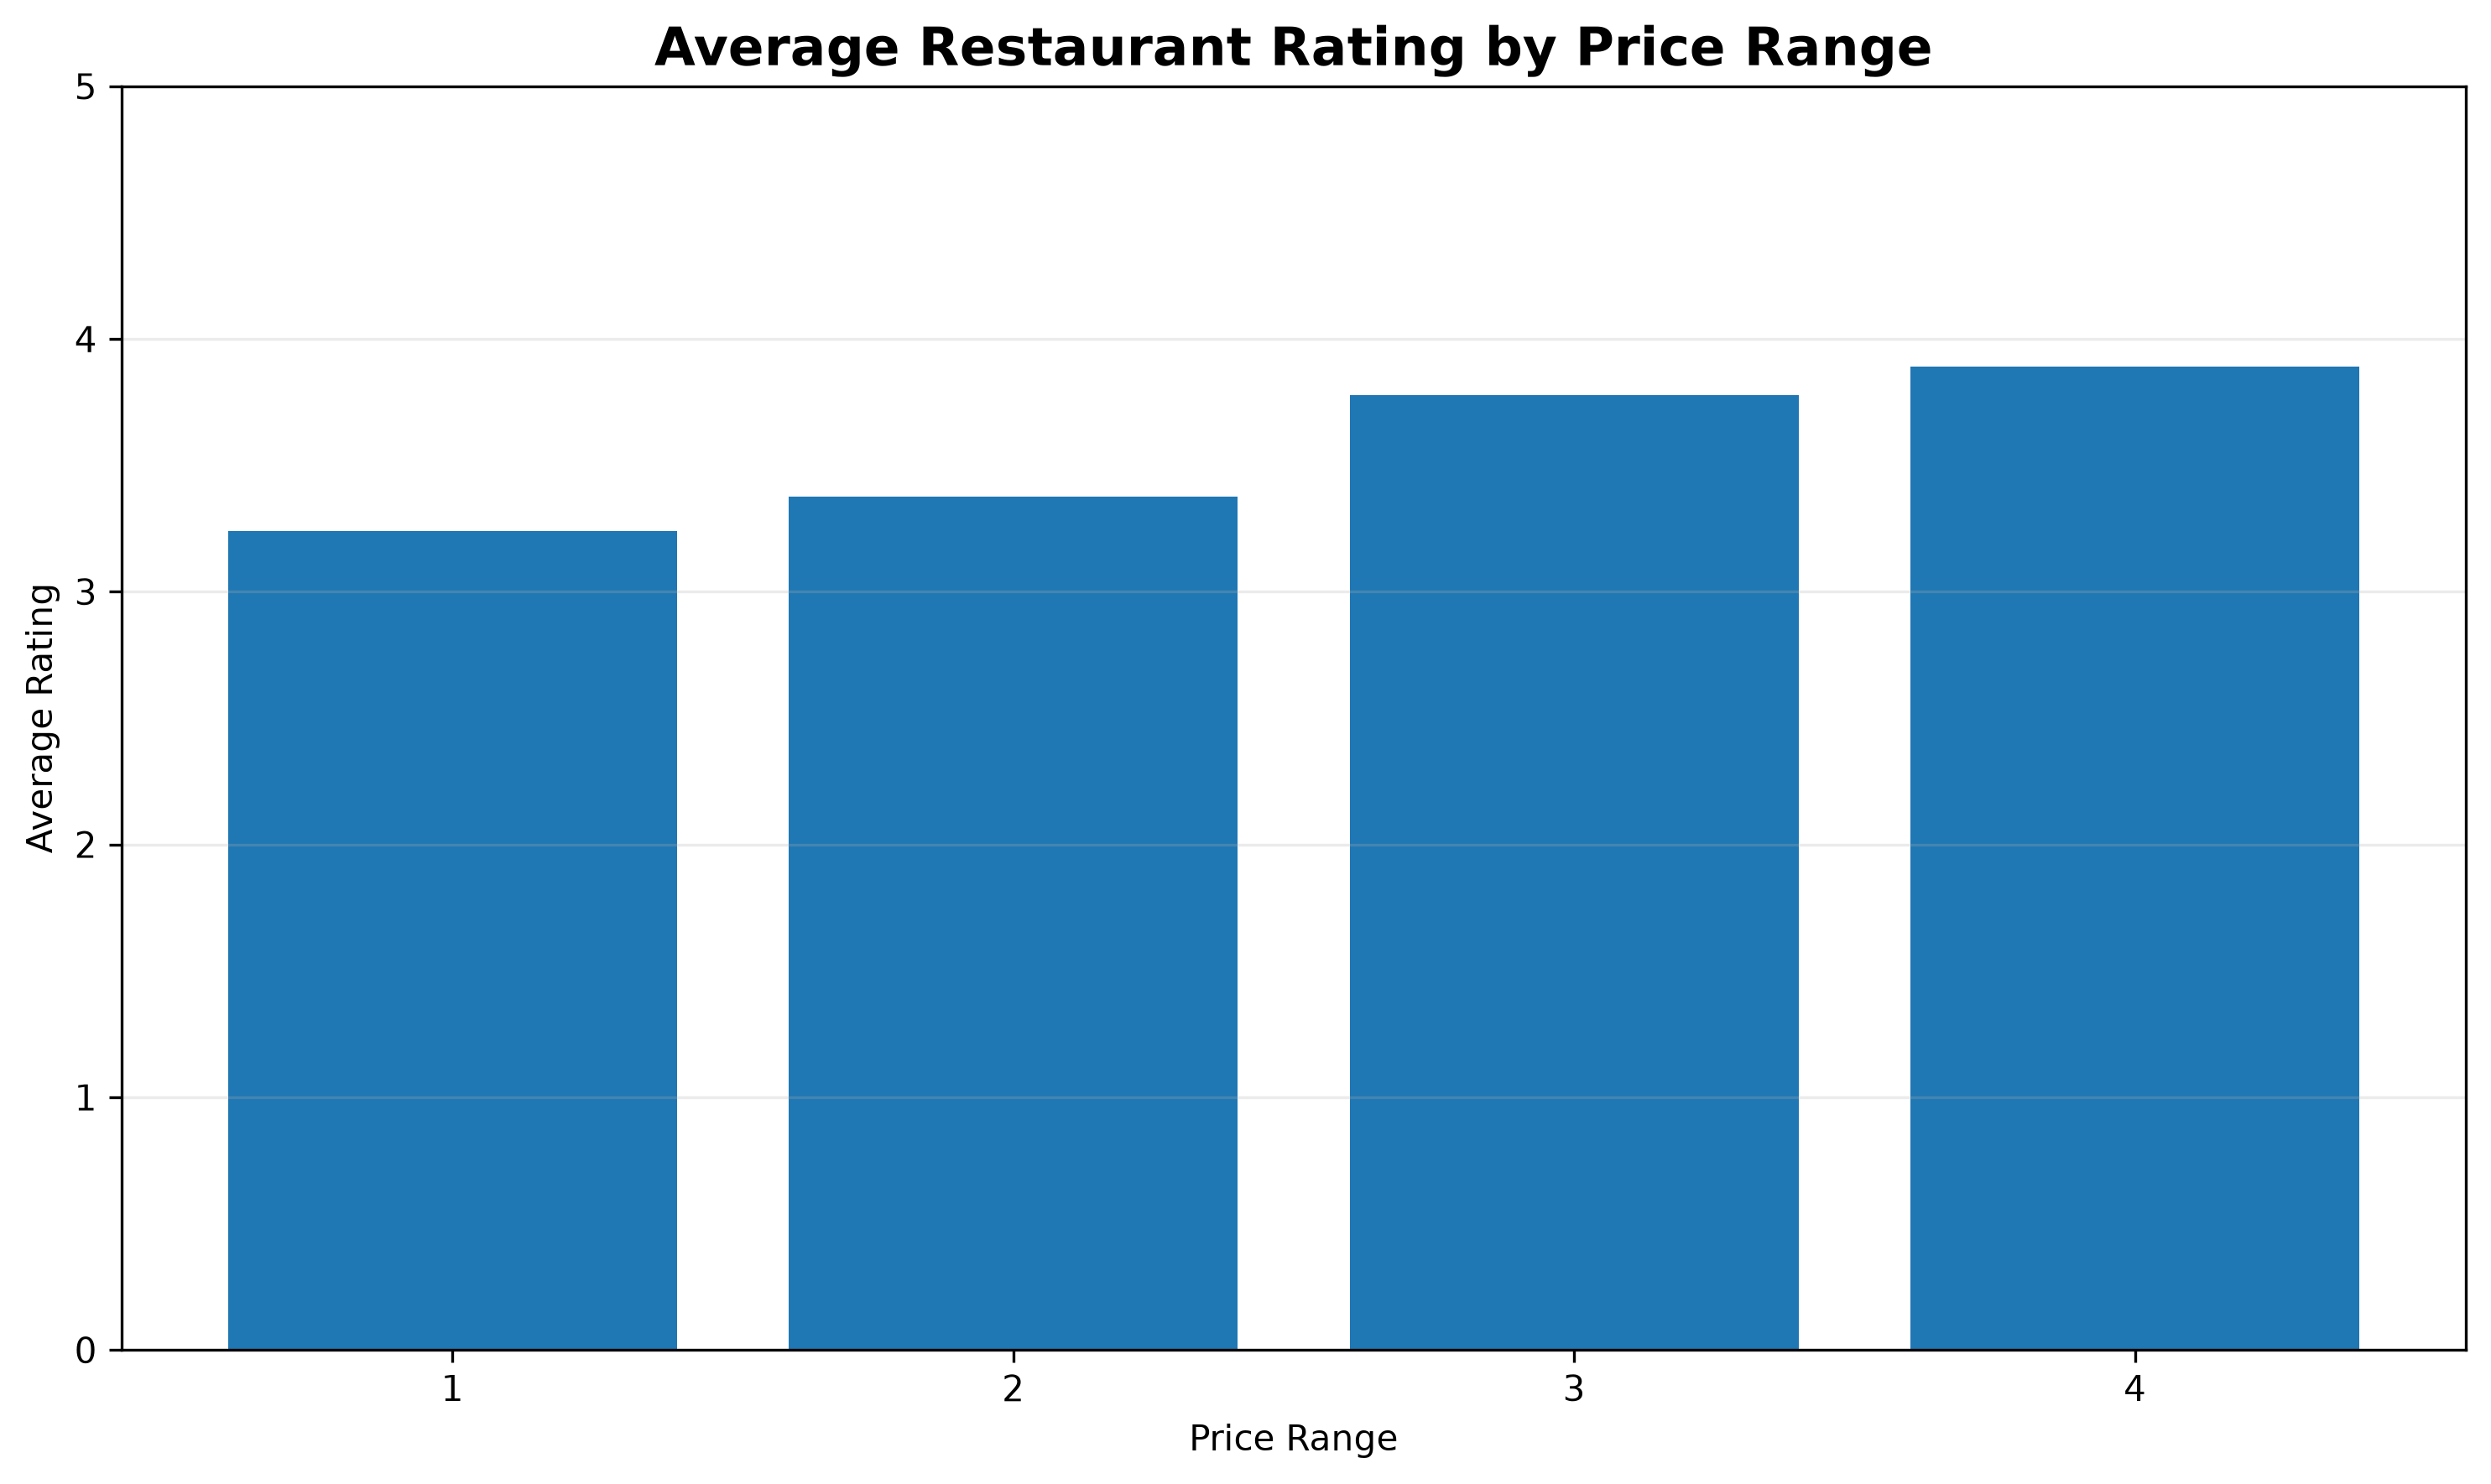

09_cuisine_diversity_rating.png


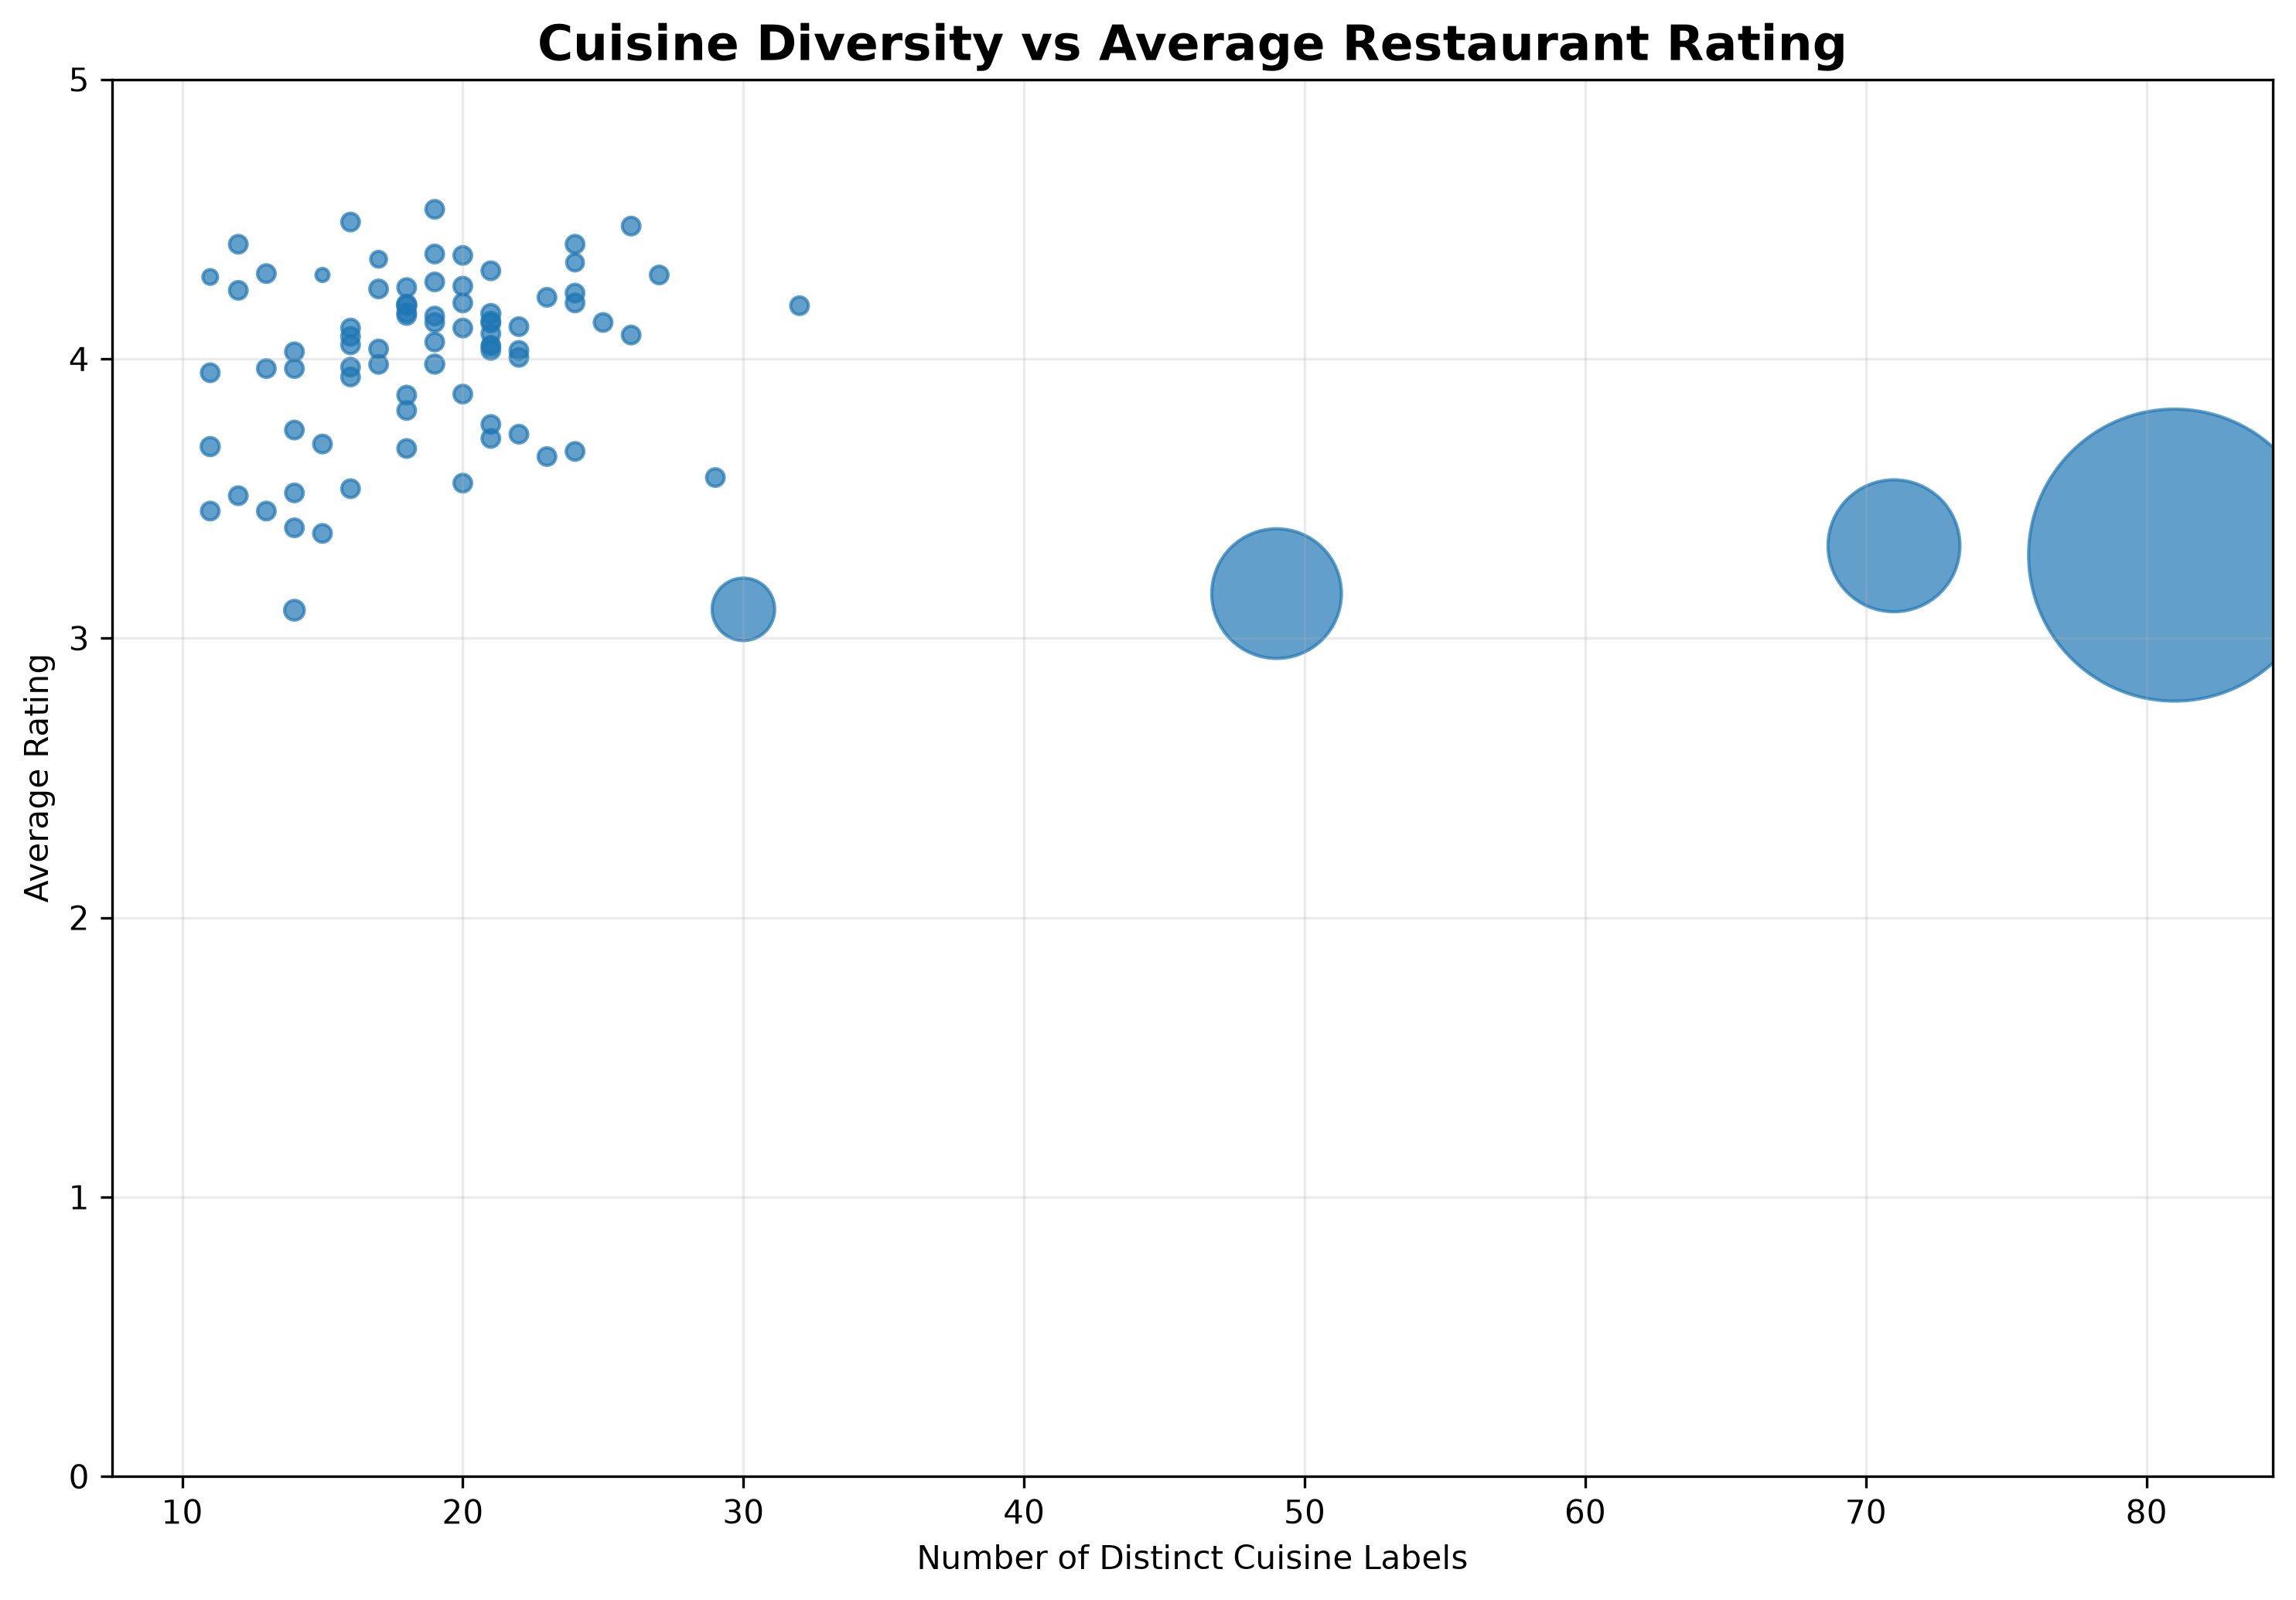

10_restaurant_concentration_rating_coverage.png


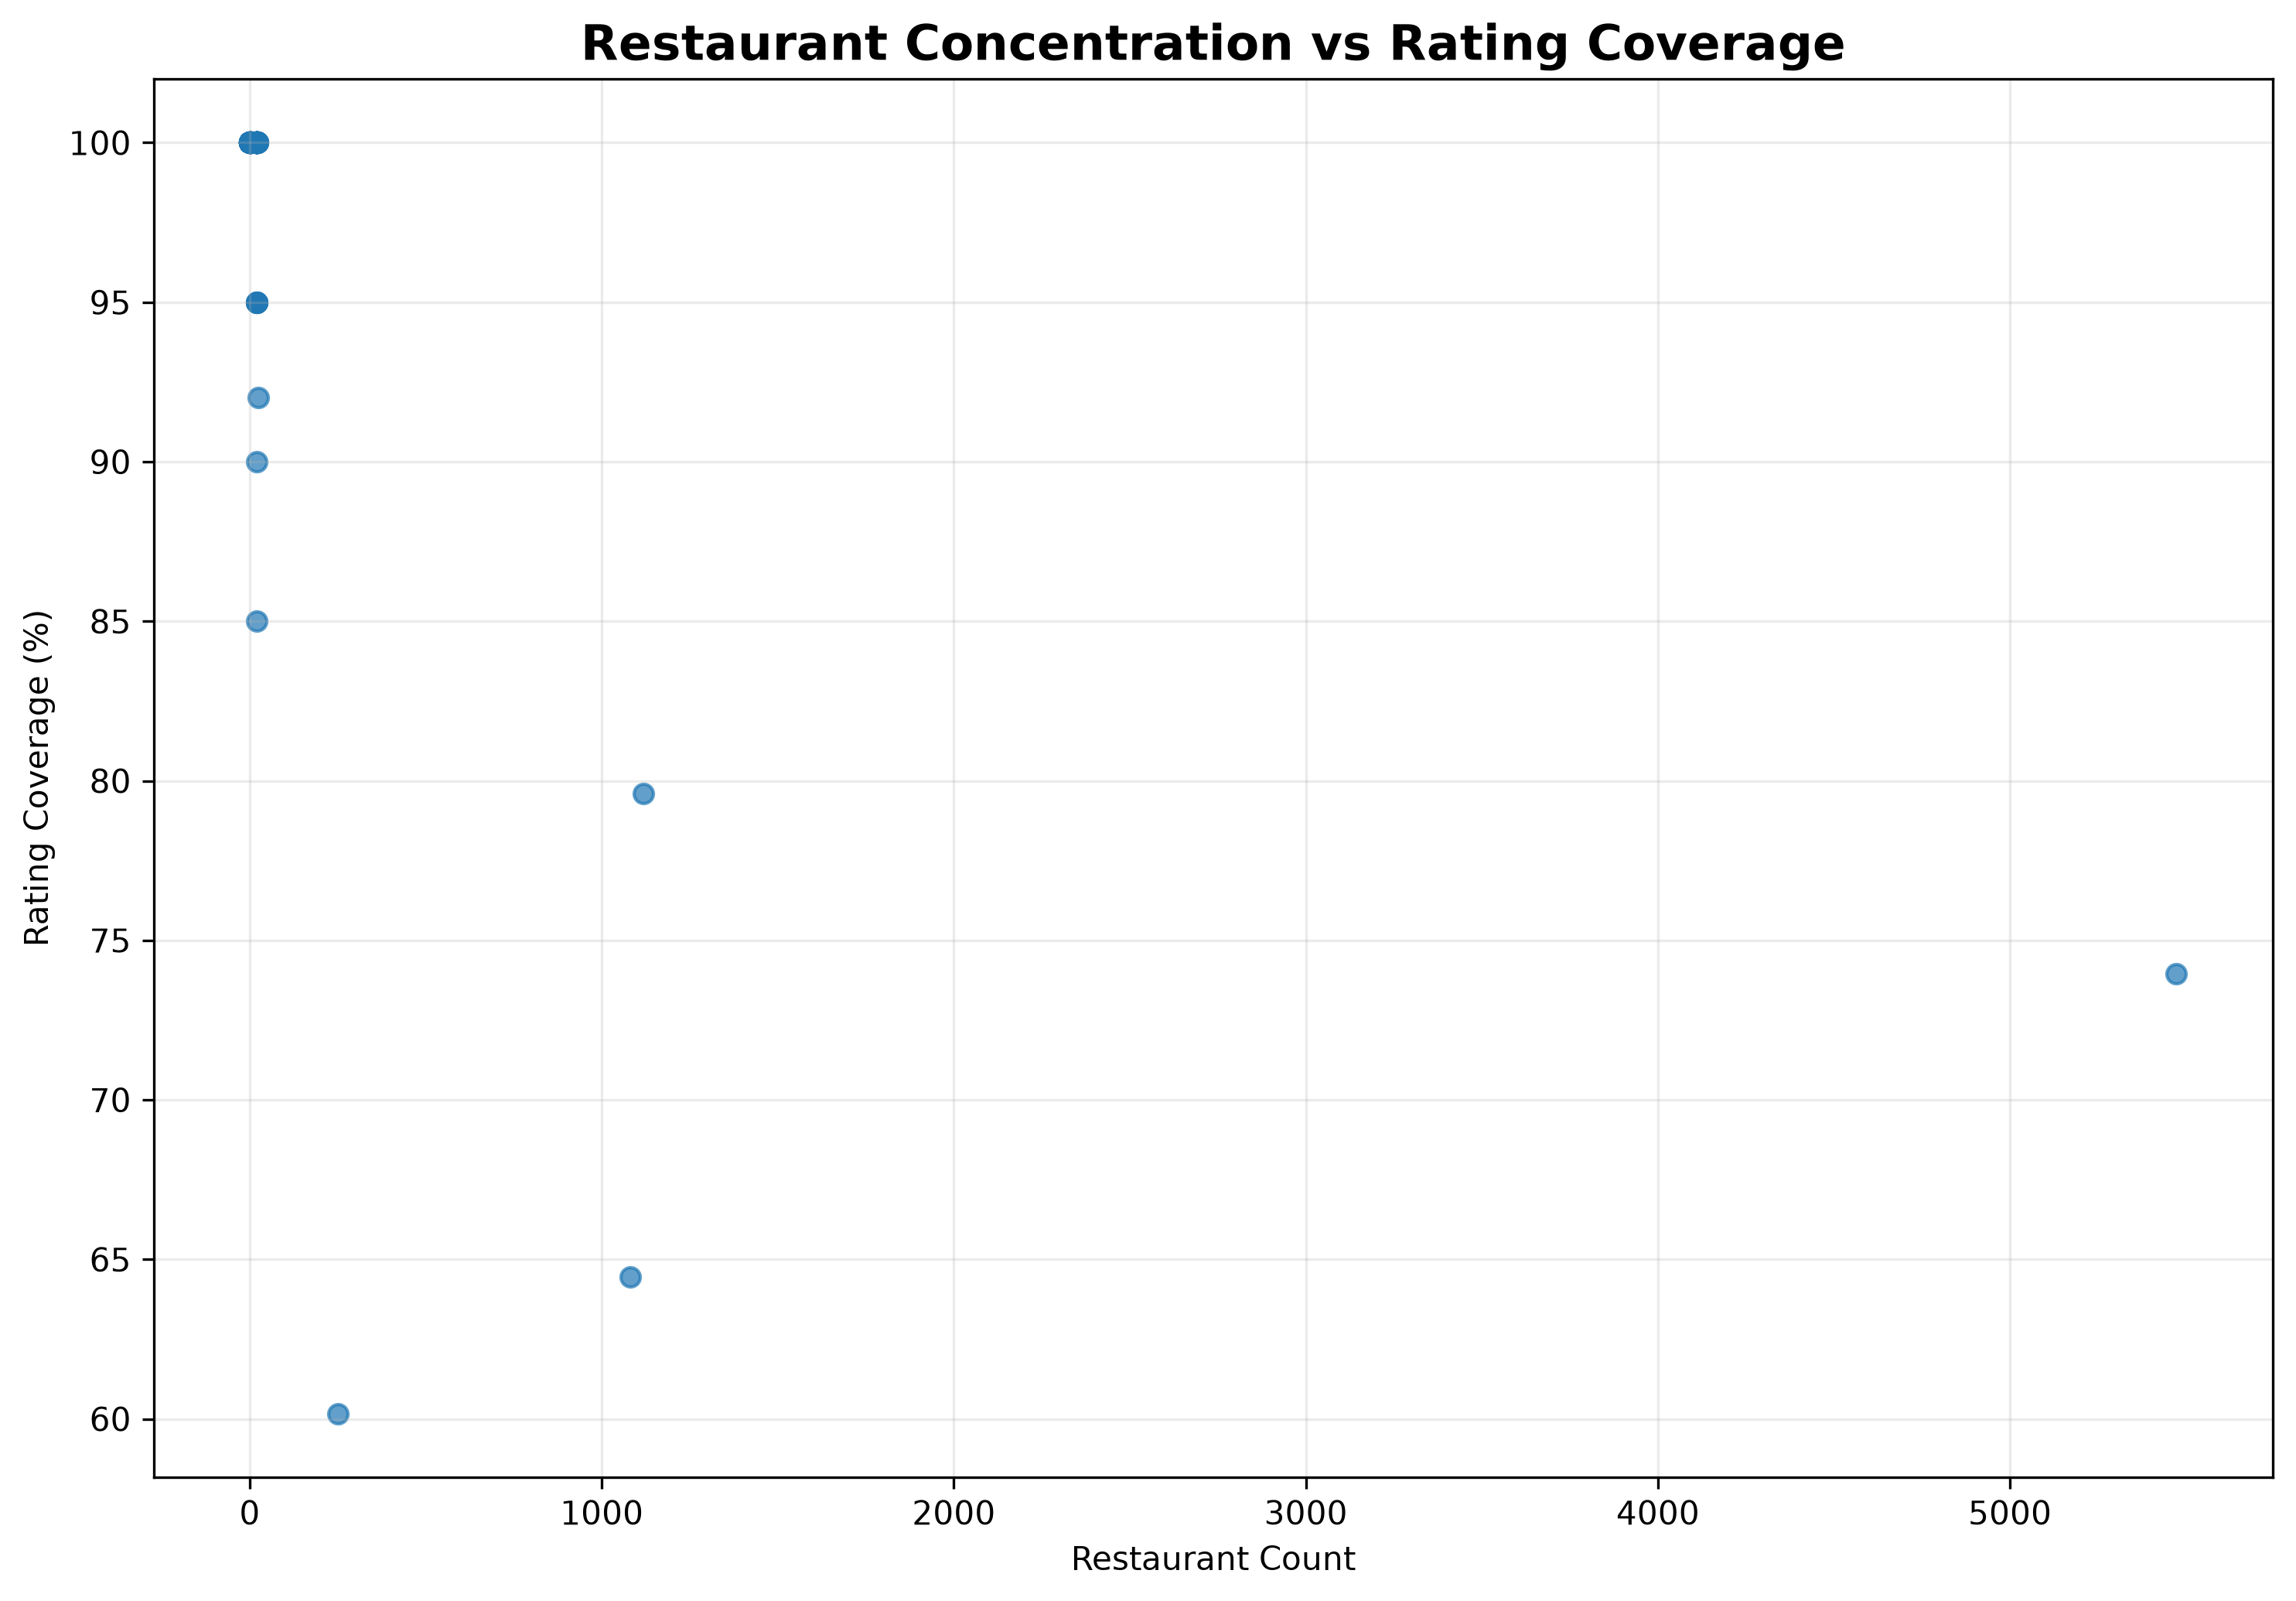

11_city_recommendation_ranking.png


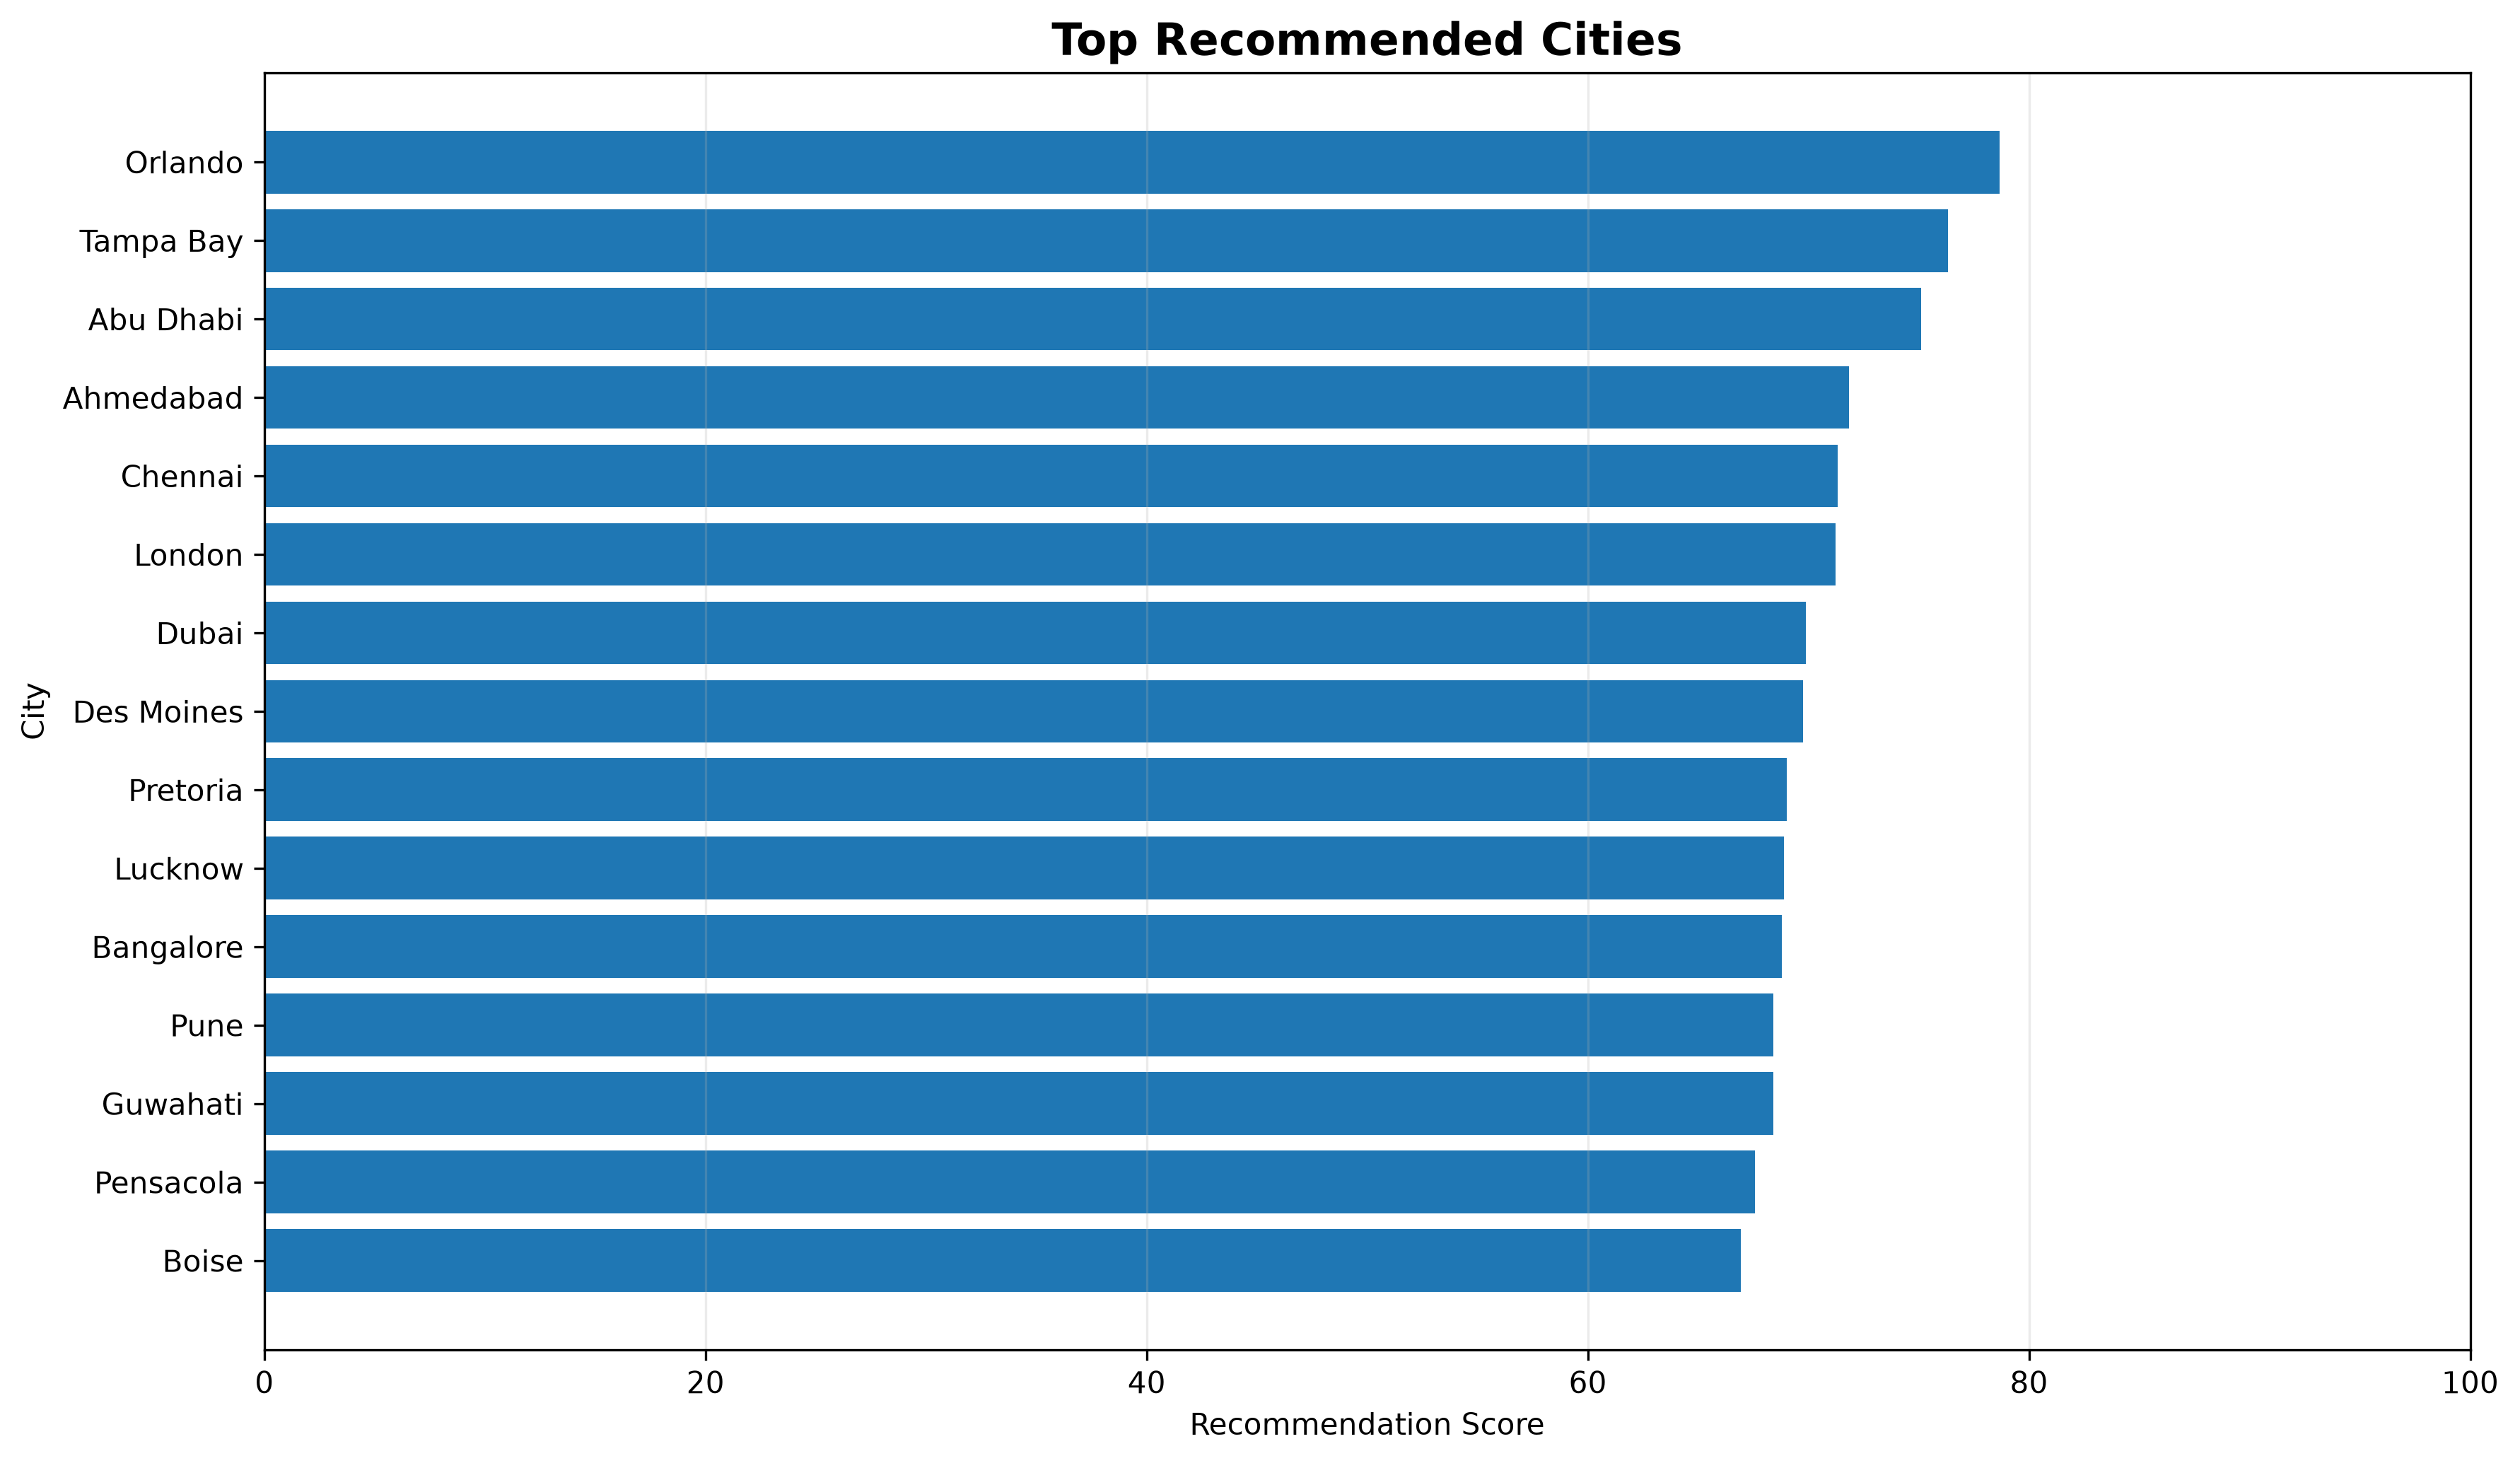

12_locality_recommendation_ranking.png


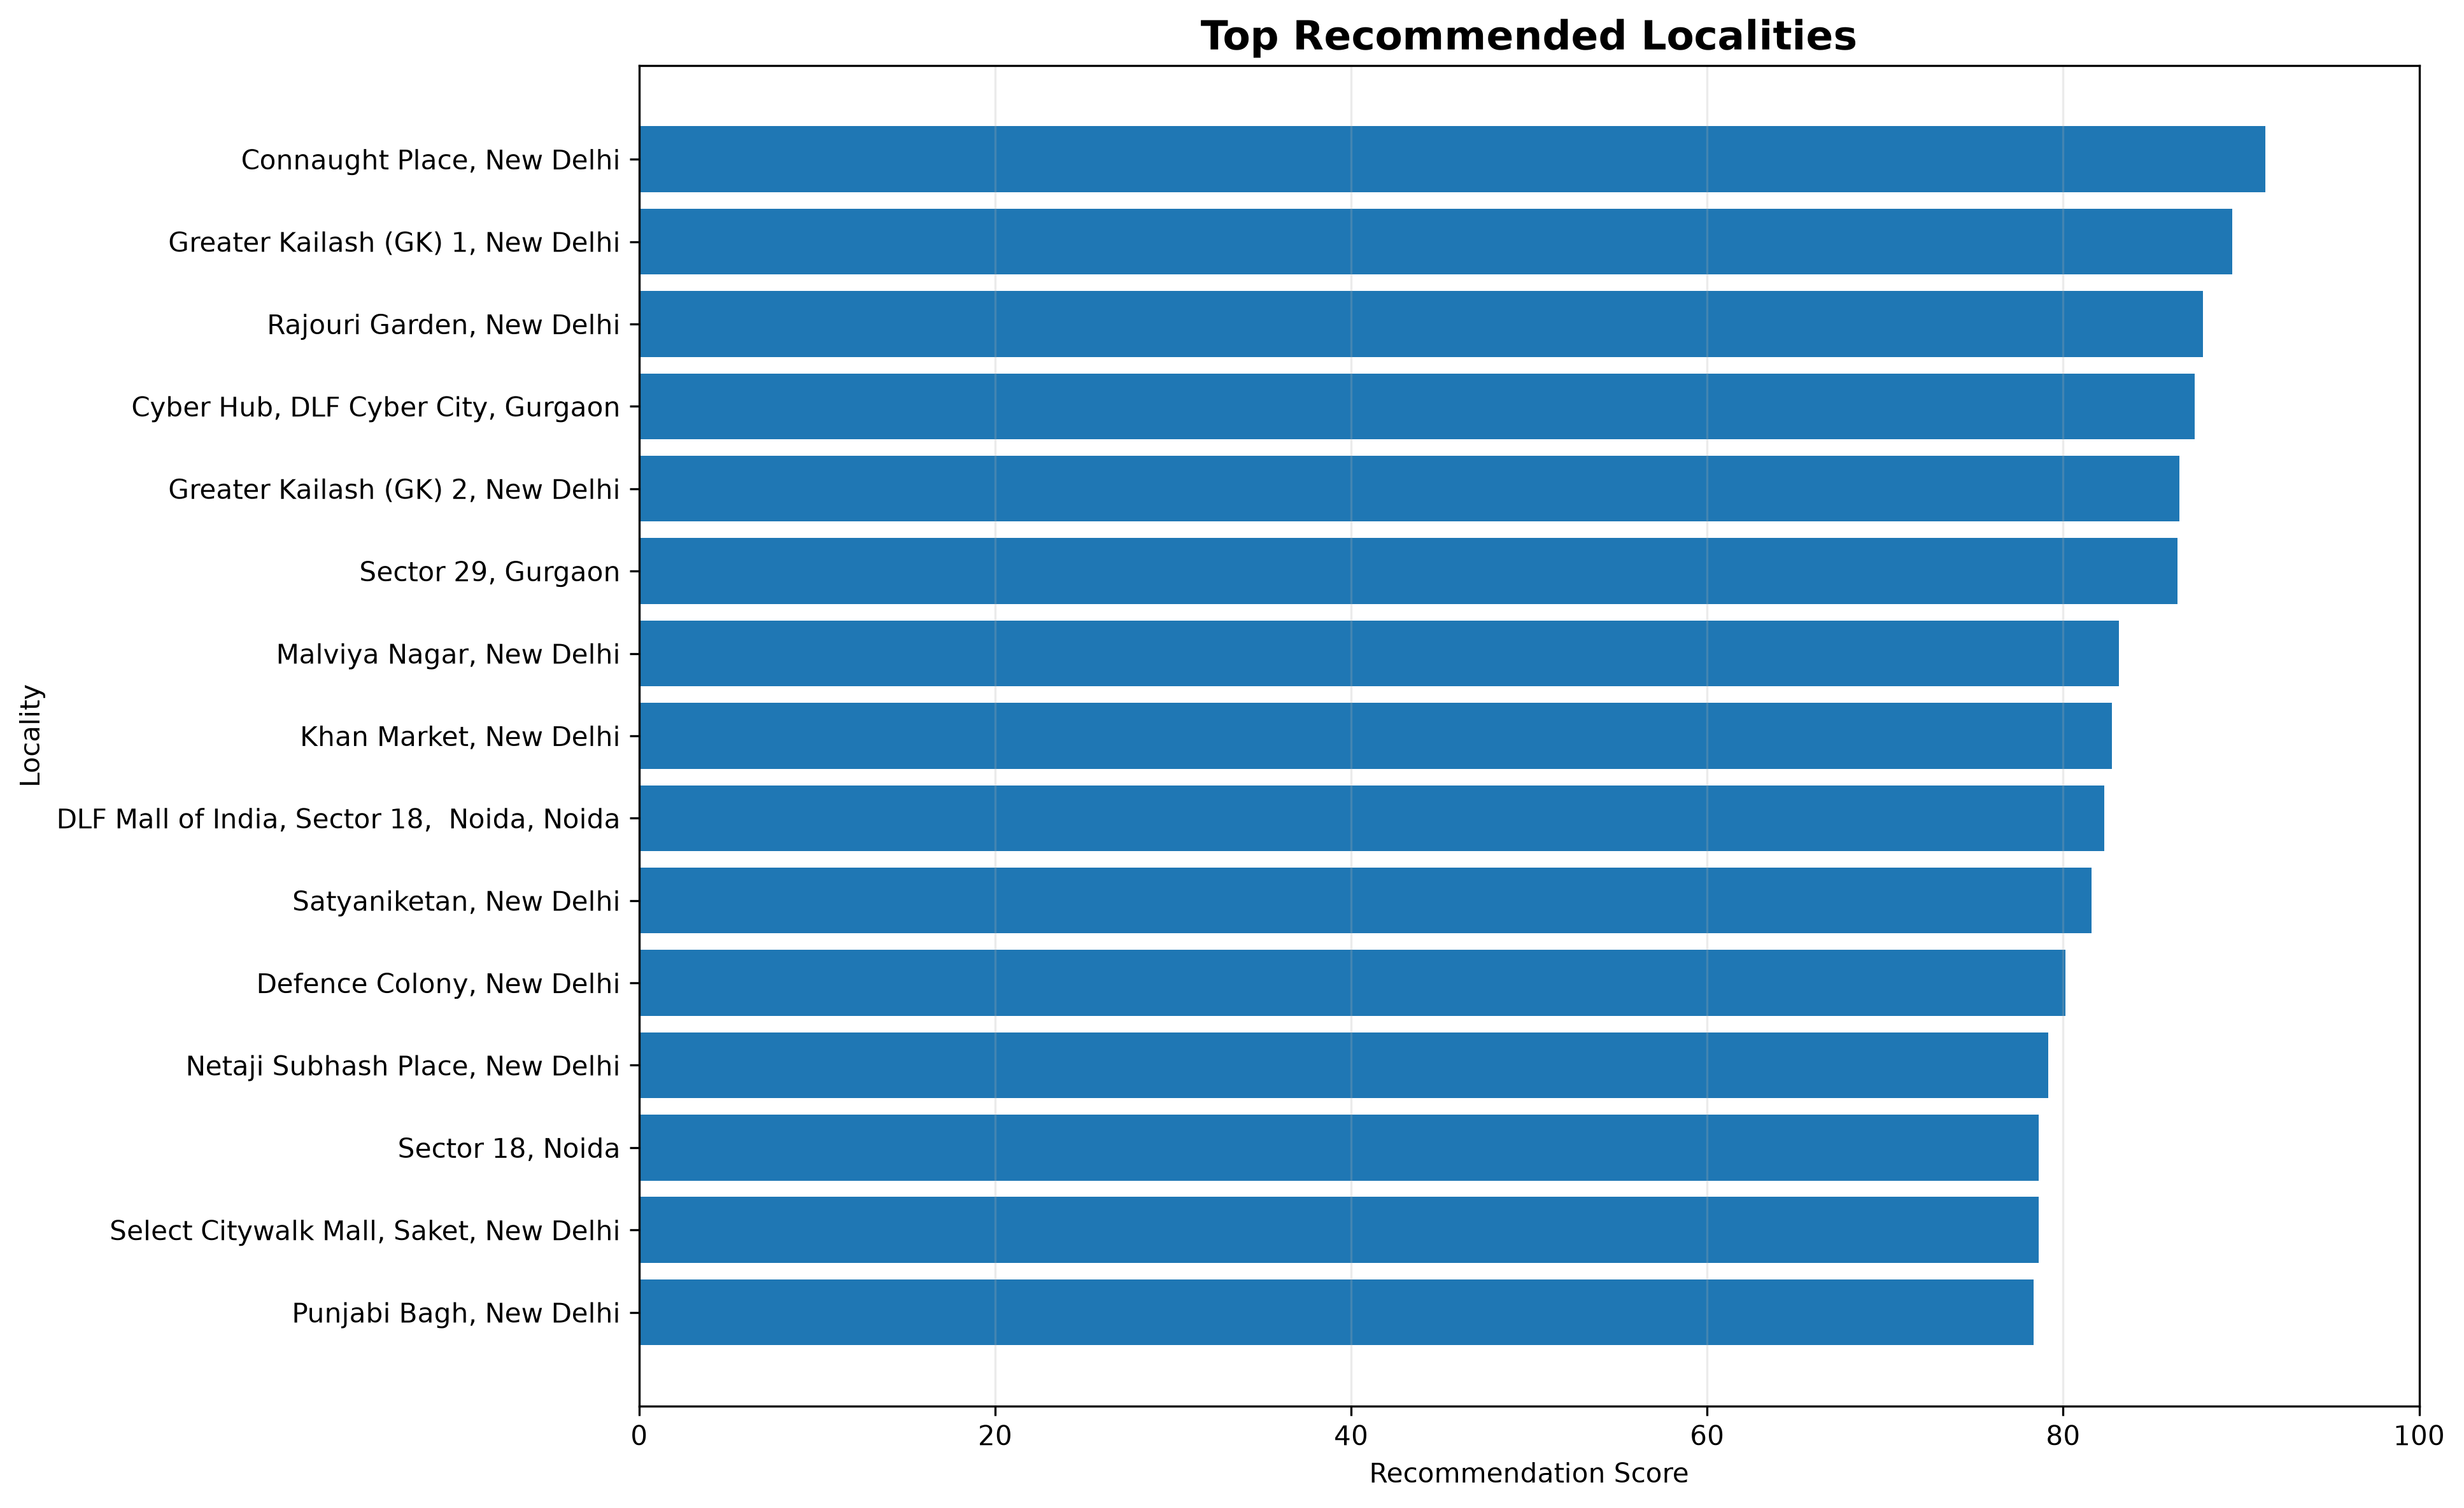

13_recommendation_component_analysis.png


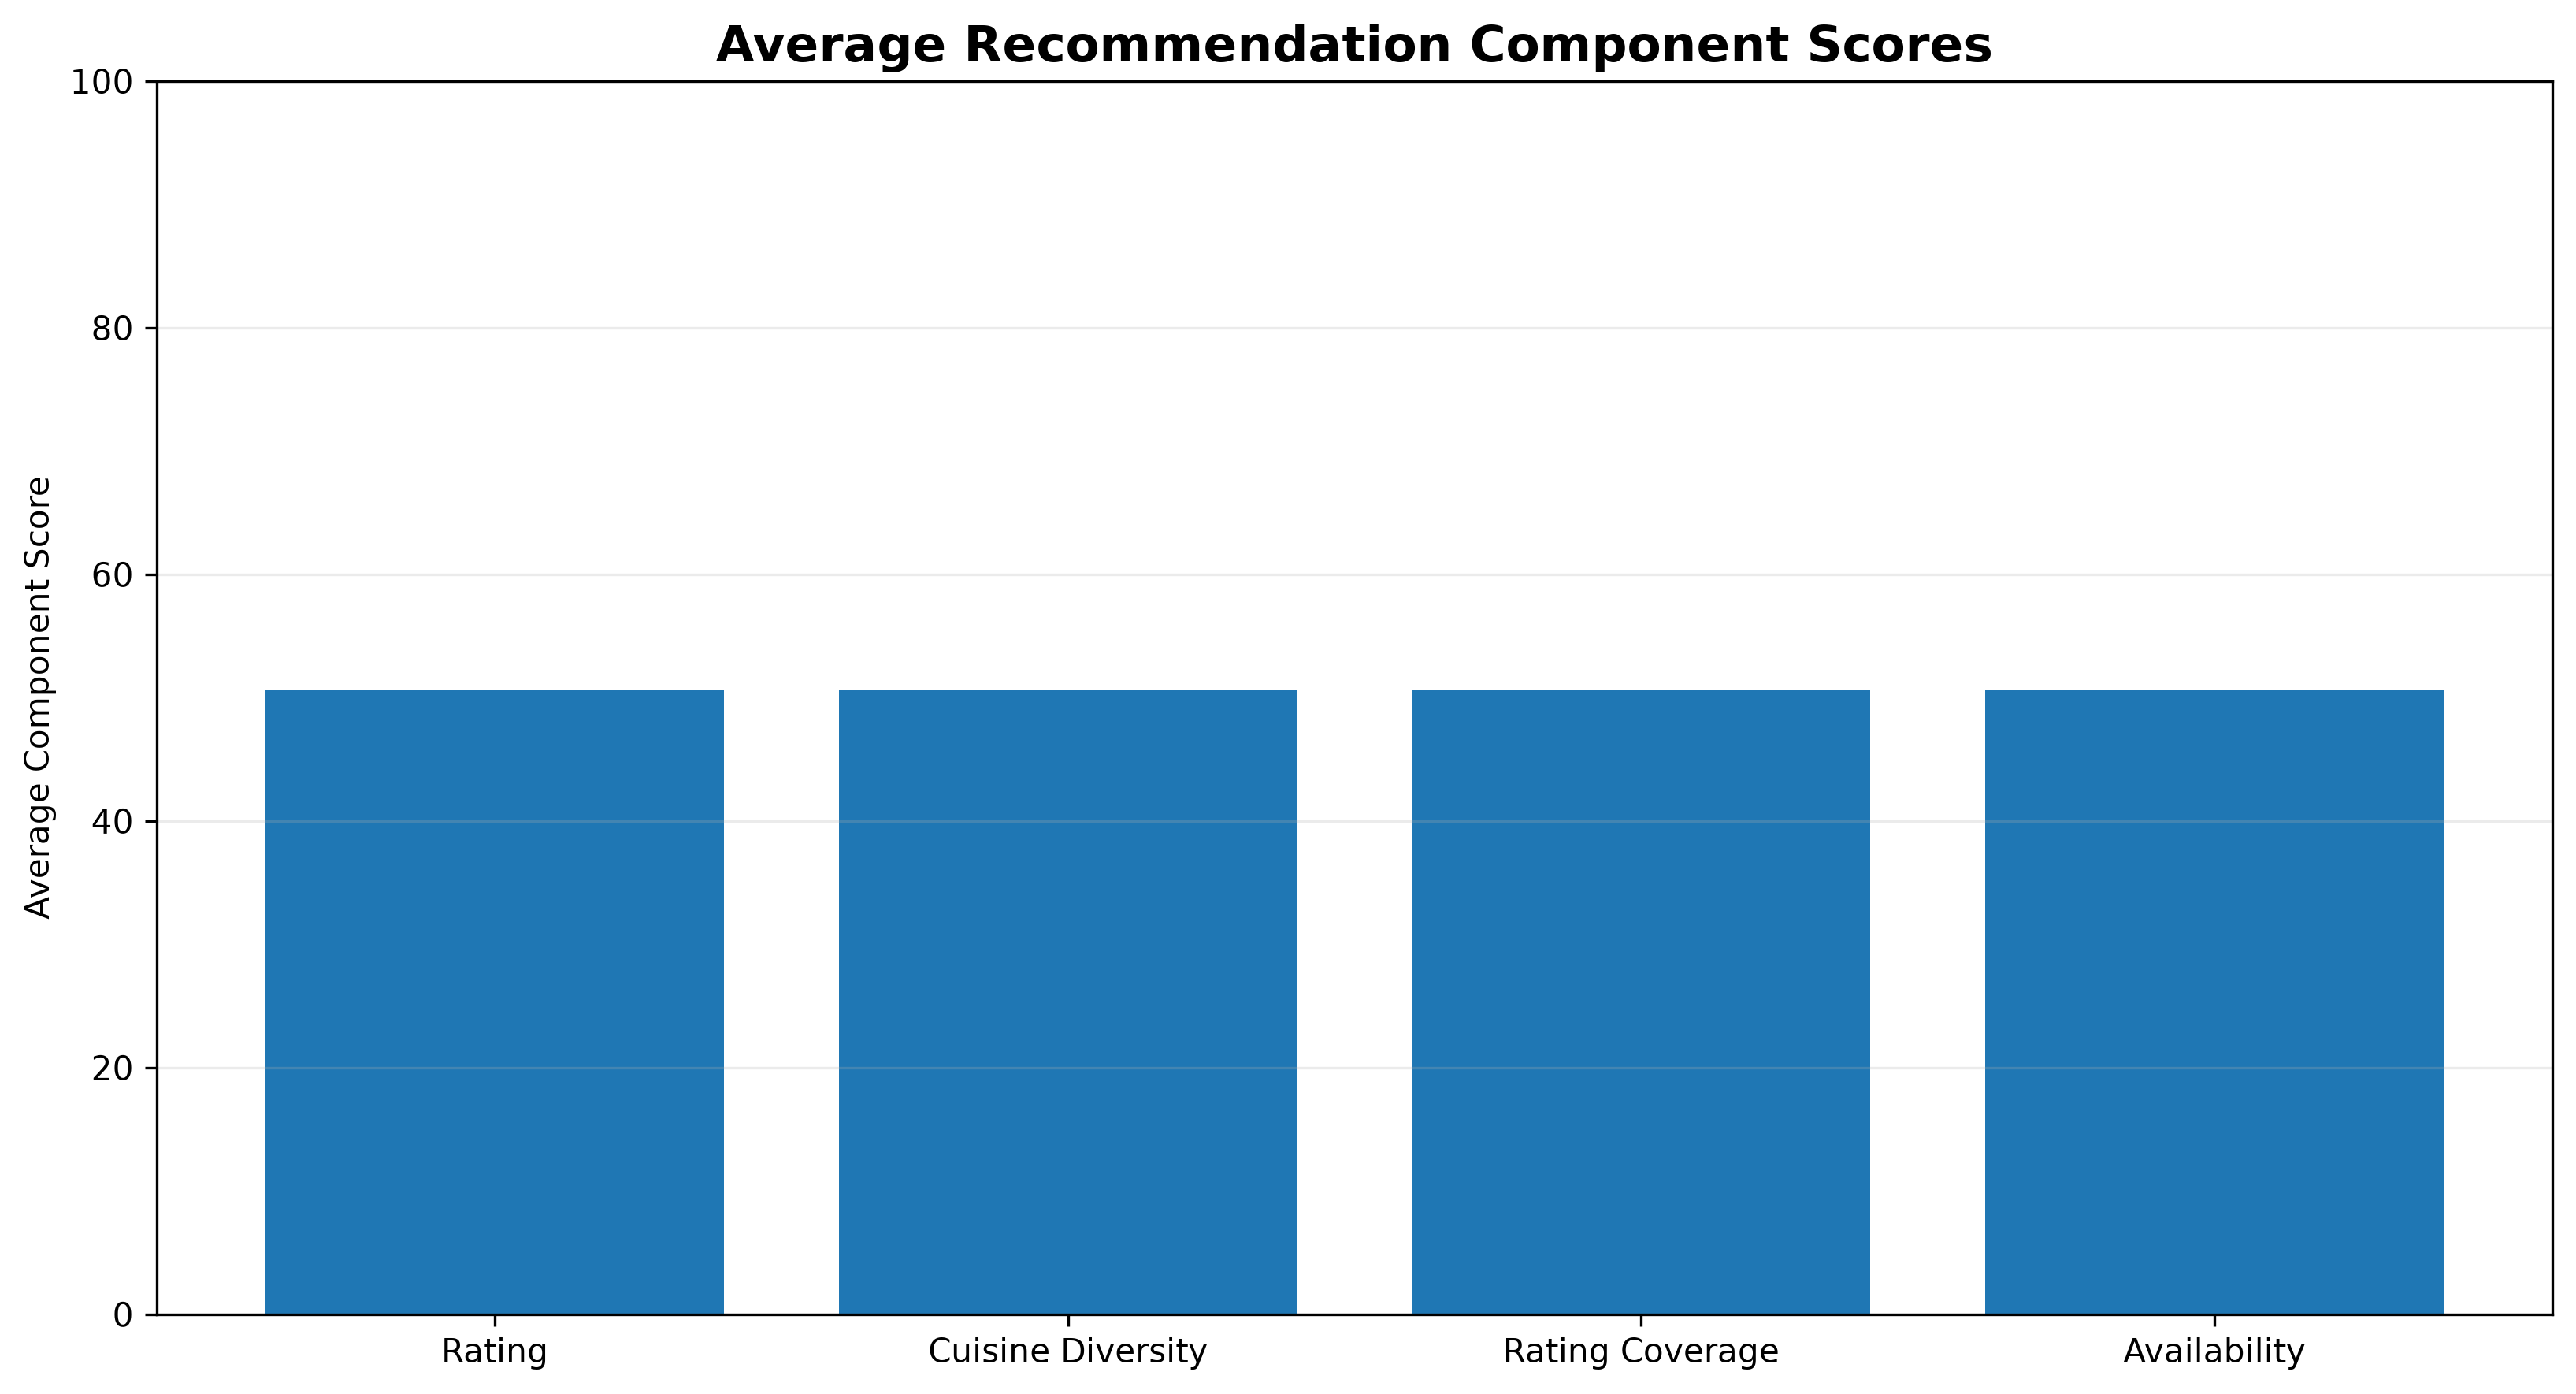

14_city_rating_shrinkage_comparison.png


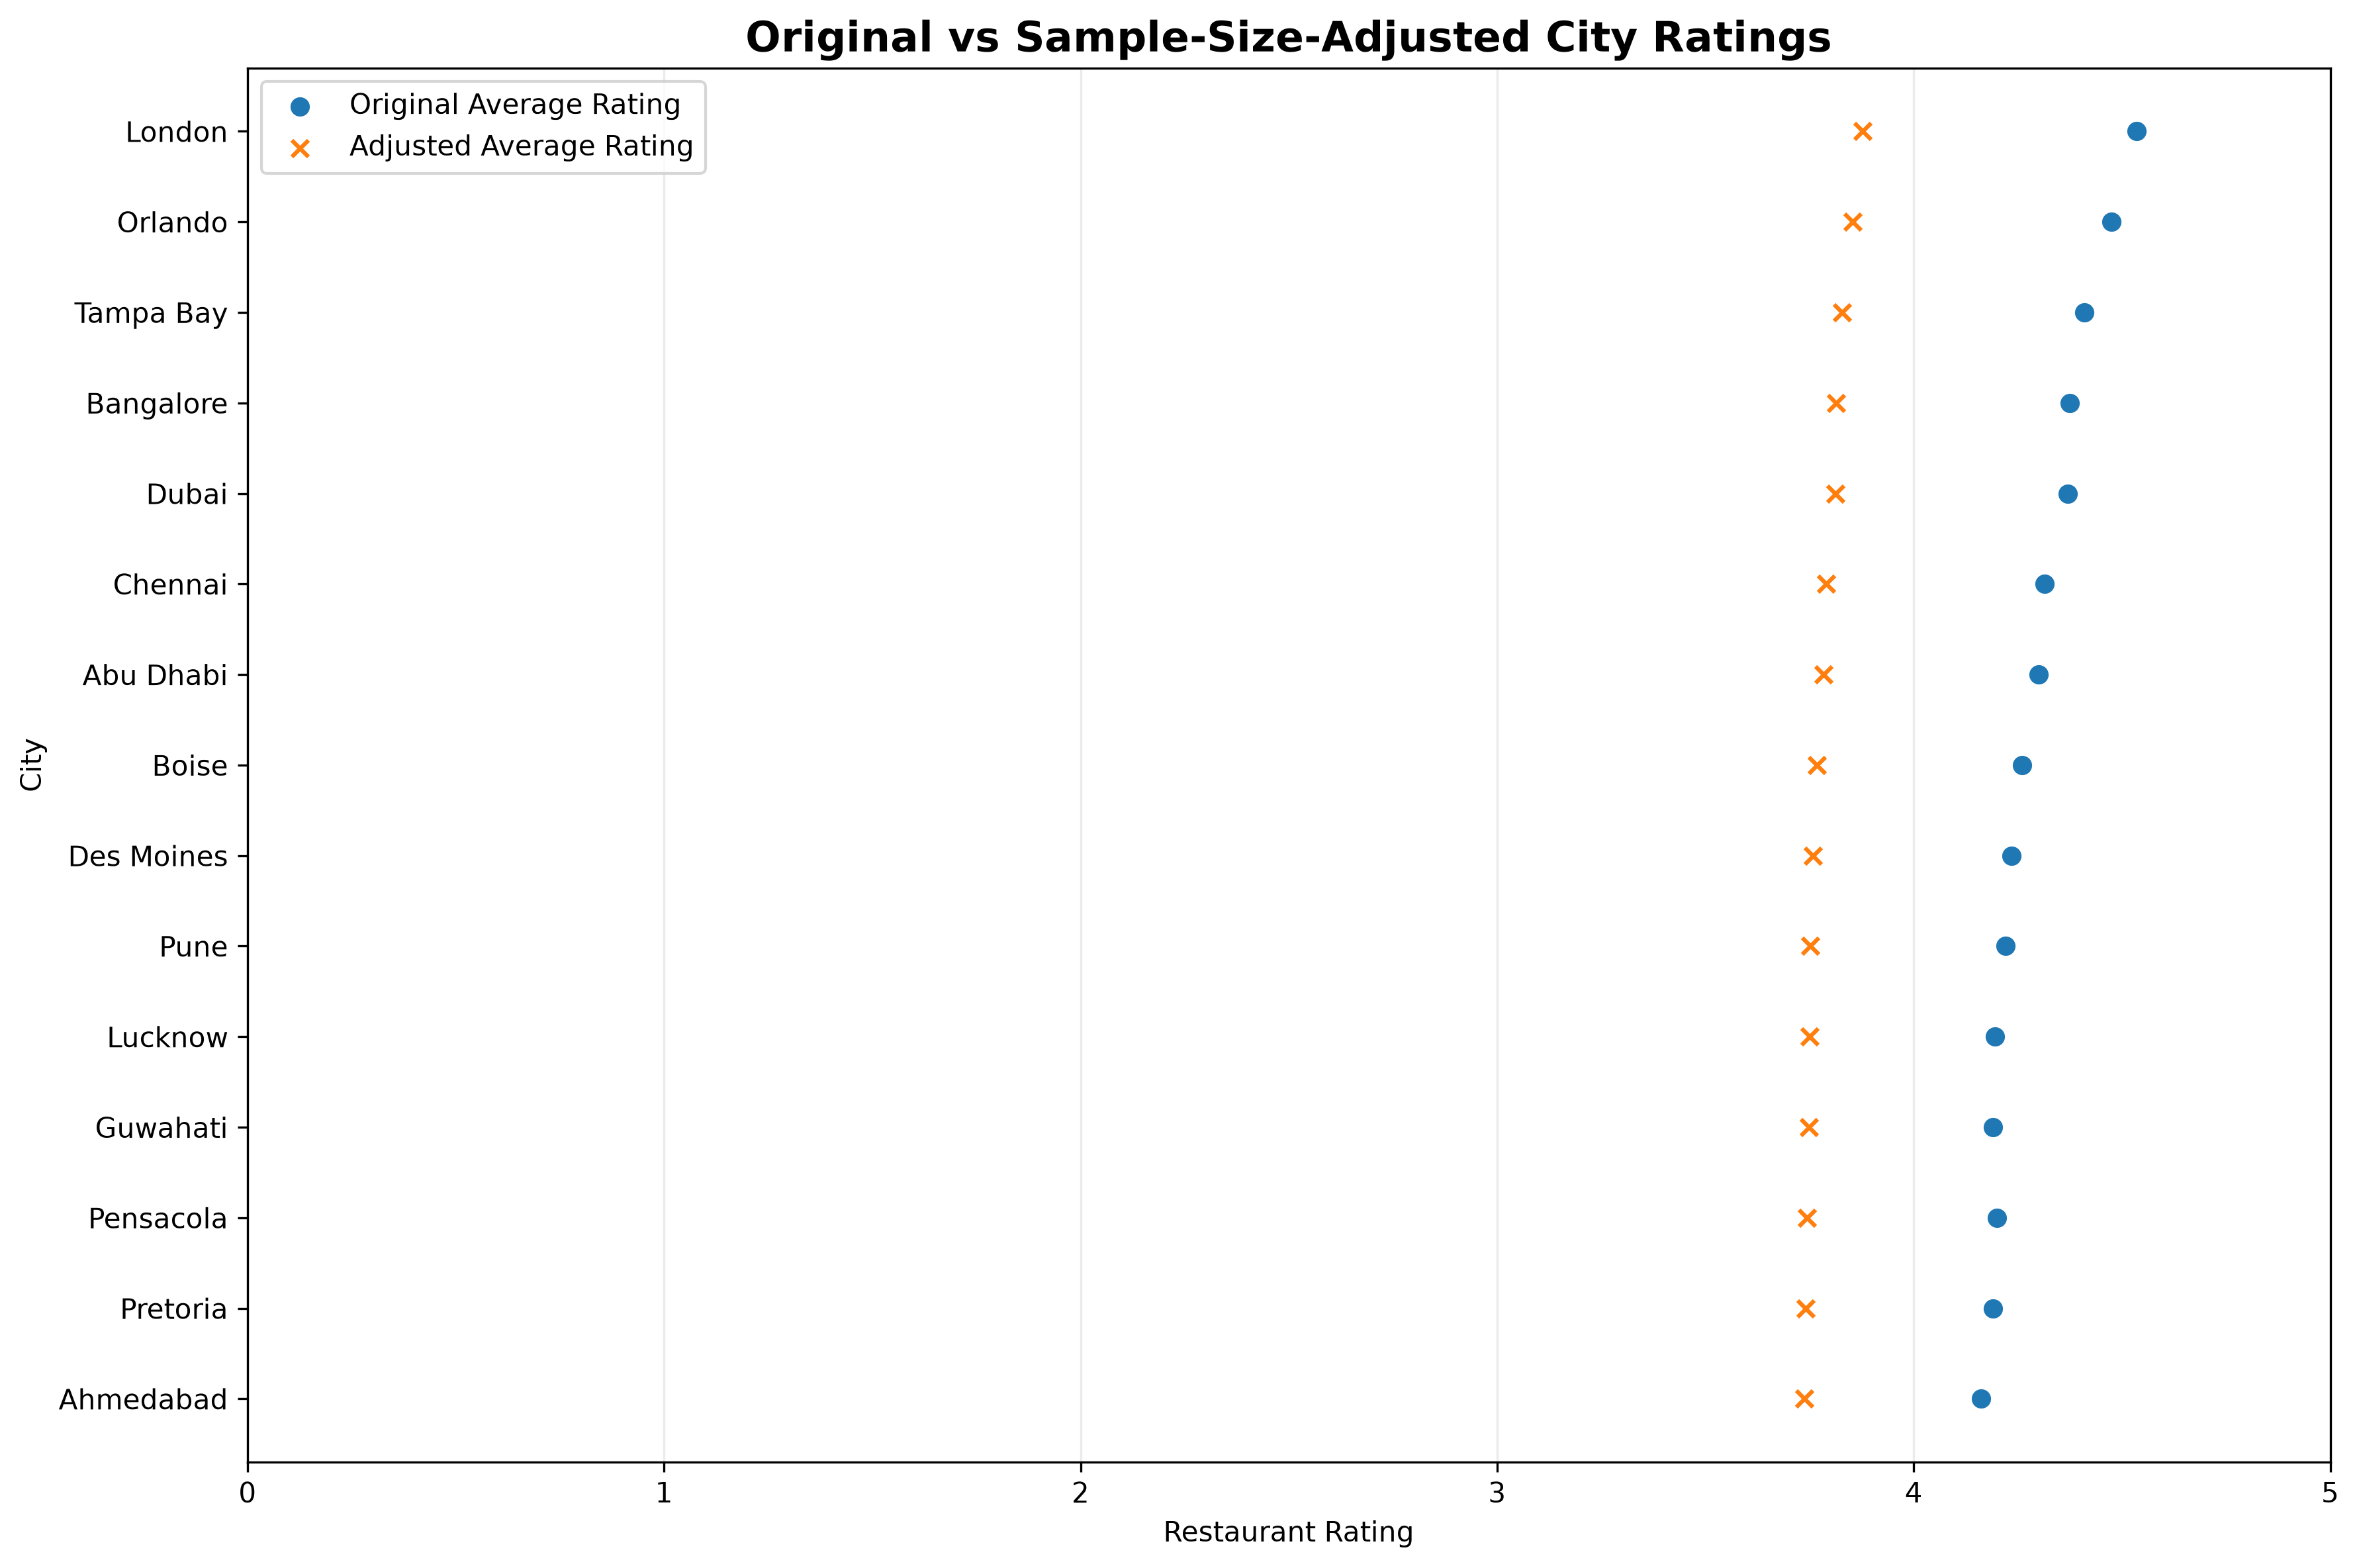

In [13]:
figure_names = [
    "01_global_restaurant_distribution.png",
    "02_india_restaurant_distribution.png",
    "03_city_geographical_distribution.png",
    "04_geographical_dbscan_clusters.png",
    "05_india_geographical_clusters.png",
    "06_coordinate_overlap_analysis.png",
    "07_city_rating_comparison.png",
    "08_price_rating_comparison.png",
    "09_cuisine_diversity_rating.png",
    "10_restaurant_concentration_rating_coverage.png",
    "11_city_recommendation_ranking.png",
    "12_locality_recommendation_ranking.png",
    "13_recommendation_component_analysis.png",
    "14_city_rating_shrinkage_comparison.png",
]

for filename in figure_names:
    path = FIGURES / filename
    if path.exists():
        print(filename)
        display(Image(filename=str(path)))
    else:
        print("Missing figure:", filename)

## 12. Final cross-program verification
The terminal audit previously checked artifact readability and numerical consistency across programs. This section repeats the principal record-count and output checks inside the notebook.

In [14]:
def safe_read(path):
    return pd.read_csv(path) if path.exists() else None

main = safe_read(DATA / "location_analysis_data.csv")
restaurant_features = safe_read(FEATURES / "restaurant_location_features.csv")
city_features = safe_read(FEATURES / "city_location_features.csv")
locality_features = safe_read(FEATURES / "locality_location_features.csv")
geospatial = safe_read(REPORTS / "restaurant_geospatial_clusters.csv")
suspicious = safe_read(REPORTS / "geospatial_suspicious_coordinates.csv")
city_recommendations = safe_read(REPORTS / "location_city_recommendations.csv")
locality_recommendations = safe_read(REPORTS / "location_locality_recommendations.csv")
city_statistics = safe_read(REPORTS / "location_statistical_city_ratings.csv")
locality_statistics = safe_read(REPORTS / "location_statistical_locality_ratings.csv")
tests = safe_read(REPORTS / "location_statistical_test_results.csv")
insights = safe_read(REPORTS / "location_decision_insights.csv")
configuration = safe_read(REPORTS / "location_recommendation_configuration.csv")

checks = {
    "Processed dataset contains 9,551 restaurants": main is not None and len(main) == 9551,
    "Restaurant features preserve all restaurant records": main is not None and restaurant_features is not None and len(restaurant_features) == len(main),
    "Processed restaurant IDs are unique": main is not None and main["Restaurant ID"].is_unique,
    "Restaurant feature IDs are unique": restaurant_features is not None and restaurant_features["Restaurant ID"].is_unique,
    "Usable and suspicious coordinate records account for all restaurants": main is not None and geospatial is not None and suspicious is not None and len(geospatial) + len(suspicious) == len(main),
    "City feature dataset contains 141 groups": city_features is not None and len(city_features) == 141,
    "City recommendations match city statistical eligibility": city_recommendations is not None and city_statistics is not None and len(city_recommendations) == len(city_statistics) == 82,
    "Locality feature dataset contains 1,265 groups": locality_features is not None and len(locality_features) == 1265,
    "Locality recommendations match locality statistical eligibility": locality_recommendations is not None and locality_statistics is not None and len(locality_recommendations) == len(locality_statistics) == 176,
    "Seven statistical tests are recorded": tests is not None and len(tests) == 7,
    "Four decision insights are recorded": insights is not None and len(insights) == 4,
    "Recommendation configuration contains four entries": configuration is not None and len(configuration) == 4,
    "Fourteen analysis figures are available": sum((FIGURES / name).is_file() for name in figure_names) == 14,
}

check_results = pd.DataFrame([
    {"Check": name, "Status": "PASS" if passed else "FAIL"}
    for name, passed in checks.items()
])
display(check_results)

passed = sum(checks.values())
failed = len(checks) - passed

print("=" * 75)
print("TASK 04 NOTEBOOK VERIFICATION SUMMARY")
print("=" * 75)
print("Total checks:", len(checks))
print("Passed:", passed)
print("Failed:", failed)

if failed == 0:
    print("\n[PASS] All notebook-level verification checks passed.")
else:
    print("\n[WARNING] Review the failed checks before finalizing Task 04.")

assert failed == 0

,Check,Status
0,"Processed dataset contains 9,551 restaurants",PASS
1,Restaurant features preserve all restaurant re...,PASS
2,Processed restaurant IDs are unique,PASS
3,Restaurant feature IDs are unique,PASS
4,Usable and suspicious coordinate records accou...,PASS
5,City feature dataset contains 141 groups,PASS
6,City recommendations match city statistical el...,PASS
7,"Locality feature dataset contains 1,265 groups",PASS
8,Locality recommendations match locality statis...,PASS
9,Seven statistical tests are recorded,PASS


TASK 04 NOTEBOOK VERIFICATION SUMMARY
Total checks: 13
Passed: 13
Failed: 0

[PASS] All notebook-level verification checks passed.


## 13. Conclusion

Task 4 — Location-Based Analysis — transforms restaurant-level records into location intelligence at global, country, city and locality levels. The workflow includes data auditing and preprocessing, location and cuisine feature engineering, geospatial exploration using DBSCAN, statistical analysis, weighted location recommendations and an interactive terminal explorer.

### Key findings
- The processed location dataset retains 9,551 restaurants.
- The dataset contains 141 cities and 1,265 city-locality groups.
- Geospatial analysis used 9,054 coordinate records and excluded 497 suspicious zero-coordinate records from spatial processing.
- DBSCAN identified 172 clusters, with 7,463 records assigned and 1,591 noise records.
- Statistical analysis produced seven tests; six were significant at the 0.05 level in the recorded run.
- The recommendation system ranked 82 eligible cities and 176 eligible localities.
- The interactive explorer supports location exploration, filtering, comparisons and custom shortlists.

### Limitations
1. Suspicious zero-coordinate records were excluded from spatial analysis.
2. Restaurant counts by locality are not area-normalized density because locality area data is unavailable.
3. Arithmetic mean coordinates are approximate group centers, not necessarily exact geographic centroids.
4. Statistical significance does not establish causation; small samples and unequal group sizes affect interpretation.
5. Global city rankings should not be interpreted as country-specific rankings.
6. Weighted recommendation scoring is rule-based decision support, not a trained predictive ML model.
7. Dataset redistribution and licensing permissions should be confirmed with the provider before publishing raw or processed data.

**Task 4 status:** The eight implementation programs have executed, the artifact-integrity audit passed (99/99), and the cross-program consistency audit passed (16/16). This notebook presents and independently rechecks the saved outputs.

## 14. Interactive Location Explorer — Custom Input Testing

### Objective
Test the interactive location explorer using custom location and restaurant-search inputs.

### Instructions
1. Open the VS Code integrated terminal.
2. Ensure the DineScope virtual environment is activated.
3. Execute the interactive location explorer.
4. Select the menu options and enter the requested location/search values.
5. Review the displayed results and saved CSV exports.
6. Verify that the session report is generated successfully.

### Execute the application

Run the following command from the DineScope project root:

```powershell
python src/task_4_location_analysis/08_interactive_location_explorer.py
```

### Suggested test cases

| Menu option | Test input |
|---|---|
| 1. Location Overview | No additional input |
| 2. Explore a City | `New Delhi` |
| 3. Explore a Locality | City: `New Delhi`; Locality: `Connaught Place` |
| 4. Advanced Restaurant Search | Country: `1`; City: `New Delhi`; Locality: `Connaught Place`; Cuisine: `North Indian`; Minimum rating: `4`; Price range: `1–3`; Minimum votes: `10` |
| 5. City Recommendation Explorer | `New Delhi` |
| 6. Locality Recommendation Explorer | City: `New Delhi`; Locality: `Connaught Place` |
| 7. Compare Two Cities | `New Delhi` and `Gurgaon` |
| 8. Custom Restaurant Shortlist | City: `New Delhi`; Cuisine: `North Indian`; Minimum rating: `4`; Maximum price range: `3`; Count: `10` |
| 9. Save Session Report | Save report |
| 0. Exit | Exit application |

### Expected outcome
- Display location overview and city/locality summaries.
- Filter restaurants using the selected criteria.
- Display city and locality recommendation rankings.
- Compare the selected cities.
- Generate a custom restaurant shortlist.
- Save interactive CSV exports and a session report.

**Note:** This application is a terminal-based analytics explorer. It reads the processed datasets and recommendation outputs generated by the earlier Task 4 programs; it does not train a machine-learning model.